# スナップショット (時刻を固定した解析)

このノートブックのモデルと範囲は `thesis_common.ipynb` で指定する。変更したら先頭のセルから実行し直す。

コメント中の `cell N` は分割前の `thesis.ipynb` の番号で、各セルの1行目の `[旧 cell N]` と対応する。

# file_gas
# r_cen_[i] :0 sigmag_[i] :1 sigmad_tot_[i] :2 sigmad_vapor : 3 vg_r_[i] : 4 vg_phi_[i] :5 vg_wind_[i] :6 vd_r_tot[i][0] : 7 
# lambda1_[i]: 8 lambda2_[i] :9 dsigmagdt_w[i]:10 T_[i]:11 P_[i][nz_s] : 12 P_[i][nz_s]/beta_disk_[i][nz_s] : 13 Q_toomre[i] : 14 alpha_GI[i] : 15  
# alpha_phiz[i] : 16 alpha_tot[i] : 17 eta_P_[i] :18
# file_mag
# r_cen_[i] :0 alpha_MRI[i]:1 B_[i]:2 etaO_R[i]:3 etaA_R[i]:4 beta_disk_[i][nz_s]:5

In [1]:
# 共通設定を読み込む (モデルや範囲は thesis_common.ipynb で変更する)
import json

def run_nb(path):
    # 別のノートブックのコードセルをこのノートブックの変数空間で実行する
    for c in json.load(open(path))["cells"]:
        if c["cell_type"] == "code":
            exec("".join(c["source"]), globals())

run_nb("thesis_common.ipynb")

In [2]:
# ===== スナップショットの設定 (時刻はここだけ変える) =====
SNAP_YEARS = [0, 1000, 10000, 55000]   # 複数時刻を比べる図の 4 時刻 [yr]
SNAP_COLORS = ["red", "orange", "green", "blue"]
SNAP_YEAR = 55000                      # 1 時刻だけの図の時刻 [yr]

def snap_label(year):
    # 例: 1000 -> $1.00\times10^{3}\ \rm{yr}$
    if year == 0:
        return r"$0\ \rm{yr}$"
    n = int(np.floor(np.log10(year)))
    return r"${:.2f}\times10^{{{}}}\ \rm{{yr}}$".format(year / 10**n, n)

_missing = [y for y in SNAP_YEARS + [SNAP_YEAR] if not os.path.exists("{}{}/out{}".format(BASE_DIR, MODEL, y))]
if _missing:
    raise FileNotFoundError("{} に out{} がありません (最新は out{})".format(MODEL, _missing, list_years(BASE_DIR + MODEL)[-1]))

## 動径プロファイル

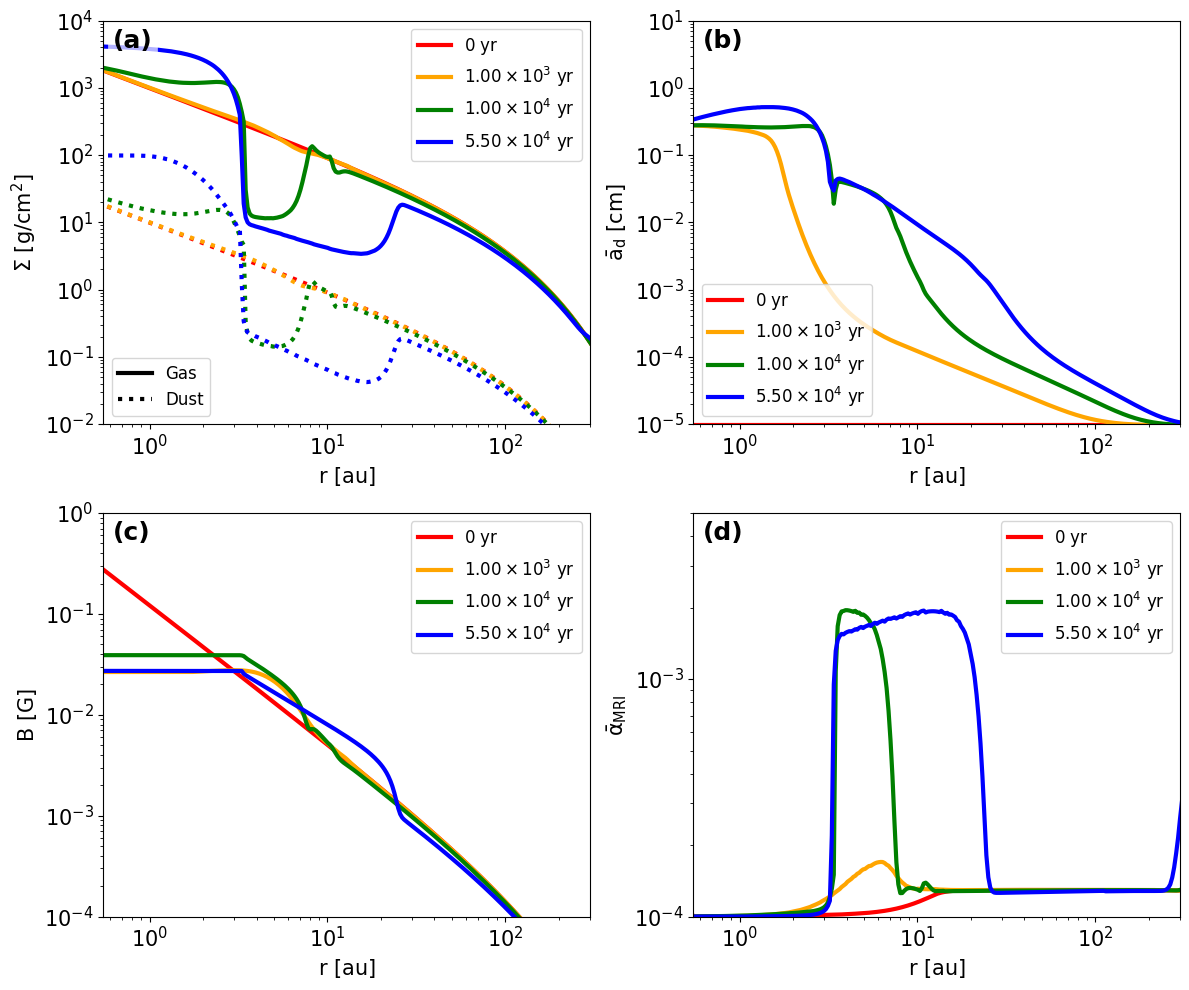

In [3]:
# [旧 cell 1]
# #################### fragmetation velocity = 30m/s########################
# ##################### Wind ありの場合のモデル化 ################### 
outdir = BASE_DIR
resultdir = MODEL
file0_3430 = "/out{}".format(SNAP_YEARS[0])
file1_3430 = "/out{}".format(SNAP_YEARS[0])
file2_3430 = "/out{}".format(SNAP_YEARS[1])
file3_3430 = "/out{}".format(SNAP_YEARS[2])
file4_3430 = "/out{}".format(SNAP_YEARS[2])
file5_3430 = "/out{}".format(SNAP_YEARS[3])

file0 = outdir + resultdir + file0_3430
file1 = outdir + resultdir + file1_3430
file2 = outdir + resultdir + file2_3430
file3 = outdir + resultdir + file3_3430
file4 = outdir + resultdir + file4_3430
file5 = outdir + resultdir + file5_3430

dmass = np.array([float(i) for i in linecache.getline(file1, 1).split()])
dmass_b = np.array([float(i) for i in linecache.getline(file1, 2).split()])
delta_mass = dmass_b[1:] - dmass_b[:-1]
dradius = np.array([float(i) for i in linecache.getline(file1, 3).split()])
dradius_b = np.array([float(i) for i in linecache.getline(file1, 4).split()])
linecache.clearcache()

data0 = np.loadtxt(file0, dtype=float, skiprows=5).T
data1 = np.loadtxt(file1, dtype=float, skiprows=5).T
data2 = np.loadtxt(file2, dtype=float, skiprows=5).T
data3 = np.loadtxt(file3, dtype=float, skiprows=5).T
data4 = np.loadtxt(file4, dtype=float, skiprows=5).T
data5 = np.loadtxt(file5, dtype=float, skiprows=5).T

sigmad0 = data0[1:]
sigmad1 = data1[1:]
sigmad2 = data2[1:]
sigmad3 = data3[1:]
sigmad4 = data4[1:]
sigmad5 = data5[1:]

r = data1[0]

# FigureとAxesの作成
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# X軸（r/AU）

# r_min = r[0]/AU
# r_max = 1.0e3

X = r / AU

file_gas = "_gas"
data0_gas = np.loadtxt(file0+file_gas, dtype=float).T
data1_gas = np.loadtxt(file1+file_gas, dtype=float).T
data2_gas = np.loadtxt(file2+file_gas, dtype=float).T
data3_gas = np.loadtxt(file3+file_gas, dtype=float).T
data4_gas = np.loadtxt(file4+file_gas, dtype=float).T
data5_gas = np.loadtxt(file5+file_gas, dtype=float).T

axes[0, 0].set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
axes[0, 0].set_ylabel(r"$\Sigma \ \rm{[g/cm^2]}$", fontsize=15)

axes[0, 0].set_xscale("log")
axes[0, 0].set_yscale("log")
axes[0, 0].set_xlim(r_min, r_max)
axes[0, 0].set_ylim(1.0e-2,1.0e4)

# axes[0, 0].set_xlim(0.0,1.0e2)
# axes[0, 0].set_ylim(0.0,1.0e2)

axes[0, 0].tick_params(labelsize=15)

# ---- 実線=ガス ----
axes[0, 0].plot(X, data0_gas[1,:], color=SNAP_COLORS[0],   linestyle="solid",  lw=3)
axes[0, 0].plot(X, data2_gas[1,:], color=SNAP_COLORS[1],linestyle="solid",  lw=3)
axes[0, 0].plot(X, data3_gas[1,:], color=SNAP_COLORS[2], linestyle="solid",  lw=3)
axes[0, 0].plot(X, data5_gas[1,:], color=SNAP_COLORS[3],  linestyle="solid",  lw=3)

# ---- 点線=ダスト ----
axes[0, 0].plot(X, data0_gas[2,:]- data0_gas[3,:], color=SNAP_COLORS[0], linestyle="dotted", lw=3)
axes[0, 0].plot(X, data2_gas[2,:]- data2_gas[3,:], color=SNAP_COLORS[1], linestyle="dotted", lw=3)
axes[0, 0].plot(X, data3_gas[2,:]- data3_gas[3,:], color=SNAP_COLORS[2], linestyle="dotted", lw=3)
axes[0, 0].plot(X, data5_gas[2,:]- data5_gas[3,:], color=SNAP_COLORS[3], linestyle="dotted", lw=3)

# # # # # ---- 破線=蒸発ダスト ----
# axes[0, 0].plot(X, data0_gas[3,:], color="red", linestyle="dashed", lw=3)
# axes[0, 0].plot(X, data2_gas[3,:], color="orange", linestyle="dashed", lw=3)
# axes[0, 0].plot(X, data3_gas[3,:], color="green", linestyle="dashed", lw=3)
# axes[0, 0].plot(X, data5_gas[3,:], color="blue", linestyle="dashed", lw=3)

# ---- 凡例1（時間=色） ----
legend_time = [
    Line2D([0],[0], color=SNAP_COLORS[0],    lw=3, label=snap_label(SNAP_YEARS[0])),
    Line2D([0],[0], color=SNAP_COLORS[1], lw=3, label=snap_label(SNAP_YEARS[1])),
    Line2D([0],[0], color=SNAP_COLORS[2],  lw=3, label=snap_label(SNAP_YEARS[2])),
    Line2D([0],[0], color=SNAP_COLORS[3],   lw=3, label=snap_label(SNAP_YEARS[3])),
]
# leg1 = axes[0,0].legend(handles=legend_time,title="Time (color)", loc="upper right", fontsize=12)
leg1 = axes[0,0].legend(handles=legend_time, fontsize=12,loc="upper right")
axes[0,0].add_artist(leg1)  # ← 1つ目を保持

# ---- 凡例2（種類=線種） ----
legend_species = [
    Line2D([0],[0], color="black", lw=3, linestyle="solid",  label="Gas"),
    Line2D([0],[0], color="black", lw=3, linestyle="dotted", label="Dust"),
    # Line2D([0],[0], color="black", lw=3, linestyle="dashed", label="Vapor Dust"),
]

# axes[0,0].legend(handles=legend_species, title="Species (linestyle)", loc="lower left", fontsize=12)
axes[0,0].legend(handles=legend_species, fontsize=12,loc="lower left")

# Mean dust size (右上)
amean0_d = [] 
amean1_d = [] 
amean2_d = [] 
amean3_d = [] 
amean4_d = [] 
amean5_d = [] 

for j in range(len(r)):
    sig_d = 0.0
    amean = 0.0
    for i in range(len(sigmad1[:,0])):
        sig_d += sigmad0[i,j]
        amean += dradius[i]*sigmad0[i,j]
    amean = amean/sig_d
    amean0_d.append(amean)

# for j in range(len(r)):
#     sig_d = 0.0
#     amean = 0.0
#     for i in range(len(sigmad1[:,0])):
#         sig_d += sigmad1[i,j]
#         amean += dradius[i]*sigmad1[i,j]
#     amean = amean/sig_d
#     amean1_d.append(amean)

for j in range(len(r)):
    sig_d = 0.0
    amean = 0.0
    for i in range(len(sigmad2[:,0])):
        sig_d += sigmad2[i,j]
        amean += dradius[i]*sigmad2[i,j]
    amean = amean/sig_d
    amean2_d.append(amean)

for j in range(len(r)):
    sig_d = 0.0
    amean = 0.0
    for i in range(len(sigmad3[:,0])):
        sig_d += sigmad3[i,j]
        amean += dradius[i]*sigmad3[i,j]
    amean = amean/sig_d
    amean3_d.append(amean)

for j in range(len(r)):
    sig_d = 0.0
    amean = 0.0
    for i in range(len(sigmad4[:,0])):
        sig_d += sigmad4[i,j]
        amean += dradius[i]*sigmad4[i,j]
    amean = amean/sig_d
    amean4_d.append(amean)

for j in range(len(r)):
    sig_d = 0.0
    amean = 0.0
    for i in range(len(sigmad5[:,0])):
        sig_d += sigmad5[i,j]
        amean += dradius[i]*sigmad5[i,j]
    amean = amean/sig_d
    amean5_d.append(amean)

axes[0, 1].set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
axes[0, 1].set_ylabel(r"$ \rm{\bar{a}_d} \ \rm{[cm]}$", fontsize=15)
axes[0, 1].set_xscale("log")
axes[0, 1].set_xlim(r_min,r_max)
axes[0, 1].set_yscale("log")
axes[0, 1].tick_params(labelsize=15)
axes[0, 1].set_ylim(1.0e-5, 1.0e1)

axes[0, 1].plot(X, amean0_d, color=SNAP_COLORS[0], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[0]))
axes[0, 1].plot(X, amean2_d, color=SNAP_COLORS[1], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[1]))
axes[0, 1].plot(X, amean3_d, color=SNAP_COLORS[2], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[2]))
axes[0, 1].plot(X, amean5_d, color=SNAP_COLORS[3], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[3]))

axes[0, 1].legend(fontsize=12, loc="lower left")

resultdir += "_B"

file0 =  outdir + resultdir + file0_3430 + "_B"
file1 =  outdir + resultdir + file1_3430 + "_B"
file2 =  outdir + resultdir + file2_3430 + "_B"
file3 =  outdir + resultdir + file3_3430 + "_B"
file4 =  outdir + resultdir + file4_3430 + "_B"
file5 =  outdir + resultdir + file5_3430 + "_B"

data0 = np.loadtxt(file0, dtype=float).T
data1 = np.loadtxt(file1, dtype=float).T
data2 = np.loadtxt(file2, dtype=float).T
data3 = np.loadtxt(file3, dtype=float).T
data4 = np.loadtxt(file4, dtype=float).T
data5 = np.loadtxt(file5, dtype=float).T

# Magnetic Field (左下)
# axes[0, 1].set_title("Magnetic Field", fontsize=20)
axes[1, 0].set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
axes[1, 0].set_ylabel(r"$ \rm{B} \ \rm{[G]}$", fontsize=15)
axes[1, 0].set_xscale("log")
axes[1, 0].set_xlim(r_min,r_max)
axes[1, 0].set_yscale("log")
axes[1, 0].tick_params(labelsize=15)
axes[1, 0].set_ylim(1.0e-4, 1.0e0)

axes[1, 0].plot(X, data0[2,:], color=SNAP_COLORS[0], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[0]))
axes[1, 0].plot(X, data2[2,:], color=SNAP_COLORS[1], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[1]))
axes[1, 0].plot(X, data3[2,:], color=SNAP_COLORS[2], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[2]))
axes[1, 0].plot(X, data5[2,:], color=SNAP_COLORS[3], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[3]))

axes[1, 0].legend(fontsize=12, loc="upper right")

# Turbulent Viscosity (右下)
# axes[1, 0].set_title("Turbulent Viscosity", fontsize=20)
axes[1, 1].set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
axes[1, 1].set_ylabel(r"$ \rm{\bar{\alpha}_{MRI}} $", fontsize=15)
axes[1, 1].set_xscale("log")
axes[1, 1].set_xlim(r_min,r_max)
axes[1, 1].set_yscale("log")
axes[1, 1].set_ylim(1.0e-4, 5.0e-3)
axes[1, 1].tick_params(labelsize=15)

axes[1, 1].plot(X, data0[1,:], color=SNAP_COLORS[0], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[0]))
axes[1, 1].plot(X, data2[1,:], color=SNAP_COLORS[1], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[1]))
axes[1, 1].plot(X, data3[1,:], color=SNAP_COLORS[2], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[2]))
axes[1, 1].plot(X, data5[1,:], color=SNAP_COLORS[3], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[3]))

axes[1, 1].legend(fontsize=12, loc="upper right")
# レイアウト調整と表示
plt.tight_layout()
plt.savefig(fig_path("sig.png", root=ANALYSIS_FIG_DIR))
plt.show() 

t = 1000 yr [au]
  F_net   ring: []  gap: []  in: [5.07]  out: [nan]
  Sigma_g ring: []  gap: []  in: []  out: []
  I_dust  ring: []  gap: []  in: []  out: []
t = 10000 yr [au]
  F_net   ring: []  gap: []  in: [3.45]  out: [6.02]
  Sigma_g ring: [8.22]  gap: [4.47]  in: [3.46]  out: [7.64]
  I_dust  ring: [8.22]  gap: [5.62]  in: [3.56]  out: [7.54]
t = 55000 yr [au]
  F_net   ring: []  gap: []  in: [3.29]  out: [23.7]
  Sigma_g ring: [26.36]  gap: [15.49]  in: [3.52]  out: [23.5]
  I_dust  ring: [26.36]  gap: [18.49]  in: [10.66]  out: [23.42]


<string>:79: RuntimeWarning: divide by zero encountered in log
/home/shimokawa/.local/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:1298: RuntimeWarning: invalid value encountered in add
  out[tuple(slice1)] = a * f[tuple(slice2)] + b * f[tuple(slice3)] + c * f[tuple(slice4)]


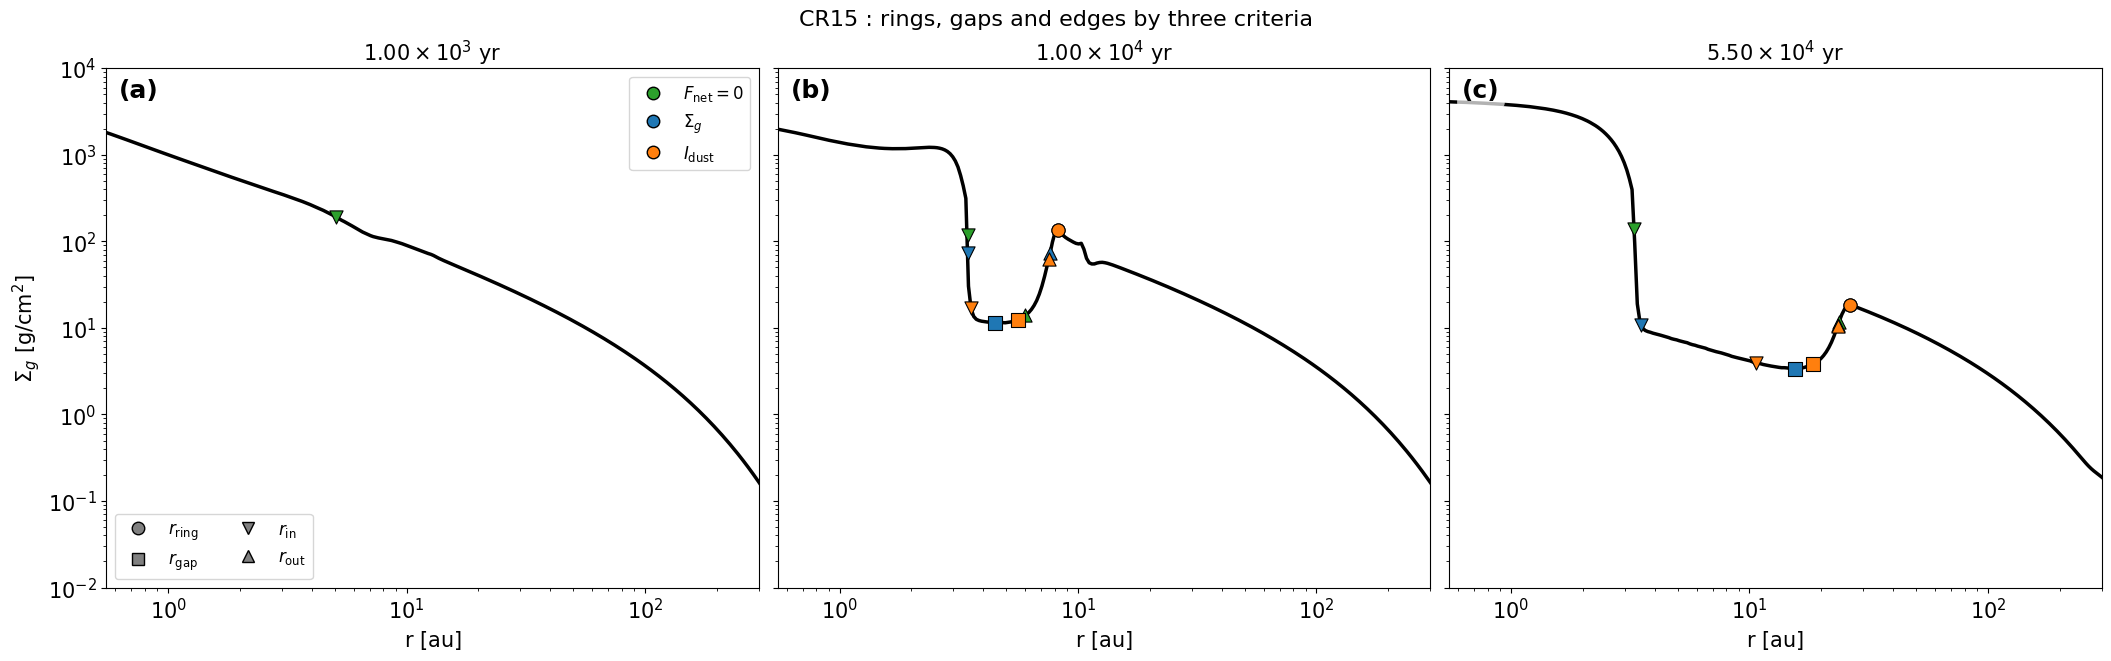

In [4]:
# ======================================================
# Sigma_g のスナップショットと 3 つの判定のリング・ギャップ・縁 (時刻ごとに 1 パネル. t = 0 はギャップがないので描かない)
#   F_net = 0 : r_in = スノーライン, r_out = F_net が符号を変える最も外側の半径 (リング・ギャップは定義しない)
#   Sigma_g   : analysis_obs_theory.ipynb の旧 cell 71 の判定 (find_ring_gap)
#   I_dust    : gap_detection.ipynb の判定 (find_radii). 条件は thesis_common.ipynb
# マーカーは Sigma_g(r) の線上に置く. 色が判定, 形がリング・ギャップ・縁. 値は表にも出力する
# 後のセルが使う変数を上書きしないよう, 計算は関数の中で行う
# file 列: out (3行目: a_j, 5行目以降: 0:r_cen 1~:Sigma_d,j)   out_gas 0:r_cen 1:sigmag 4:vg_r 12:T   out_B 2:B_z 3:etaO_R 4:etaA_R
# ======================================================

def gap_criteria(year, path, Kabs, sigmag_ini, M_star, eta_max, beam):
    # 時刻 year の r, Sigma_g と {判定: {"ring", "gap", "in", "out"}} [cm]
    d = np.loadtxt(path + "/out{}".format(year), skiprows=5)
    r, sig, vgr, T = np.loadtxt(path + "/out{}_gas".format(year), usecols=(0, 1, 4, 12)).T
    B, etaO, etaA = np.loadtxt(path + "_B/out{}_B".format(year), usecols=(2, 3, 4)).T
    Hg = np.sqrt(kB * T / (mu * mH)) / np.sqrt(G * M_star / r**3)

    r_in, r_out = find_wind_edges(r, T, sig, vgr, B, np.minimum(etaO + etaA, eta_max))

    sel = (r >= r_det_min * AU) & (r <= r_max * AU)
    rings_s, gaps_s, in_s, out_s = find_ring_gap(r[sel], sig[sel], Hg[sel])

    sigmad = np.where(np.abs(d[:, 1:]) > 1.0e-50, d[:, 1:], 0.0)
    I = Planck_Func_nu(T, Lambda_obs) * (1.0 - np.exp(-(sigmad @ Kabs))) * 1.0e23   # Jy/sr
    if beam is None:
        _, rings_I, gaps_I, in_I, out_I, _ = find_radii(r, I, sig / sigmag_ini, Hg)
    else:
        r_u, W = beam
        I_u = np.interp(r_u, r, I, left=0.0, right=0.0)
        _, rings_I, gaps_I, in_I, out_I, _ = find_radii(r_u, W @ I_u, np.interp(r_u, r, sig / sigmag_ini), np.interp(r_u, r, Hg))
    return r, sig, {"F_net": {"ring": [], "gap": [], "in": [r_in], "out": [r_out]},
                    "Sigma_g": {"ring": rings_s, "gap": gaps_s, "in": in_s, "out": out_s},
                    "I_dust": {"ring": rings_I, "gap": gaps_I, "in": in_I, "out": out_I}}

def plot_gap_criteria():
    path = BASE_DIR + MODEL
    plot_years = [year for year in SNAP_YEARS if year > 0]
    dradius = np.array([float(i) for i in linecache.getline(path + "/out{}".format(plot_years[0]), 3).split()])
    linecache.clearcache()
    Kabs = calc_Kabs(dradius)
    sigmag_ini = np.loadtxt(path + "/out0_gas", usecols=(1,))
    M_star, eta_max = read_input(path)
    beam = calc_beam() if use_beam else None
    colors = {"F_net": "tab:green", "Sigma_g": "tab:blue", "I_dust": "tab:orange"}
    labels = {"F_net": r"$F_{\rm net} = 0$", "Sigma_g": r"$\Sigma_g$", "I_dust": r"$I_{\rm dust}$"}
    markers = {"ring": ("o", r"$r_{\rm ring}$"), "gap": ("s", r"$r_{\rm gap}$"), "in": ("v", r"$r_{\rm in}$"), "out": ("^", r"$r_{\rm out}$")}

    fig, axes = plt.subplots(1, len(plot_years), figsize=(7 * len(plot_years), 6.5), sharey=True, layout="constrained", squeeze=False)
    for ax, year in zip(axes[0], plot_years):
        r, sig, found = gap_criteria(year, path, Kabs, sigmag_ini, M_star, eta_max, beam)
        ax.plot(r / AU, sig, color="black", lw=2.5)
        print("t = {} yr [au]".format(year))
        for crit, vals in found.items():
            print("  {:8s}".format(crit) + "  ".join("{}: {}".format(q, np.round(np.array(v, dtype=float) / AU, 2)) for q, v in vals.items()))
            for q, (marker, _) in markers.items():
                x = np.array(vals[q], dtype=float)
                x = x[np.isfinite(x)]
                ax.scatter(x / AU, np.interp(x, r, sig), s=90, marker=marker, color=colors[crit], edgecolor="black", linewidth=0.8, zorder=4)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(r_min, r_max)
        ax.set_ylim(1.0e-2, 1.0e4)
        ax.set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
        ax.set_title(snap_label(year), fontsize=15)
        ax.tick_params(labelsize=15)
    axes[0, 0].set_ylabel(r"$\Sigma_g \ \rm{[g/cm^2]}$", fontsize=15)

    # ---- 凡例1 (判定=色), 凡例2 (量=形) ----
    legend_crit = [Line2D([0], [0], color=colors[c], marker="o", ls="none", ms=9, markeredgecolor="black", label=labels[c]) for c in colors]
    legend_kind = [Line2D([0], [0], color="gray", marker=m, ls="none", ms=9, markeredgecolor="black", label=l) for m, l in markers.values()]
    leg1 = axes[0, 0].legend(handles=legend_crit, fontsize=12, loc="upper right")
    axes[0, 0].add_artist(leg1)
    axes[0, 0].legend(handles=legend_kind, fontsize=12, loc="lower left", ncol=2)
    fig.suptitle(model_names[MODEL] + " : rings, gaps and edges by three criteria", fontsize=16)
    plt.show()

plot_gap_criteria()


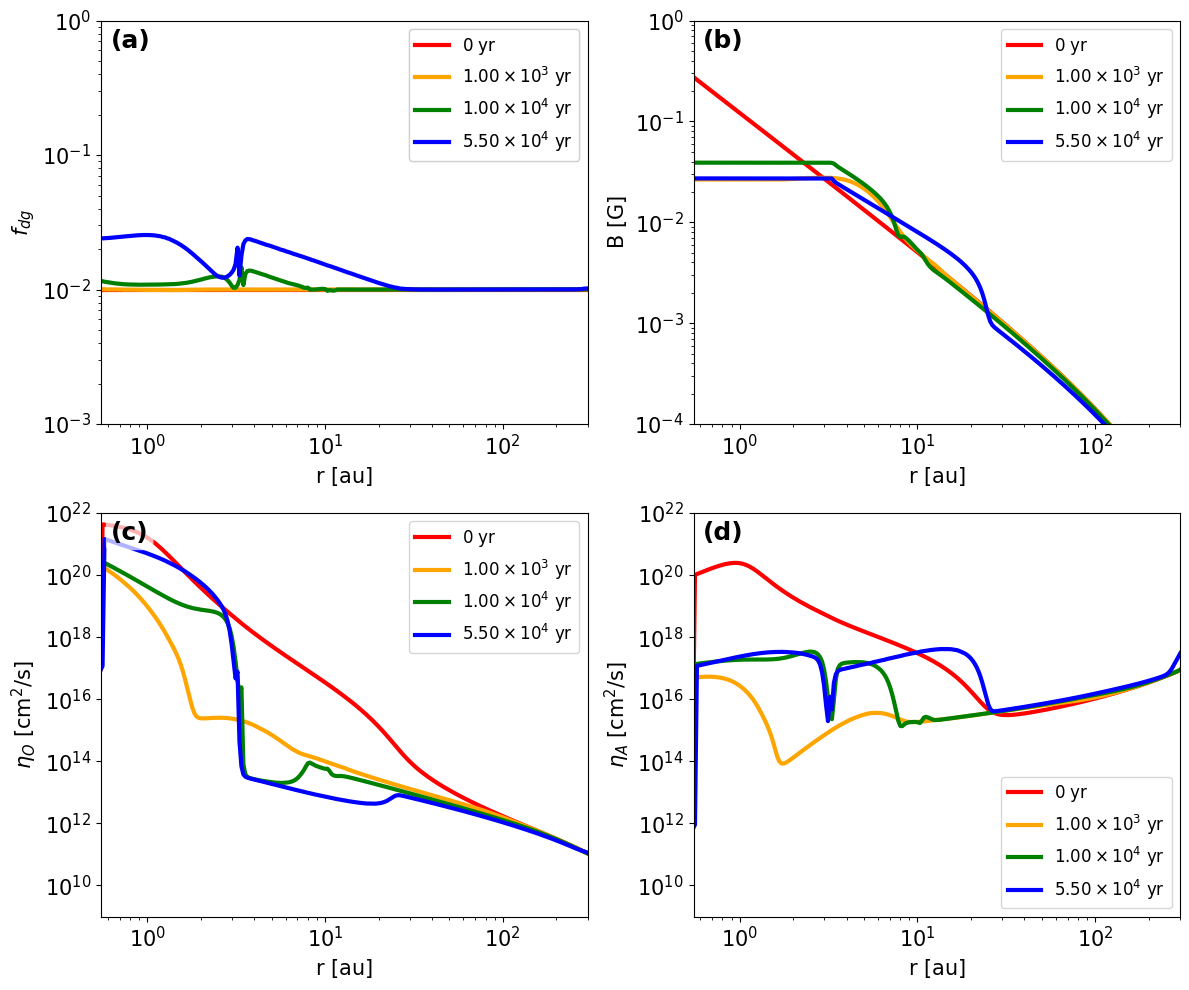

In [5]:
# [旧 cell 3]
outdir = BASE_DIR
resultdir = MODEL
file0_3430 = "/out{}".format(SNAP_YEARS[0])
file1_3430 = "/out{}".format(SNAP_YEARS[0])
file2_3430 = "/out{}".format(SNAP_YEARS[1])
file3_3430 = "/out{}".format(SNAP_YEARS[2])
file4_3430 = "/out{}".format(SNAP_YEARS[2])
file5_3430 = "/out{}".format(SNAP_YEARS[3])

file0 = outdir + resultdir + file0_3430
file1 = outdir + resultdir + file1_3430
file2 = outdir + resultdir + file2_3430
file3 = outdir + resultdir + file3_3430
file4 = outdir + resultdir + file4_3430
file5 = outdir + resultdir + file5_3430

dmass = np.array([float(i) for i in linecache.getline(file1, 1).split()])
dmass_b = np.array([float(i) for i in linecache.getline(file1, 2).split()])
delta_mass = dmass_b[1:] - dmass_b[:-1]
dradius = np.array([float(i) for i in linecache.getline(file1, 3).split()])
dradius_b = np.array([float(i) for i in linecache.getline(file1, 4).split()])
linecache.clearcache()

data0 = np.loadtxt(file0, dtype=float, skiprows=5).T
data1 = np.loadtxt(file1, dtype=float, skiprows=5).T
data2 = np.loadtxt(file2, dtype=float, skiprows=5).T
data3 = np.loadtxt(file3, dtype=float, skiprows=5).T
data4 = np.loadtxt(file4, dtype=float, skiprows=5).T
data5 = np.loadtxt(file5, dtype=float, skiprows=5).T

sigmad0 = data0[1:]
sigmad1 = data1[1:]
sigmad2 = data2[1:]
sigmad3 = data3[1:]
sigmad4 = data4[1:]
sigmad5 = data5[1:]

r = data1[0]

# FigureとAxesの作成
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# X軸（r/AU）
X = r / AU

file_gas = "_gas"
data0_gas = np.loadtxt(file0+file_gas, dtype=float).T
data1_gas = np.loadtxt(file1+file_gas, dtype=float).T
data2_gas = np.loadtxt(file2+file_gas, dtype=float).T
data3_gas = np.loadtxt(file3+file_gas, dtype=float).T
data4_gas = np.loadtxt(file4+file_gas, dtype=float).T
data5_gas = np.loadtxt(file5+file_gas, dtype=float).T

axes[0, 0].set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
axes[0, 0].set_ylabel(r"$ f_{dg} $", fontsize=15)
axes[0, 0].set_xscale("log")
axes[0, 0].set_yscale("log")
axes[0, 0].set_xlim(r_min,r_max)
axes[0, 0].set_ylim(1.0e-3,1.0e0)
axes[0, 0].tick_params(labelsize=15)

# ---- 実線=ガス ----
axes[0, 0].plot(X, (data0_gas[2,:]-data0_gas[3,:])/data0_gas[1,:], color=SNAP_COLORS[0],   linestyle="solid",  lw=3)
axes[0, 0].plot(X, (data2_gas[2,:]-data2_gas[3,:])/data2_gas[1,:], color=SNAP_COLORS[1],linestyle="solid",  lw=3)
axes[0, 0].plot(X, (data3_gas[2,:]-data3_gas[3,:])/data3_gas[1,:], color=SNAP_COLORS[2], linestyle="solid",  lw=3)
axes[0, 0].plot(X, (data5_gas[2,:]-data5_gas[3,:])/data5_gas[1,:], color=SNAP_COLORS[3],  linestyle="solid",  lw=3)

# ---- 点線=ダスト ----
#axes[0, 0].plot(X, data0_gas[2,:], color="red", linestyle="dotted", lw=3)
#axes[0, 0].plot(X, data2_gas[2,:], color="orange", linestyle="dotted", lw=3)
#axes[0, 0].plot(X, data3_gas[2,:], color="green", linestyle="dotted", lw=3)
#axes[0, 0].plot(X, data5_gas[2,:], color="blue", linestyle="dotted", lw=3)

# ---- 凡例1（時間=色） ----
legend_time = [
    Line2D([0],[0], color=SNAP_COLORS[0],    lw=3, label=snap_label(SNAP_YEARS[0])),
    Line2D([0],[0], color=SNAP_COLORS[1], lw=3, label=snap_label(SNAP_YEARS[1])),
    Line2D([0],[0], color=SNAP_COLORS[2],  lw=3, label=snap_label(SNAP_YEARS[2])),
    Line2D([0],[0], color=SNAP_COLORS[3],   lw=3, label=snap_label(SNAP_YEARS[3])),
]
# leg1 = axes[0,0].legend(handles=legend_time,title="Time (color)", loc="upper right", fontsize=12)
leg1 = axes[0,0].legend(handles=legend_time, fontsize=12,loc="upper right")
axes[0,0].add_artist(leg1)  # ← 1つ目を保持

# ---- 凡例2（種類=線種） ----
#legend_species = [
    #Line2D([0],[0], color="black", lw=3, linestyle="solid",  label="Gas"),
    #Line2D([0],[0], color="black", lw=3, linestyle="dotted", label="Dust"),
#]

# axes[0,0].legend(handles=legend_species, title="Species (linestyle)", loc="lower left", fontsize=12)
# axes[0,0].legend(handles=legend_species, fontsize=12,loc="lower left")

resultdir += "_B"

file0 =  outdir + resultdir + file0_3430 + "_B"
file1 =  outdir + resultdir + file1_3430 + "_B"
file2 =  outdir + resultdir + file2_3430 + "_B"
file3 =  outdir + resultdir + file3_3430 + "_B"
file4 =  outdir + resultdir + file4_3430 + "_B"
file5 =  outdir + resultdir + file5_3430 + "_B"

data0 = np.loadtxt(file0, dtype=float).T
data1 = np.loadtxt(file1, dtype=float).T
data2 = np.loadtxt(file2, dtype=float).T
data3 = np.loadtxt(file3, dtype=float).T
data4 = np.loadtxt(file4, dtype=float).T
data5 = np.loadtxt(file5, dtype=float).T

# Magnetic Field (左下)
# axes[0, 1].set_title("Magnetic Field", fontsize=20)
axes[0, 1].set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
axes[0, 1].set_ylabel(r"$ \rm{B} \ \rm{[G]}$", fontsize=15)
axes[0, 1].set_xscale("log")
axes[0, 1].set_xlim(r_min,r_max)
axes[0, 1].set_yscale("log")
axes[0, 1].tick_params(labelsize=15)
axes[0, 1].set_ylim(1.0e-4, 1.0e0)

axes[0, 1].plot(X, data0[2,:], color=SNAP_COLORS[0], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[0]))
axes[0, 1].plot(X, data2[2,:], color=SNAP_COLORS[1], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[1]))
axes[0, 1].plot(X, data3[2,:], color=SNAP_COLORS[2], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[2]))
axes[0, 1].plot(X, data5[2,:], color=SNAP_COLORS[3], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[3]))

axes[0, 1].legend(fontsize=12, loc="upper right")

 # Resistivity (左下) (Ohm)
axes[1, 0].set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
axes[1, 0].set_ylabel(r"$ \eta_O \ \rm{[cm^2/s]}$", fontsize=15)
axes[1, 0].set_xscale("log")
axes[1, 0].set_xlim(r_min,r_max)
axes[1, 0].set_yscale("log")
axes[1, 0].tick_params(labelsize=15)
axes[1, 0].set_ylim(1.0e9, 1.0e22)
# # # eta_{Ohm}
axes[1, 0].plot(X, data0[3,:], color=SNAP_COLORS[0], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[0]))
axes[1, 0].plot(X, data2[3,:], color=SNAP_COLORS[1], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[1]))
axes[1, 0].plot(X, data3[3,:], color=SNAP_COLORS[2], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[2]))
axes[1, 0].plot(X, data5[3,:], color=SNAP_COLORS[3], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[3]))
axes[1, 0].legend(fontsize=12, loc="upper right")
# Resistivity (左下) (Ohm)
axes[1, 1].set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
axes[1, 1].set_ylabel(r"$ \eta_A \ \rm{[cm^2/s]}$", fontsize=15)
axes[1, 1].set_xscale("log")
axes[1, 1].set_xlim(r_min,r_max)
axes[1, 1].set_yscale("log")
axes[1, 1].tick_params(labelsize=15)
axes[1, 1].set_ylim(1.0e9, 1.0e22)
# # # eta_{Ohm}
axes[1, 1].plot(X, data0[4,:], color=SNAP_COLORS[0], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[0]))
axes[1, 1].plot(X, data2[4,:], color=SNAP_COLORS[1], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[1]))
axes[1, 1].plot(X, data3[4,:], color=SNAP_COLORS[2], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[2]))
axes[1, 1].plot(X, data5[4,:], color=SNAP_COLORS[3], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[3]))
axes[1, 1].legend(fontsize=12, loc="lower right")
# レイアウト調整と表示
plt.tight_layout()
plt.savefig(fig_path("fdg.png", root=ANALYSIS_FIG_DIR))
plt.show()

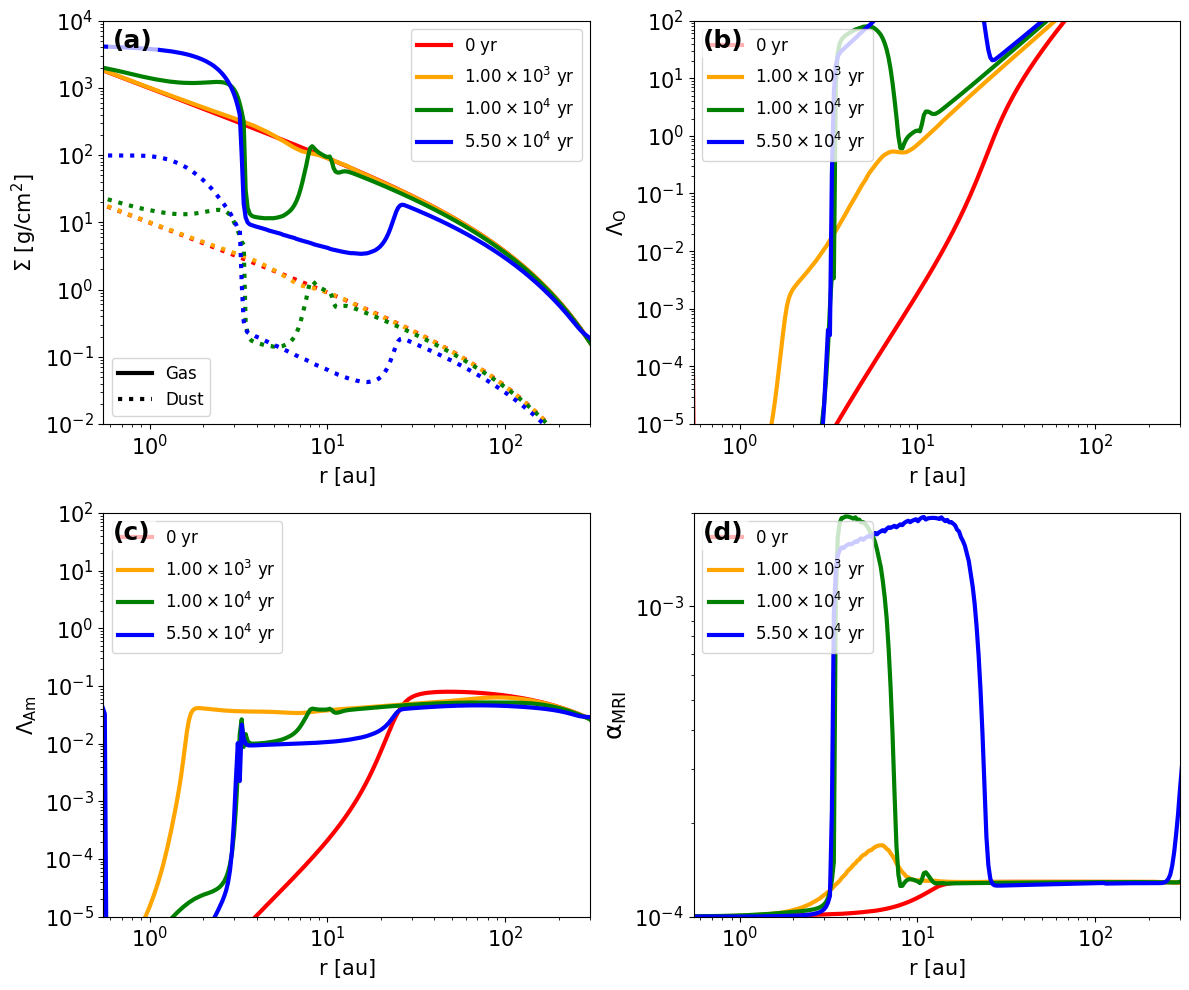

In [6]:
# [旧 cell 6]
outdir = BASE_DIR
resultdir = MODEL
file0_3430 = "/out{}".format(SNAP_YEARS[0])
file1_3430 = "/out{}".format(SNAP_YEARS[0])
file2_3430 = "/out{}".format(SNAP_YEARS[1])
file3_3430 = "/out{}".format(SNAP_YEARS[2])
file4_3430 = "/out{}".format(SNAP_YEARS[2])
file5_3430 = "/out{}".format(SNAP_YEARS[3])

file0 = outdir + resultdir + file0_3430
file1 = outdir + resultdir + file1_3430
file2 = outdir + resultdir + file2_3430
file3 = outdir + resultdir + file3_3430
file4 = outdir + resultdir + file4_3430
file5 = outdir + resultdir + file5_3430

dmass = np.array([float(i) for i in linecache.getline(file1, 1).split()])
dmass_b = np.array([float(i) for i in linecache.getline(file1, 2).split()])
delta_mass = dmass_b[1:] - dmass_b[:-1]
dradius = np.array([float(i) for i in linecache.getline(file1, 3).split()])
dradius_b = np.array([float(i) for i in linecache.getline(file1, 4).split()])
linecache.clearcache()

data0 = np.loadtxt(file0, dtype=float, skiprows=5).T
data1 = np.loadtxt(file1, dtype=float, skiprows=5).T
data2 = np.loadtxt(file2, dtype=float, skiprows=5).T
data3 = np.loadtxt(file3, dtype=float, skiprows=5).T
data4 = np.loadtxt(file4, dtype=float, skiprows=5).T
data5 = np.loadtxt(file5, dtype=float, skiprows=5).T

sigmad0 = data0[1:]
sigmad1 = data1[1:]
sigmad2 = data2[1:]
sigmad3 = data3[1:]
sigmad4 = data4[1:]
sigmad5 = data5[1:]

r = data1[0]

# FigureとAxesの作成
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# X軸（r/AU）
X = r / AU

file_gas = "_gas"
data0_gas = np.loadtxt(file0+file_gas, dtype=float).T
data1_gas = np.loadtxt(file1+file_gas, dtype=float).T
data2_gas = np.loadtxt(file2+file_gas, dtype=float).T
data3_gas = np.loadtxt(file3+file_gas, dtype=float).T
data4_gas = np.loadtxt(file4+file_gas, dtype=float).T
data5_gas = np.loadtxt(file5+file_gas, dtype=float).T

axes[0, 0].set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
axes[0, 0].set_ylabel(r"$\Sigma \ \rm{[g/cm^2]}$", fontsize=15)
axes[0, 0].set_xscale("log")
axes[0, 0].set_yscale("log")
axes[0, 0].set_xlim(r_min,r_max)
axes[0, 0].set_ylim(1.0e-2,1.0e4)
axes[0, 0].tick_params(labelsize=15)

# ---- 実線=ガス ----
axes[0, 0].plot(X, data0_gas[1,:], color=SNAP_COLORS[0],   linestyle="solid",  lw=3)
axes[0, 0].plot(X, data2_gas[1,:], color=SNAP_COLORS[1],linestyle="solid",  lw=3)
axes[0, 0].plot(X, data3_gas[1,:], color=SNAP_COLORS[2], linestyle="solid",  lw=3)
axes[0, 0].plot(X, data5_gas[1,:], color=SNAP_COLORS[3],  linestyle="solid",  lw=3)

# ---- 点線=ダスト ----
axes[0, 0].plot(X, data0_gas[2,:]-data0_gas[3,:], color=SNAP_COLORS[0], linestyle="dotted", lw=3)
axes[0, 0].plot(X, data2_gas[2,:]-data2_gas[3,:], color=SNAP_COLORS[1], linestyle="dotted", lw=3)
axes[0, 0].plot(X, data3_gas[2,:]-data3_gas[3,:], color=SNAP_COLORS[2], linestyle="dotted", lw=3)
axes[0, 0].plot(X, data5_gas[2,:]-data5_gas[3,:], color=SNAP_COLORS[3], linestyle="dotted", lw=3)

# ---- 凡例1（時間=色） ----
legend_time = [
    Line2D([0],[0], color=SNAP_COLORS[0],    lw=3, label=snap_label(SNAP_YEARS[0])),
    Line2D([0],[0], color=SNAP_COLORS[1], lw=3, label=snap_label(SNAP_YEARS[1])),
    Line2D([0],[0], color=SNAP_COLORS[2],  lw=3, label=snap_label(SNAP_YEARS[2])),
    Line2D([0],[0], color=SNAP_COLORS[3],   lw=3, label=snap_label(SNAP_YEARS[3])),
]
# leg1 = axes[0,0].legend(handles=legend_time,title="Time (color)", loc="upper right", fontsize=12)
leg1 = axes[0,0].legend(handles=legend_time, fontsize=12,loc="upper right")
axes[0,0].add_artist(leg1)  # ← 1つ目を保持

# ---- 凡例2（種類=線種） ----
legend_species = [
    Line2D([0],[0], color="black", lw=3, linestyle="solid",  label="Gas"),
    Line2D([0],[0], color="black", lw=3, linestyle="dotted", label="Dust"),
]

# axes[0,0].legend(handles=legend_species, title="Species (linestyle)", loc="lower left", fontsize=12)
axes[0,0].legend(handles=legend_species, fontsize=12,loc="lower left")

resultdir += "_B"

file0 =  outdir + resultdir + file0_3430 + "_B"
file1 =  outdir + resultdir + file1_3430 + "_B"
file2 =  outdir + resultdir + file2_3430 + "_B"
file3 =  outdir + resultdir + file3_3430 + "_B"
file4 =  outdir + resultdir + file4_3430 + "_B"
file5 =  outdir + resultdir + file5_3430 + "_B"

data0 = np.loadtxt(file0, dtype=float).T
data1 = np.loadtxt(file1, dtype=float).T
data2 = np.loadtxt(file2, dtype=float).T
data3 = np.loadtxt(file3, dtype=float).T
data4 = np.loadtxt(file4, dtype=float).T
data5 = np.loadtxt(file5, dtype=float).T

# # Resistivity (右上)
# axes[0, 1].set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
# axes[0, 1].set_ylabel(r"$ \eta_A \ \rm{[cm^2/s]}$", fontsize=15)
# axes[0, 1].set_xscale("log")
# axes[0, 1].set_xlim(r[0] / AU, 1.5e2)
# axes[0, 1].set_yscale("log")
# axes[0, 1].tick_params(labelsize=15)
# axes[0, 1].set_ylim(1.0e15, 1.0e21)
# # # eta_{Ohm}
# # axes[0, 1].plot(X, data0[3,:], color="red", linestyle="solid", lw=3, label=r'$0.0 \rm{yr}$')
# # axes[0, 1].plot(X, data3[3,:], color="orange", linestyle="solid", lw=3, label=r'$1.00\times 10^4 \rm{yr}$')
# # axes[0, 1].plot(X, data4[3,:], color="green", linestyle="solid", lw=3, label=r'$2.00\times 10^4 \rm{yr}$')
# # axes[0, 1].plot(X, data5[3,:], color="blue", linestyle="solid", lw=3, label=r'$2.80\times 10^4 \rm{yr}$')
# # eta_{Am}
# axes[0, 1].plot(X, data0[4,:], color="red", linestyle="solid", lw=3, label=r'$0.0 \rm{yr}$')
# axes[0, 1].plot(X, data2[4,:], color="orange", linestyle="solid", lw=3, label=r'$1.00\times 10^3 \rm{yr}$')
# axes[0, 1].plot(X, data3[4,:], color="green", linestyle="solid", lw=3, label=r'$1.00\times 10^4 \rm{yr}$')
# axes[0, 1].plot(X, data5[4,:], color="blue", linestyle="solid", lw=3, label=r'$3.00\times 10^4 \rm{yr}$')

# axes[0, 1].legend(fontsize=12, loc="lower right")

# axes[1, 0].set_title("Magnetic Field", fontsize=20)
# Elssasser number (右上)
Lambda0 = []
Lambda2 = []
Lambda3 = []
Lambda5 = []

T0 = data0_gas[12,:]
T1 = data2_gas[12,:]
T2 = data3_gas[12,:]
T3 = data5_gas[12,:]

for i in range(len(data0[0,:])):
    omega = np.sqrt(G*Msolar/data0[0,i]**3)
    cs = np.sqrt(kB*T0[i]/ (mu*mH) )
    Hg = cs/omega
    sigmag = data0_gas[1,i]
    B = data0[2,i]
    etaA = data0[4,i]
    etaO = data0[3,i]
    rho_mid = sigmag/(np.sqrt(2.0*np.pi)*Hg)
    VA_2 = B**2/(4.0*np.pi*rho_mid)
    Lambda0.append( VA_2/(etaO*omega) )
    
    cs = np.sqrt(kB*T1[i]/ (mu*mH) )
    Hg = cs/omega
    sigmag = data2_gas[1,i]
    B = data2[2,i]
    etaA = data2[4,i]
    etaO = data2[3,i]
    rho_mid = sigmag/(np.sqrt(2.0*np.pi)*Hg)
    VA_2 = B**2/(4.0*np.pi*rho_mid)
    Lambda2.append( VA_2/(etaO*omega) )
    
    cs = np.sqrt(kB*T2[i]/ (mu*mH) )
    Hg = cs/omega
    sigmag = data3_gas[1,i]
    B = data3[2,i]
    etaA = data3[4,i]
    etaO = data3[3,i]
    rho_mid = sigmag/(np.sqrt(2.0*np.pi)*Hg)
    VA_2 = B**2/(4.0*np.pi*rho_mid)
    Lambda3.append( VA_2/(etaO*omega) )
    
    cs = np.sqrt(kB*T3[i]/ (mu*mH) )
    Hg = cs/omega
    sigmag = data5_gas[1,i]
    B = data5[2,i]
    etaA = data5[4,i]
    etaO = data5[3,i]
    rho_mid = sigmag/(np.sqrt(2.0*np.pi)*Hg)
    VA_2 = B**2/(4.0*np.pi*rho_mid)
    Lambda5.append( VA_2/(etaO*omega) )

axes[0, 1].set_xlabel(r"$ \mathrm{r} \ \rm{[au]}$", fontsize=15)
axes[0, 1].set_ylabel(r"$ \mathrm{\Lambda_O} $", fontsize=15)
axes[0, 1].set_xscale("log")
axes[0, 1].set_xlim(r_min,r_max)
axes[0, 1].set_yscale("log")
axes[0, 1].tick_params(labelsize=15)
axes[0, 1].set_ylim(1.0e-5, 1.0e2)

axes[0, 1].plot(X, Lambda0, color=SNAP_COLORS[0], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[0]))
axes[0, 1].plot(X, Lambda2, color=SNAP_COLORS[1], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[1]))
axes[0, 1].plot(X, Lambda3, color=SNAP_COLORS[2], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[2]))
axes[0, 1].plot(X, Lambda5, color=SNAP_COLORS[3], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[3]))

axes[0, 1].legend(fontsize=12, loc="upper left")

# Elssasser number (左下)
# axes[1, 0].set_title("Magnetic Field", fontsize=20)
Lambda0 = []
Lambda2 = []
Lambda3 = []
Lambda5 = []

T0 = data0_gas[12,:]
T1 = data2_gas[12,:]
T2 = data3_gas[12,:]
T3 = data5_gas[12,:]

for i in range(len(data0[0,:])):
    omega = np.sqrt(G*Msolar/data0[0,i]**3)
    cs = np.sqrt(kB*T0[i]/ (mu*mH) )
    Hg = cs/omega
    sigmag = data0_gas[1,i]
    B = data0[2,i]
    etaA = data0[4,i]
    etaO = data0[3,i]
    rho_mid = sigmag/(np.sqrt(2.0*np.pi)*Hg)
    VA_2 = B**2/(4.0*np.pi*rho_mid)
    Lambda0.append( VA_2/(etaA*omega) )
    
    cs = np.sqrt(kB*T1[i]/ (mu*mH) )
    Hg = cs/omega
    sigmag = data2_gas[1,i]
    B = data2[2,i]
    etaA = data2[4,i]
    etaO = data2[3,i]
    rho_mid = sigmag/(np.sqrt(2.0*np.pi)*Hg)
    VA_2 = B**2/(4.0*np.pi*rho_mid)
    Lambda2.append( VA_2/(etaA*omega) )
    
    cs = np.sqrt(kB*T2[i]/ (mu*mH) )
    Hg = cs/omega
    sigmag = data3_gas[1,i]
    B = data3[2,i]
    etaA = data3[4,i]
    etaO = data3[3,i]
    rho_mid = sigmag/(np.sqrt(2.0*np.pi)*Hg)
    VA_2 = B**2/(4.0*np.pi*rho_mid)
    Lambda3.append( VA_2/(etaA*omega) )
    
    cs = np.sqrt(kB*T3[i]/ (mu*mH) )
    Hg = cs/omega
    sigmag = data5_gas[1,i]
    B = data5[2,i]
    etaA = data5[4,i]
    etaO = data5[3,i]
    rho_mid = sigmag/(np.sqrt(2.0*np.pi)*Hg)
    VA_2 = B**2/(4.0*np.pi*rho_mid)
    Lambda5.append( VA_2/(etaA*omega) )

axes[1, 0].set_xlabel(r"$ \mathrm{r} \ \rm{[au]}$", fontsize=15)
axes[1, 0].set_ylabel(r"$ \mathrm{\Lambda_{Am}} $", fontsize=15)
axes[1, 0].set_xscale("log")
axes[1, 0].set_xlim(r_min,r_max)
axes[1, 0].set_yscale("log")
axes[1, 0].tick_params(labelsize=15)
axes[1, 0].set_ylim(1.0e-5, 1.0e2)

axes[1, 0].plot(X, Lambda0, color=SNAP_COLORS[0], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[0]))
axes[1, 0].plot(X, Lambda2, color=SNAP_COLORS[1], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[1]))
axes[1, 0].plot(X, Lambda3, color=SNAP_COLORS[2], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[2]))
axes[1, 0].plot(X, Lambda5, color=SNAP_COLORS[3], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[3]))

axes[1, 0].legend(fontsize=12, loc="upper left")

# # Turbulent Viscosity (右下)
# axes[1, 0].set_title("Turbulent Viscosity", fontsize=20)
axes[1, 1].set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
axes[1, 1].set_ylabel(r"$ \rm{\alpha_{MRI}} $", fontsize=18)
axes[1, 1].set_xscale("log")
axes[1, 1].set_xlim(r_min,r_max)
axes[1, 1].set_yscale("log")
axes[1, 1].set_ylim(1.0e-4, 2.0e-3)
axes[1, 1].tick_params(labelsize=15)

axes[1, 1].plot(X, data0[1,:], color=SNAP_COLORS[0], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[0]))
axes[1, 1].plot(X, data2[1,:], color=SNAP_COLORS[1], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[1]))
axes[1, 1].plot(X, data3[1,:], color=SNAP_COLORS[2], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[2]))
axes[1, 1].plot(X, data5[1,:], color=SNAP_COLORS[3], linestyle="solid", lw=3, label=snap_label(SNAP_YEARS[3]))

axes[1, 1].legend(fontsize=12, loc="upper left")
# レイアウト調整と表示
plt.tight_layout()
# plt.savefig(fig_path("Lambda.png", root=ANALYSIS_FIG_DIR))
plt.savefig(fig_path("Lambda.png", root=ANALYSIS_FIG_DIR))
plt.show()

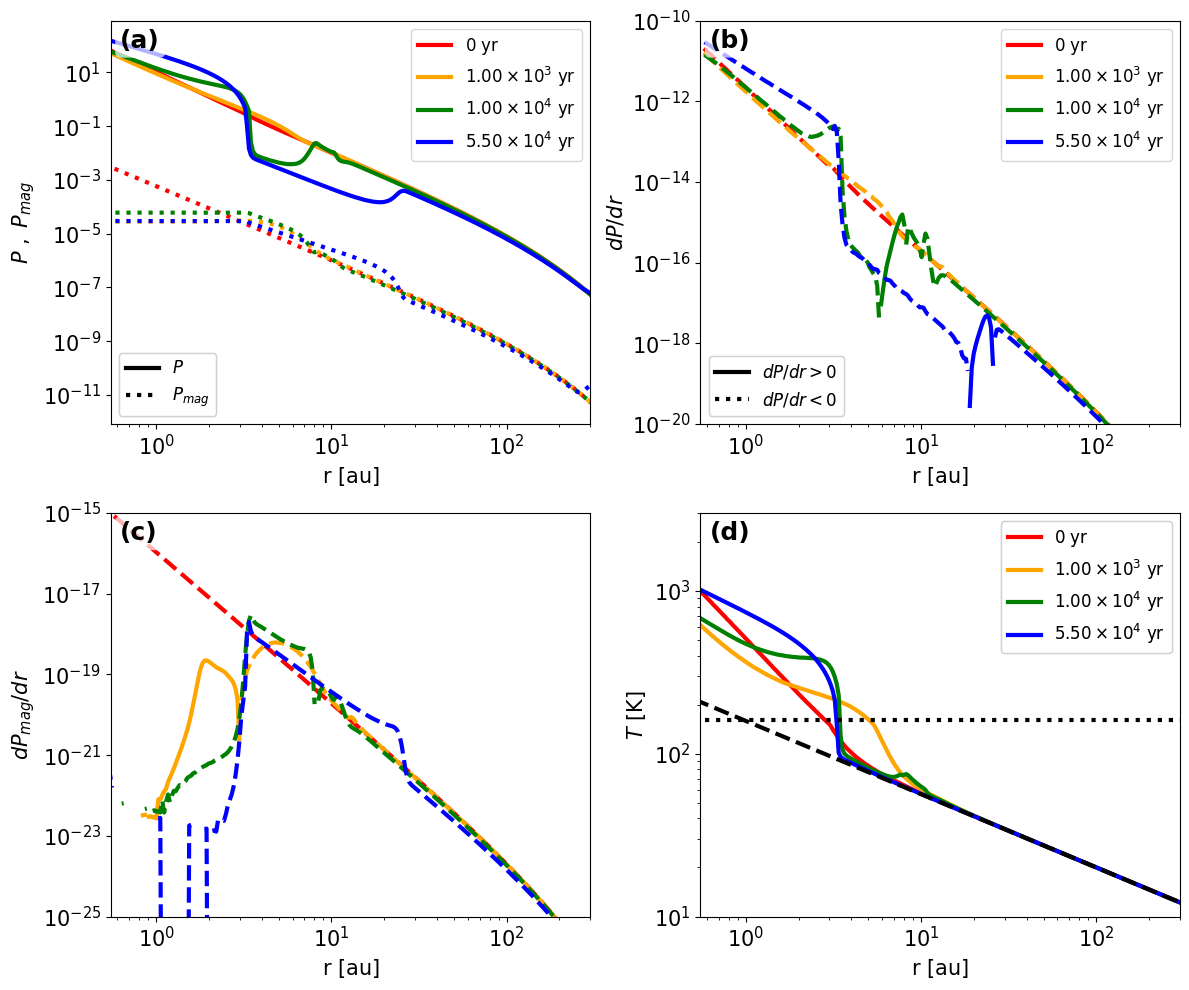

In [7]:
# [旧 cell 8]
# ==================================
# 物理定数
# ==================================
G = 6.6743e-8
Msolar = 1.989e33
kB = 1.380649e-16
mH = 1.6735575e-24
mu = 2.34
AU = 1.496e13

# ==================================
# 符号で線種を変える関数
# ==================================
def plot_sign_split(ax, X, Y, color="black", lw=3,alpha=1.0,label=" "):
    """Y>0 は実線、Y<0 は点線で描画する"""
    # 正の領域
    Y_pos = np.where(Y > 0, Y, np.nan)
    ax.plot(X, Y_pos, color=color, lw=lw, linestyle="solid",alpha=alpha,label=label)

    # 負の領域
    Y_neg = np.where(Y < 0, np.fabs(Y), np.nan)
    ax.plot(X, Y_neg, color=color, lw=lw, linestyle="dashed",alpha=alpha,label=label)

# ==================================
# ファイル設定
# ==================================

outdir = BASE_DIR
resultdir = MODEL
file0_3430 = "/out{}".format(SNAP_YEARS[0])
file1_3430 = "/out{}".format(SNAP_YEARS[0])
file2_3430 = "/out{}".format(SNAP_YEARS[1])
file3_3430 = "/out{}".format(SNAP_YEARS[2])
file4_3430 = "/out{}".format(SNAP_YEARS[2])
file5_3430 = "/out{}".format(SNAP_YEARS[3])

file0 = outdir + resultdir + file0_3430
file1 = outdir + resultdir + file1_3430
file2 = outdir + resultdir + file2_3430
file3 = outdir + resultdir + file3_3430
file4 = outdir + resultdir + file4_3430
file5 = outdir + resultdir + file5_3430

resultdir += "_B"

file0_B =  outdir + resultdir + file0_3430 + "_B"
file1_B =  outdir + resultdir + file1_3430 + "_B"
file2_B =  outdir + resultdir + file2_3430 + "_B"
file3_B =  outdir + resultdir + file3_3430 + "_B"
file4_B =  outdir + resultdir + file4_3430 + "_B"
file5_B =  outdir + resultdir + file5_3430 + "_B"

# ==================================
# Dust bin 情報
# ==================================
dmass = np.array([float(i) for i in linecache.getline(file1, 1).split()])
dmass_b = np.array([float(i) for i in linecache.getline(file1, 2).split()])
delta_mass = dmass_b[1:] - dmass_b[:-1]
dradius = np.array([float(i) for i in linecache.getline(file1, 3).split()])
dradius_b = np.array([float(i) for i in linecache.getline(file1, 4).split()])
linecache.clearcache()

# ==================================
# Dust データ読込
# ==================================
data0 = np.loadtxt(file0, dtype=float, skiprows=5).T
data1 = np.loadtxt(file1, dtype=float, skiprows=5).T
data2 = np.loadtxt(file2, dtype=float, skiprows=5).T
data3 = np.loadtxt(file3, dtype=float, skiprows=5).T
data4 = np.loadtxt(file4, dtype=float, skiprows=5).T
data5 = np.loadtxt(file5, dtype=float, skiprows=5).T

sigmad0 = data0[1:]
sigmad1 = data1[1:]
sigmad2 = data2[1:]
sigmad3 = data3[1:]
sigmad4 = data4[1:]
sigmad5 = data5[1:]

r = data0[0]
X = r 

# ==================================
# Gas データ読込
# ==================================
file_gas = "_gas"
data0_gas = np.loadtxt(file0 + file_gas, dtype=float).T
data1_gas = np.loadtxt(file1 + file_gas, dtype=float).T
data2_gas = np.loadtxt(file2 + file_gas, dtype=float).T
data3_gas = np.loadtxt(file3 + file_gas, dtype=float).T
data4_gas = np.loadtxt(file4 + file_gas, dtype=float).T
data5_gas = np.loadtxt(file5 + file_gas, dtype=float).T

# ==================================
# B データ読込
# ==================================

data0_B = np.loadtxt(file0_B, dtype=float).T
data1_B = np.loadtxt(file1_B, dtype=float).T
data2_B = np.loadtxt(file2_B, dtype=float).T
data3_B = np.loadtxt(file3_B, dtype=float).T
data4_B = np.loadtxt(file4_B, dtype=float).T
data5_B = np.loadtxt(file5_B, dtype=float).T

year_color = {snap_label(y): c for y, c in zip(SNAP_YEARS, SNAP_COLORS)}

dict_style_P = {
   r"$ P $" : "solid",
   r"$ P_{mag} $" : "dotted",
}

dict_style_dPdr = {
   r"$ dP/dr > 0 $" : "solid",
   r"$ dP/dr < 0 $" : "dotted",
}

dict_style_dPmagdr = {
   r"$ dP_{mag}/dr > 0 $" : "solid",
   r"$ dP_{mag}/dr < 0 $" : "dotted",
}

dict_style_N = {
   r"$ N > 0 $" : "solid",
   r"$ N < 0 $" : "dotted",
}
# ==================================
# Figure と 2×2 Axes 作成
# ==================================
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# # ==================================
# # (0,0) \beta
# # ==================================
# ax = axes[0, 0]
# ax.set_xlabel(r"$ \rm{r} \ [au]$", fontsize=15)
# ax.set_ylabel(r"$ \beta $", fontsize=15)
# ax.set_xscale("log")
# ax.set_yscale("log")
# ax.set_xlim(X[0], 1.0e3)
# ax.tick_params(labelsize=15)

# # --- 符号で線が変わる ---
# plot_sign_split(ax, X, data0_B[5, :], color="red")
# plot_sign_split(ax, X, data2_B[5, :], color="orange")
# plot_sign_split(ax, X, data3_B[5, :], color="green")
# plot_sign_split(ax, X, data5_B[5, :], color="blue")

# P, P_mag
ax =  axes[0, 0]
beta_1 = data0_B[5, :]
beta_2 = data2_B[5, :]
beta_3 = data3_B[5, :]
beta_4 = data5_B[5, :]

P_mag1 = data0_B[2, :]**2/(8.0*np.pi)
P_mag2 = data2_B[2, :]**2/(8.0*np.pi)
P_mag3 = data3_B[2, :]**2/(8.0*np.pi)
P_mag4 = data5_B[2, :]**2/(8.0*np.pi)

P_1 = P_mag1*beta_1
P_2 = P_mag2*beta_2
P_3 = P_mag3*beta_3
P_4 = P_mag4*beta_4

X = r 
X = r / AU  # AU スケール

ax.set_xlabel(r"$ \rm{r} \ [au]$", fontsize=15)
ax.set_ylabel(r"$ P \ , \ P_{mag}  $", fontsize=15)
ax.set_xscale("log")
ax.set_yscale("log")
# ax.set_xlim(0.5, 1.0e3)
ax.set_xlim(r_min,r_max)
# ax.set_ylim(1.0e-13, 1.0e1)
ax.tick_params(labelsize=15)

ax.plot(X, P_1,color=SNAP_COLORS[0],lw =3)
ax.plot(X, P_2,color=SNAP_COLORS[1],lw = 3)
ax.plot(X, P_3,color=SNAP_COLORS[2],lw =3)
ax.plot(X, P_4,color=SNAP_COLORS[3],lw =3)

ax.plot(X, P_mag1,lw =3, color=SNAP_COLORS[0],linestyle = "dotted")
ax.plot(X, P_mag2,lw = 3,color=SNAP_COLORS[1],linestyle = "dotted")
ax.plot(X, P_mag3,lw =3,color=SNAP_COLORS[2],linestyle = "dotted")
ax.plot(X, P_mag4,lw =3,color=SNAP_COLORS[3],linestyle = "dotted")

handles_color = []
for label , color in year_color.items():
    h, = ax.plot([],[],color=color,lw=3,label=label)
    handles_color.append(h)
legend1 = ax.legend(handles=handles_color,
                    loc="upper right",
                    fontsize = 12)
ax.add_artist(legend1)

handles_style = []
for label , style in dict_style_P.items():
    h, = ax.plot([],[],color="black",linestyle = style,lw=3,label=label)
    handles_style.append(h)
legend2 = ax.legend(handles=handles_style,
                    loc="lower left",
                    fontsize = 12)
ax.add_artist(legend2)

# ==================================
# (0,1) dP/dr
# ==================================
X = r 
nr = len(X)

dPdr1 = np.zeros(nr)
dPdr2 = np.zeros(nr)
dPdr3 = np.zeros(nr)
dPdr4 = np.zeros(nr)

for i in range(nr):
    if  i >=1 and i<=nr-2:
        s = X[i] - X[i-1]
        t = X[i+1] - X[i]
        coeff1 = s*s/(s*t*(s+t))
        coeff2 = (t*t-s*s)/(s*t*(s+t))
        coeff3 = -t*t/(s*t*(s+t))
        
        dPdr1[i] = P_1[i+1]*coeff1 + P_1[i]*coeff2 + P_1[i-1]*coeff3
        dPdr2[i] = P_2[i+1]*coeff1 + P_2[i]*coeff2 + P_2[i-1]*coeff3
        dPdr3[i] = P_3[i+1]*coeff1 + P_3[i]*coeff2 + P_3[i-1]*coeff3
        dPdr4[i] = P_4[i+1]*coeff1 + P_4[i]*coeff2 + P_4[i-1]*coeff3
        
    elif(i==0):
        logx_min = np.log(X[nr-1]/X[0])/float(nr-1)
        x_min = X[0]*np.exp(-logx_min)
        s = X[i] - x_min
        t = X[i+1] - X[i]
        coeff1 = s*s/(s*t*(s+t))
        coeff2 = (t*t-s*s)/(s*t*(s+t))
        coeff3 = -t*t/(s*t*(s+t))
        
        dPdr1[i] = P_1[i+1]*coeff1 + P_1[i]*coeff2 + P_1[i]*coeff3
        dPdr2[i] = P_2[i+1]*coeff1 + P_2[i]*coeff2 + P_2[i]*coeff3
        dPdr3[i] = P_3[i+1]*coeff1 + P_3[i]*coeff2 + P_3[i]*coeff3
        dPdr4[i] = P_4[i+1]*coeff1 + P_4[i]*coeff2 + P_4[i]*coeff3
            
    elif(i==nr-1):
        logx_max = np.log(X[nr-1]/X[0])/float(nr-1)
        x_max = X[0]*np.exp(logx_max*nr)
        s = X[i] - X[i-1]
        t = x_max - X[i]
    
        coeff1 = s*s/(s*t*(s+t))
        coeff2 = (t*t-s*s)/(s*t*(s+t))
        coeff3 = -t*t/(s*t*(s+t))
        
        dPdr1[i] = P_1[i]*coeff1 + P_1[i]*coeff2 + P_1[i-1]*coeff3
        dPdr2[i] = P_2[i]*coeff1 + P_2[i]*coeff2 + P_2[i-1]*coeff3
        dPdr3[i] = P_3[i]*coeff1 + P_3[i]*coeff2 + P_3[i-1]*coeff3
        dPdr4[i] = P_4[i]*coeff1 + P_4[i]*coeff2 + P_4[i-1]*coeff3

X = r 
X = r / AU  # AU スケール
ax = axes[0, 1]
ax.set_xlabel(r"$ \rm{r} \ [au]$", fontsize=15)
ax.set_ylabel(r"$ dP/dr $", fontsize=15)
ax.set_xscale("log")
ax.set_yscale("log")
# ax.set_xlim(0.5, 1.0e3)
ax.set_xlim(r_min,r_max)
ax.set_ylim(1.0e-20, 1.0e-10)
ax.tick_params(labelsize=15)
# ax.set_ylim(1.0e-13, 1.0e2)

# --- 符号で線が変わる ---
plot_sign_split(ax, X, dPdr1, color=SNAP_COLORS[0])
plot_sign_split(ax, X, dPdr2, color=SNAP_COLORS[1])
plot_sign_split(ax, X, dPdr3, color=SNAP_COLORS[2])
plot_sign_split(ax, X, dPdr4, color=SNAP_COLORS[3])

handles_color = []
for label , color in year_color.items():
    h, = ax.plot([],[],color=color,lw=3,label=label)
    handles_color.append(h)
legend1 = ax.legend(handles=handles_color,
                    loc="upper right",
                    fontsize = 12)
ax.add_artist(legend1)
handles_style = []
for label , style in dict_style_dPdr.items():
    h, = ax.plot([],[],color="black",linestyle = style,lw=3,label=label)
    handles_style.append(h)
legend2 = ax.legend(handles=handles_style,
                    loc="lower left",
                    fontsize = 12)
ax.add_artist(legend2)

# #################################
# # (0,1) dP_mag/dr
# # ==================================
X = r 
nr = len(X)

dPdr1_mag = np.zeros(nr)
dPdr2_mag = np.zeros(nr)
dPdr3_mag = np.zeros(nr)
dPdr4_mag = np.zeros(nr)

for i in range(nr):
    if  i >=1 and i<=nr-2:
        s = X[i] - X[i-1]
        t = X[i+1] - X[i]
        coeff1 = s*s/(s*t*(s+t))
        coeff2 = (t*t-s*s)/(s*t*(s+t))
        coeff3 = -t*t/(s*t*(s+t))
            
        dPdr1_mag[i] = P_mag1[i+1]*coeff1 + P_mag1[i]*coeff2 + P_mag1[i-1]*coeff3
        dPdr2_mag[i] = P_mag2[i+1]*coeff1 + P_mag2[i]*coeff2 + P_mag2[i-1]*coeff3
        dPdr3_mag[i] = P_mag3[i+1]*coeff1 + P_mag3[i]*coeff2 + P_mag3[i-1]*coeff3
        dPdr4_mag[i] = P_mag4[i+1]*coeff1 + P_mag4[i]*coeff2 + P_mag4[i-1]*coeff3
    elif(i==0):
        logx_min = np.log(X[nr-1]/X[0])/float(nr-1)
        x_min = X[0]*np.exp(-logx_min)
        s = X[i] - x_min
        t = X[i+1] - X[i]
        coeff1 = s*s/(s*t*(s+t))
        coeff2 = (t*t-s*s)/(s*t*(s+t))
        coeff3 = -t*t/(s*t*(s+t))
            
        dPdr1_mag[i] = P_mag1[i+1]*coeff1 + P_mag1[i]*coeff2 + P_mag1[i]*coeff3
        dPdr2_mag[i] = P_mag2[i+1]*coeff1 + P_mag2[i]*coeff2 + P_mag2[i]*coeff3
        dPdr3_mag[i] = P_mag3[i+1]*coeff1 + P_mag3[i]*coeff2 + P_mag3[i]*coeff3
        dPdr4_mag[i] = P_mag4[i+1]*coeff1 + P_mag4[i]*coeff2 + P_mag4[i]*coeff3
    elif(i==nr-1):
        logx_max = np.log(X[nr-1]/X[0])/float(nr-1)
        x_max = X[0]*np.exp(logx_max*nr)
        s = X[i] - X[i-1]
        t = x_max - X[i]
    
        coeff1 = s*s/(s*t*(s+t))
        coeff2 = (t*t-s*s)/(s*t*(s+t))
        coeff3 = -t*t/(s*t*(s+t))
        
        dPdr1_mag[i] = P_mag1[i]*coeff1 + P_mag1[i]*coeff2 + P_mag1[i-1]*coeff3
        dPdr2_mag[i] = P_mag2[i]*coeff1 + P_mag2[i]*coeff2 + P_mag2[i-1]*coeff3
        dPdr3_mag[i] = P_mag3[i]*coeff1 + P_mag3[i]*coeff2 + P_mag3[i-1]*coeff3
        dPdr4_mag[i] = P_mag4[i]*coeff1 + P_mag4[i]*coeff2 + P_mag4[i-1]*coeff3

X = r 
X = r / AU  # AU スケール
ax = axes[1, 0]
ax.set_xlabel(r"$ \rm{r} \ [au]$", fontsize=15)
ax.set_ylabel(r"$ dP_{mag}/dr $", fontsize=15)
ax.set_xscale("log")
ax.set_yscale("log")
# ax.set_xlim(0.5, 1.0e3)
ax.set_xlim(r_min,r_max)
ax.set_ylim(1.0e-25, 1.0e-15)
ax.tick_params(labelsize=15)

# --- 符号で線が変わる ---
plot_sign_split(ax, X, dPdr1_mag, color=SNAP_COLORS[0],lw =3)
plot_sign_split(ax, X, dPdr2_mag, color=SNAP_COLORS[1],lw =3)
plot_sign_split(ax, X, dPdr3_mag, color=SNAP_COLORS[2],lw =3)
plot_sign_split(ax, X, dPdr4_mag, color=SNAP_COLORS[3],lw =3)

# handles_color = []
# for label , color in year_color.items():
#     h, = ax.plot([],[],color=color,lw=3,label=label)
#     handles_color.append(h)
# legend1 = ax.legend(handles=handles_color,
#                     loc="upper right",
#                     fontsize = 12)
# ax.add_artist(legend1)
# handles_style = []
# for label , style in dict_style_dPmagdr.items():
#     h, = ax.plot([],[],color="black",linestyle = style,lw=3,label=label)
#     handles_style.append(h)
# legend2 = ax.legend(handles=handles_style,
#                     loc="lower left",
#                     fontsize = 12)
# ax.add_artist(legend2)

# # ug_r ug_phi
# ax = axes[1, 0]
# ax.set_xlabel(r"$ \rm{r} \ [au]$", fontsize=15)
# ax.set_ylabel(r"$ u_{g,r} \rm{[cm/s] $", fontsize=15)
# ax.set_xscale("log")
# ax.set_yscale("log")
# ax.set_xlim(X[0], 1.0e3)
# ax.tick_params(labelsize=15)

# plot_sign_split(ax, X, data0_gas[3, :], color="red")
# plot_sign_split(ax, X, data2_gas[3, :], color="orange")
# plot_sign_split(ax, X, data3_gas[3, :], color="green")
# plot_sign_split(ax, X, data5_gas[3, :], color="blue")

# ax = axes[1, 0]
# ax.set_xlabel(r"$ \rm{r} \ [au]$", fontsize=15)
# ax.set_ylabel(r"$ u_{g,\phi} \rm{[cm/s]} $", fontsize=15)
# ax.set_xscale("log")
# ax.set_yscale("log")
# ax.set_xlim(X[0], 1.0e3)
# ax.tick_params(labelsize=15)

# plot_sign_split(ax, X, data0_gas[4, :], color="red")
# plot_sign_split(ax, X, data2_gas[4, :], color="orange")
# plot_sign_split(ax, X, data3_gas[4, :], color="green")
# plot_sign_split(ax, X, data5_gas[4, :], color="blue")

# # eta
# ax = axes[1, 0]
# ax.set_xlabel(r"$ \rm{r} \ [au]$", fontsize=15)
# ax.set_ylabel(r"$ \eta \ \rm{[cm^2/s]} $", fontsize=15)
# ax.set_xscale("log")
# ax.set_yscale("log")
# ax.set_xlim(X[0], 1.0e3)
# ax.set_ylim(1.0e13, 1.0e20)
# ax.tick_params(labelsize=15)

# ax.plot(X, data0_B[4, :], color="red",lw =3)
# ax.plot(X, data2_B[4, :], color="orange",lw = 3)
# ax.plot(X, data3_B[4, :], color="green",lw =3)
# ax.plot(X, data5_B[4, :], color="blue",lw =3)

# ax.plot(X, data0_B[3, :], color="red",linestyle = "dotted",lw =3)
# ax.plot(X, data2_B[3, :], color="orange",linestyle = "dotted",lw =3)
# ax.plot(X, data3_B[3, :], color="green",linestyle = "dotted",lw =3)
# ax.plot(X, data5_B[3, :], color="blue",linestyle = "dotted",lw =3)

ax = axes[1, 1]
# Temperature
T_analytic = []
snowline_upper = []
snowline_lower = []
for i in range (nr):
    T_anal = 20.0 * (r[i]/(100.0*AU))**-0.45
    T_analytic.append(T_anal)
    snowline_upper.append(1.6e2)
    snowline_lower.append(1.5e2)
    #print(T_anal)

T0 = data0_gas[12,:]
T1 = data2_gas[12,:]
T2 = data3_gas[12,:]
T3 = data5_gas[12,:]
T4 = snowline_upper
T5 = snowline_lower
# T4 = data5_gas[11,:]

# print(T0)

ax.set_xlabel(r"$ \rm{r} \ [au]$", fontsize=15)
ax.set_ylabel(r"$ T \ \rm{[K]}  $", fontsize=15)
ax.set_xscale("log")
ax.set_yscale("log")
# ax.set_xlim(0.5, 1.0e3)
ax.set_xlim(r_min,r_max)
ax.set_ylim(1.0e1, 3.0e3)
# ax.set_ylim(1.0e2, 2.0e2)
ax.tick_params(labelsize=15)

# --- 符号で線が変わる ---
plot_sign_split(ax, X, T0, color=SNAP_COLORS[0],lw =3)
plot_sign_split(ax, X, T1, color=SNAP_COLORS[1],lw =3)
plot_sign_split(ax, X, T2, color=SNAP_COLORS[2],lw =3)
plot_sign_split(ax, X, T3, color=SNAP_COLORS[3],lw =3)
ax.plot(X,T_analytic,color="black",lw=3,linestyle="dashed",label=r"$ T= 20.0 (r/1.0\times10^2 \mathrm{au})^{-0.45} \mathrm{[K]}$")
ax.plot(X,T4,color="black",lw=3,linestyle="dotted",label=r"$ T = 160 \mathrm{[K]}$")
# ax.plot(X,T5,color="black",lw=3,linestyle="dashed",label=r"$ T = 150 \mathrm{[K]}$")
handles_color = []
for label , color in year_color.items():
    h, = ax.plot([],[],color=color,lw=3,label=label)
    handles_color.append(h)
legend1 = ax.legend(handles=handles_color,
                    loc="upper right",
                    fontsize = 12)
ax.add_artist(legend1)

plt.tight_layout()
plt.savefig(fig_path("T.png", root=ANALYSIS_FIG_DIR))
plt.show()

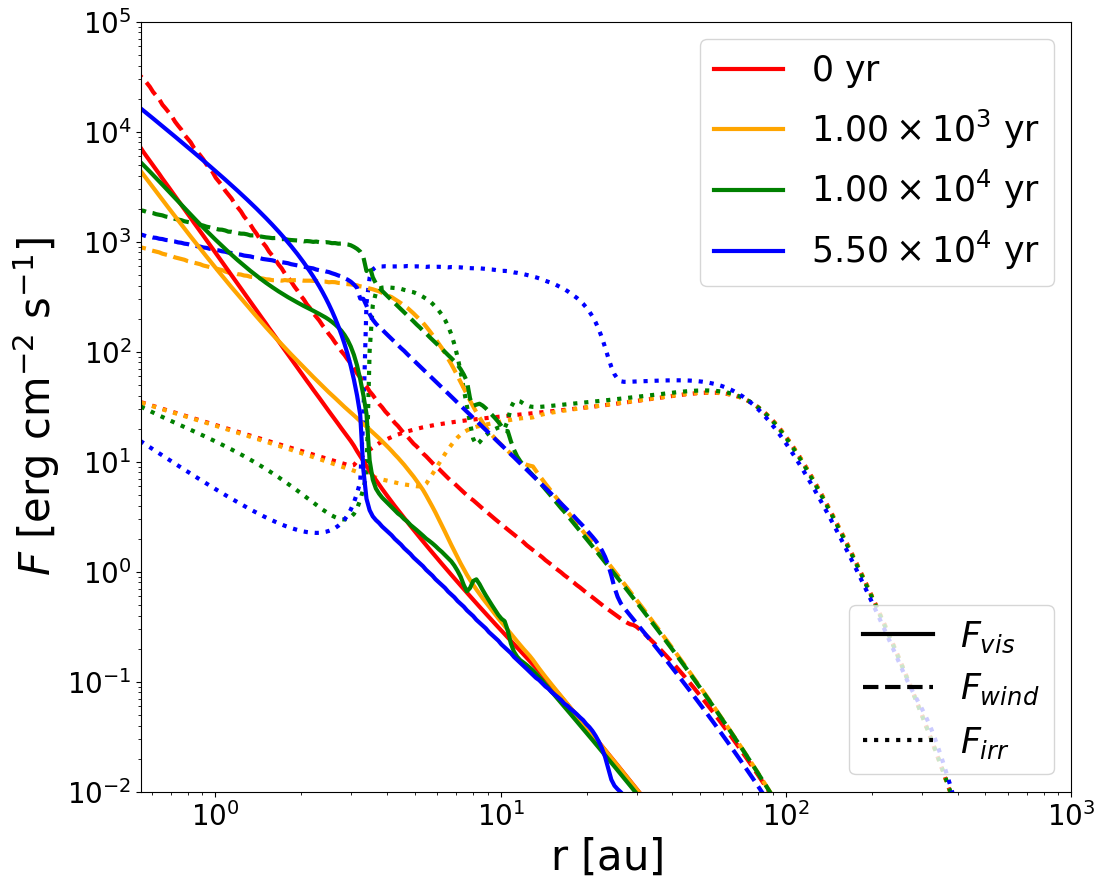

<Figure size 640x480 with 0 Axes>

In [8]:
# [旧 cell 10]
# ==================================
# Heating calculation
# ==================================

def calc_dBdr(X, B):
    nr = len(X)
    dBdr = np.zeros(nr)

    for i in range(nr):
        if 1 <= i <= nr - 2:
            s = X[i] - X[i-1]
            t = X[i+1] - X[i]

            coeff1 = s*s / (s*t*(s+t))
            coeff2 = (t*t - s*s) / (s*t*(s+t))
            coeff3 = -t*t / (s*t*(s+t))

            dBdr[i] = (
                coeff1 * B[i+1]
                + coeff2 * B[i]
                + coeff3 * B[i-1]
            )

        elif i == 0:
            logx_min = np.log(X[nr-1] / X[0]) / float(nr-1)
            x_min = X[0] * np.exp(-logx_min)

            s = X[i] - x_min
            t = X[i+1] - X[i]

            coeff1 = s*s / (s*t*(s+t))
            coeff2 = (t*t - s*s) / (s*t*(s+t))
            coeff3 = -t*t / (s*t*(s+t))

            # zero-gradient ghost cell: B[-1 ghost] = B[i]
            dBdr[i] = (
                coeff1 * B[i+1]
                + coeff2 * B[i]
                + coeff3 * B[i]
            )

        elif i == nr - 1:
            logx_max = np.log(X[nr-1] / X[0]) / float(nr-1)
            x_max = X[0] * np.exp(logx_max * nr)

            s = X[i] - X[i-1]
            t = x_max - X[i]

            coeff1 = s*s / (s*t*(s+t))
            coeff2 = (t*t - s*s) / (s*t*(s+t))
            coeff3 = -t*t / (s*t*(s+t))

            # zero-gradient ghost cell: B[+1 ghost] = B[i]
            dBdr[i] = (
                coeff1 * B[i]
                + coeff2 * B[i]
                + coeff3 * B[i-1]
            )

    return dBdr

def calc_heating(r, data_gas, data_B):
    """
    data_gas columns:
        0: r
        1: sigmag
        11: T

    data_B columns from C++ OutPut:
        0: r
        1: alpha_MRI
        2: B
        3: etaO
        4: etaA
        5: beta
    """
    # r = data_gas[0,:]
    sigmag = data_gas[1, :]
    T = data_gas[12, :]
    alpha_phiz =  data_gas[17, :]   # alpha_phiz (列 17). alpha_DW (列 24) ではない

    alpha = data_B[1, :]
    B = data_B[2, :]
    etaO = data_B[3, :]
    etaA = data_B[4, :]
    eta_tot = etaO + etaA

    omega = np.sqrt(G * Msolar / r**3)
    cs = np.sqrt(kB * T / (mu * mH))
    Hg = cs / omega
    rho_mid = sigmag / (np.sqrt(2.0 * np.pi) * Hg)

    Firr_ = []
    KR_ = []
    tauR_ = []
    tauP_ = []

    for i in range(len(T)):
        Tirr = 20.0*(r[i]/(100.0*AU))**-0.45
        if(Tirr < 10.0):
            Tirr = 10.0
        # energy.cpp RosselandOpacity() / Q_irr と同じ式
        KR = 2.25 * (1.0 - np.tanh( (T[i]-1.5e3)/1.5e2 ) ) * min(1.0, (T[i]/1.5e2)**2)
        tauR = KR*sigmag[i]
        tauP = max(2.4*tauR,0.5)
        F_irr = 8.0*tauR*sigma_SB/(3.0*tauR**2 + 1.0) * Tirr**4.0

        Firr_.append(F_irr)
        KR_.append(KR)
        tauR_.append(tauR)
        tauP_.append(tauP)

    dBdr = calc_dBdr(r, B)

    
    F_vis = 2.25 * np.sqrt(2.0 * np.pi) * rho_mid * cs**3 * alpha
    F_joule = eta_tot * dBdr**2 * sigmag / (4.0*np.pi*rho_mid)
    F_wind =  0.5*r*omega*alpha_phiz*rho_mid*cs**2

    return F_joule, F_vis,F_wind,Firr_, dBdr

# ジュール熱と粘性加熱の関係のプロット作る

# ==================================
# 物理定数
# ==================================
G = 6.6743e-8
Msolar = 1.989e33
kB = 1.380649e-16
mH = 1.6735575e-24
mu = 2.34
AU = 1.496e13

# ==================================
# 符号で線種を変える関数
# ==================================
def plot_sign_split(ax, X, Y, color="black", lw=3,alpha=1.0,label=" "):
    """Y>0 は実線、Y<0 は点線で描画する"""
    # 正の領域
    Y_pos = np.where(Y > 0, Y, np.nan)
    ax.plot(X, Y_pos, color=color, lw=lw, linestyle="solid",alpha=alpha,label=label)

    # 負の領域
    Y_neg = np.where(Y < 0, np.fabs(Y), np.nan)
    ax.plot(X, Y_neg, color=color, lw=lw, linestyle="dashed",alpha=alpha,label=label)

# ==================================
# ファイル設定
# ==================================
outdir = BASE_DIR
resultdir = MODEL
file0_3430 = "/out{}".format(SNAP_YEARS[0])
file1_3430 = "/out{}".format(SNAP_YEARS[0])
file2_3430 = "/out{}".format(SNAP_YEARS[1])
file3_3430 = "/out{}".format(SNAP_YEARS[2])
file4_3430 = "/out{}".format(SNAP_YEARS[2])
file5_3430 = "/out{}".format(SNAP_YEARS[3])

file0 = outdir + resultdir + file0_3430
file1 = outdir + resultdir + file1_3430
file2 = outdir + resultdir + file2_3430
file3 = outdir + resultdir + file3_3430
file4 = outdir + resultdir + file4_3430
file5 = outdir + resultdir + file5_3430

resultdir += "_B"

file0_B =  outdir + resultdir + file0_3430 + "_B"
file1_B =  outdir + resultdir + file1_3430 + "_B"
file2_B =  outdir + resultdir + file2_3430 + "_B"
file3_B =  outdir + resultdir + file3_3430 + "_B"
file4_B =  outdir + resultdir + file4_3430 + "_B"
file5_B =  outdir + resultdir + file5_3430 + "_B"

# ==================================
# Dust bin 情報
# ==================================
dmass = np.array([float(i) for i in linecache.getline(file1, 1).split()])
dmass_b = np.array([float(i) for i in linecache.getline(file1, 2).split()])
delta_mass = dmass_b[1:] - dmass_b[:-1]
dradius = np.array([float(i) for i in linecache.getline(file1, 3).split()])
dradius_b = np.array([float(i) for i in linecache.getline(file1, 4).split()])
linecache.clearcache()

# ==================================
# Dust データ読込
# ==================================
data0 = np.loadtxt(file0, dtype=float, skiprows=5).T
data1 = np.loadtxt(file1, dtype=float, skiprows=5).T
data2 = np.loadtxt(file2, dtype=float, skiprows=5).T
data3 = np.loadtxt(file3, dtype=float, skiprows=5).T
data4 = np.loadtxt(file4, dtype=float, skiprows=5).T
data5 = np.loadtxt(file5, dtype=float, skiprows=5).T

sigmad0 = data0[1:]
sigmad1 = data1[1:]
sigmad2 = data2[1:]
sigmad3 = data3[1:]
sigmad4 = data4[1:]
sigmad5 = data5[1:]

r = data0[0]
X = r

# ==================================
# Gas データ読込
# ==================================
file_gas = "_gas"
data0_gas = np.loadtxt(file0 + file_gas, dtype=float).T
data1_gas = np.loadtxt(file1 + file_gas, dtype=float).T
data2_gas = np.loadtxt(file2 + file_gas, dtype=float).T
data3_gas = np.loadtxt(file3 + file_gas, dtype=float).T
data4_gas = np.loadtxt(file4 + file_gas, dtype=float).T
data5_gas = np.loadtxt(file5 + file_gas, dtype=float).T

# ==================================
# B データ読込
# ==================================

data0_B = np.loadtxt(file0_B, dtype=float).T
data1_B = np.loadtxt(file1_B, dtype=float).T
data2_B = np.loadtxt(file2_B, dtype=float).T
data3_B = np.loadtxt(file3_B, dtype=float).T
data4_B = np.loadtxt(file4_B, dtype=float).T
data5_B = np.loadtxt(file5_B, dtype=float).T

year_color = {snap_label(y): c for y, c in zip(SNAP_YEARS, SNAP_COLORS)}

dict_style_P = {
    r"$ F_{vis} $" : "solid",
    r"$ F_{wind}$" : "dashed",
    r"$ F_{irr}$" : "dotted",
    # r"$ F_{joule} $" : "dotted"
}

# fig, axes = plt.subplots(1, 1)
# ax = axes
# plt.figure( figsize=(12,10))
J1_joule, J1_vis,J1_wind,J1_irr, dBdr1 = calc_heating(r, data0_gas, data0_B)
J2_joule, J2_vis,J2_wind,J2_irr, dBdr2 = calc_heating(r, data2_gas, data2_B)
J3_joule, J3_vis,J3_wind,J3irr, dBdr3 = calc_heating(r, data3_gas, data3_B)
J4_joule, J4_vis,J4_wind,J4irr, dBdr4 = calc_heating(r, data5_gas, data5_B)

X = r / AU

fig, ax = plt.subplots(1, 1,figsize = (12,10))

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(r_min, 1.0e3)
ax.set_ylim(1.0e-2, 1.0e5)
ax.set_xlabel(r"$ \rm{r} \ [au]$", fontsize=30)
ax.set_ylabel(r"$ F \ \rm{[\mathrm{erg \ cm^{-2} \ s^{-1} }]}  $", fontsize=30)
ax.tick_params(labelsize=20)

ax.plot(X, J1_irr, lw=3, color=SNAP_COLORS[0], linestyle="dotted")
ax.plot(X, J2_irr, lw=3, color=SNAP_COLORS[1], linestyle="dotted")
ax.plot(X, J3irr, lw=3, color=SNAP_COLORS[2], linestyle="dotted")
ax.plot(X, J4irr, lw=3, color=SNAP_COLORS[3], linestyle="dotted")
ax.plot(X, J1_wind, lw=3, color=SNAP_COLORS[0], linestyle="dashed")
ax.plot(X, J2_wind, lw=3, color=SNAP_COLORS[1], linestyle="dashed")
ax.plot(X, J3_wind, lw=3, color=SNAP_COLORS[2], linestyle="dashed")
ax.plot(X, J4_wind, lw=3, color=SNAP_COLORS[3], linestyle="dashed")

# ax.plot(X, J1_joule, lw=3, color="red", linestyle="dotted")
# ax.plot(X, J2_joule, lw=3, color="orange", linestyle="dotted")
# ax.plot(X, J3_joule, lw=3, color="green", linestyle="dotted")
# ax.plot(X, J4_joule, lw=3, color="blue", linestyle="dotted")

ax.plot(X, J1_vis, lw=3, color=SNAP_COLORS[0], linestyle="solid")
ax.plot(X, J2_vis, lw=3, color=SNAP_COLORS[1], linestyle="solid")
ax.plot(X, J3_vis, lw=3, color=SNAP_COLORS[2], linestyle="solid")
ax.plot(X, J4_vis, lw=3, color=SNAP_COLORS[3], linestyle="solid")

handles_color = []
for label, color in year_color.items():
    h, = ax.plot([], [], color=color, lw=3, label=label)
    handles_color.append(h)

legend1 = ax.legend(
    handles=handles_color,
    loc="upper right",
    fontsize=25
)
ax.add_artist(legend1)

handles_style = []
for label, style in dict_style_P.items():
    h, = ax.plot([], [], color="black", linestyle=style, lw=3, label=label)
    handles_style.append(h)

legend2 = ax.legend(
    handles=handles_style,
    loc="lower right",
    fontsize=25
)

plt.rcParams["savefig.transparent"] = False

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# fig.savefig(
#     FIG_DIR + "/windheating_1e5.png",
#     dpi=300,
#     facecolor="white",
#     edgecolor="white"
# )

plt.show()
plt.savefig(fig_path("heating.png", root=ANALYSIS_FIG_DIR))
# plt.savefig(fig_path("heating_wind5e5.png", root=ANALYSIS_FIG_DIR))

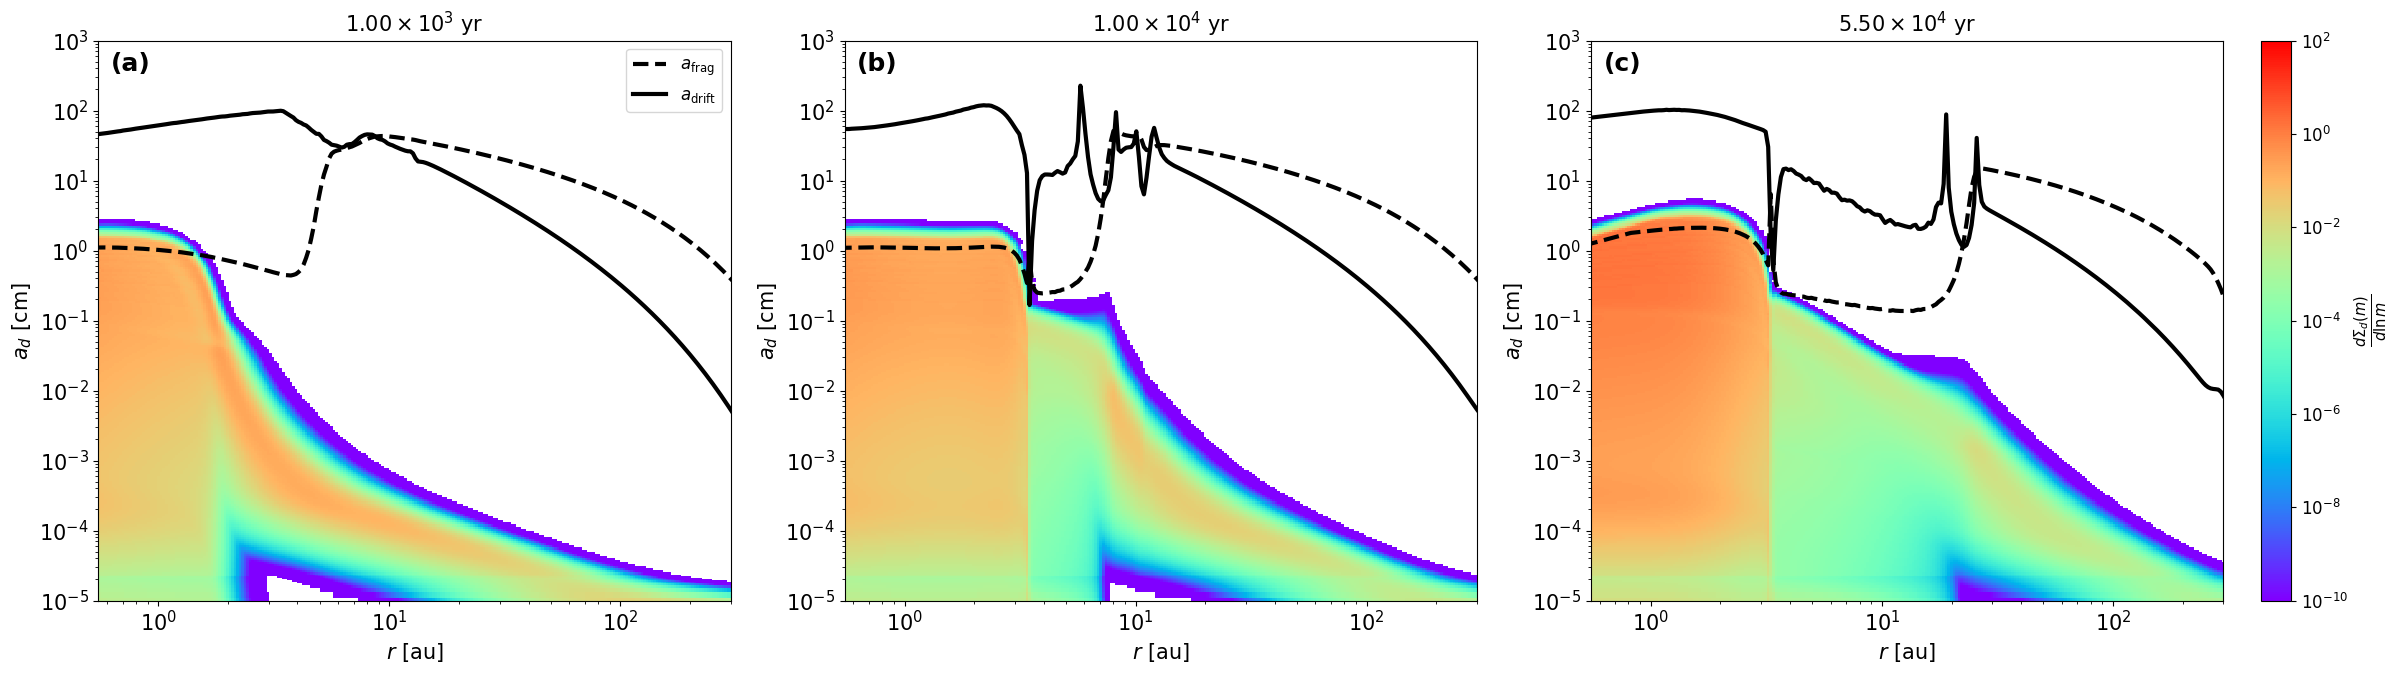

In [9]:
# [旧 cell 11]
# file_gas
# r_cen_[i] :0 sigmag_[i] :1 sigmad_tot_[i] :2 sigmad_vapor : 3 vg_r_[i] : 4 vg_phi_[i] :5 vg_wind_[i] :6 vd_r_tot[i][0] : 7 
# lambda1_[i]: 8 lambda2_[i] :9 dsigmagdt_w[i]:10 T_[i]:11 P_[i][nz_s] : 12 P_[i][nz_s]/beta_disk_[i][nz_s] : 13 Q_toomre[i] : 14 alpha_GI[i] : 15  
# alpha_phiz[i] : 16 alpha_tot[i] : 17 eta_P_[i] :18
# file_mag
# r_cen_[i] :0 alpha_MRI[i]:1 B_[i]:2 etaO_R[i]:3 etaA_R[i]:4 beta_disk_[i][nz_s]:5

# -------------------------
# 物理定数（必要に応じて修正）
# -------------------------
# t = 0 はダストが最小ビンだけなので描かない
files = []
for year in SNAP_YEARS:
    if year > 0:
        file_D = BASE_DIR + MODEL + "/out{}".format(year)
        file_B = BASE_DIR + MODEL + "_B/out{}_B".format(year)
        files.append((file_D, file_B, file_D + "_gas", snap_label(year)))

# -------------------------
# Dust map 計算部分
# -------------------------
def compute_map(file_D, file_B, file_G):

    # ----- Dust mass, radius -----
    dmass = np.array([float(i) for i in linecache.getline(file_D, 1).split()])
    dmass_b = np.array([float(i) for i in linecache.getline(file_D, 2).split()])
    dradius = np.array([float(i) for i in linecache.getline(file_D, 3).split()])
    dradius_b = np.array([float(i) for i in linecache.getline(file_D, 4).split()])
    linecache.clearcache()

    # ----- Main data -----
    data = np.loadtxt(file_D, dtype=float, skiprows=5).T
    data_alpha = np.loadtxt(file_B).T
    data_G = np.loadtxt(file_G, dtype=float).T

    r = data[0]                    # radial grid
    sigmad1 = data[1:]            # dust density per bin
    sigmad1 = np.where(np.abs(sigmad1) > 1.0e-15, sigmad1, np.nan)
    alpha = data_alpha[1]
    T = data_G[12]
    eta_P_ = data_G[19]
    #print(eta_P_)

    # ----- Gas properties -----
    sigma_h2 = 2.0e-15
    sig_g = []
    cs_ = []
    omega_ = []
    mfreep = []

    for i in range(len(r)):
        s_gas = data_G[1][i]
        omega = np.sqrt(G * Msolar / r[i]**3)
        cs = np.sqrt(kB * T[i] / (mu * mH)) 
        Hg = np.sqrt(kB * T[i] / (mu * mH)) / omega
        rhog = s_gas / (np.sqrt(2.0 * np.pi) * Hg)
        ng_mid = rhog / (mu * mH)
        mfp = 1.0 / (sigma_h2 * ng_mid)
        sig_g.append(s_gas)
        omega_.append(omega)
        cs_.append(cs)
        mfreep.append(mfp)
    
    # -------------------------
    # Fragmentation barrier
    # -------------------------
    f_f = 0.87
    #f_f = 1.0
    rho_in = 1.4
    amax1_f = []
    amax2_f = []

    for j in range(len(r)):
        c_s2 = kB * T[j] / (mu * mH)
        if T[j] < 1.6e2:
            u_frag = 1.0e3
        else:
            u_frag = 1.0e2
        w   = 0.5*(1.0 - np.tanh((T[j] - 1.6e2)/16.0))
        u_frag  = w*1.0e3 + (1.0-w)*1.0e2
        #u_frag = 1.0e3

        a_frag_ep = f_f * 2.0/(3.0*np.pi) * sig_g[j]*u_frag*u_frag/(rho_in * alpha[j] * c_s2) # Birnstiel et al. (2012) 
        a_frag_st = np.sqrt(f_f * 3.0*mfreep[j]/(2.0*np.pi) * sig_g[j]*u_frag*u_frag/(rho_in * alpha[j] * c_s2))
        # if(a_frag_ep < 2.25*mfreep[j]):
        #     a_frag = a_frag_ep
        # else:
        #     a_frag = a_frag_st
        #St_frag = (-3.0*alpha[j]*cs_[j]**2 + np.sqrt( (3.0*alpha[j]*cs_[j]**2)**2 + 4.0*(u_frag*eta_P_[j]*r[j]*omega_[j])**2))/(2.0*(eta_P_[j]*r[j]*omega_[j])**2) # Okuzumi 2016
        #a_frag = 2.0*sig_g[j]*St_frag/(rho_in*np.pi)
        # Epstein / Stokes をシームレスに切り替える (コードの抵抗則と同じ): Epstein の a が 9 lambda/4 以上なら Stokes の a
        amax1_f.append(a_frag_ep if a_frag_ep < 2.25 * mfreep[j] else a_frag_st)
        amax2_f.append(a_frag_st)

    # -------------------------
    # Drift barrier
    # -------------------------
    f_d = 0.55
    amax1_d = []
    sigmad1 = np.where(np.abs(sigmad1) > 1e-15, sigmad1, 0.0)

    for j in range(len(r)):
        sig_d = np.sum(sigmad1[:, j])
        # St_drift = f_d Sigma_d / (2 Sigma_g |eta_P|). Epstein: a = 2 Sigma_g St/(pi rho_s) , Stokes: a = sqrt(9 lambda Sigma_g St/(2 pi rho_s))
        St_d = f_d * sig_d / (2.0 * sig_g[j] * np.abs(eta_P_[j]))
        a_d_ep = 2.0 * sig_g[j] * St_d / (np.pi * rho_in)          # = f_d Sigma_d / (pi rho_s |eta_P|)
        a_d_st = np.sqrt(9.0 * mfreep[j] * sig_g[j] * St_d / (2.0 * np.pi * rho_in))
        amax1_d.append(a_d_ep if a_d_ep < 2.25 * mfreep[j] else a_d_st)
        
    # -------------------------
    # Stokes number St = 1, 0.1 の粒径
    # -------------------------
    a_st1  = []
    a_st01 = []

    for j in range(len(r)):
        a1  = (2.0/np.pi) * sig_g[j] / rho_in * 1.0     # St = 1
        a01 = (2.0/np.pi) * sig_g[j] / rho_in * 0.1     # St = 0.1
        a_st1.append(a1)
        a_st01.append(a01)

    # -------------------------
    # Epstein / Stokes 遷移境界 (a = 9λ/4)
    # -------------------------
    a_transition = [2.25 * mfreep[j] for j in range(len(r))]

    return r, dradius, sigmad1, amax1_f,amax2_f, amax1_d, a_st1, a_st01, a_transition

# ======================================================
# ここから 2×2 ミニマップ描画
# ======================================================
vmin = 10**-10
vmax = 10**2

fig, axes = plt.subplots(1, len(files), figsize=(25, 7), squeeze=False)
axes = axes.flatten()

for ax, (file_D, file_B, file_G, title) in zip(axes, files):

    r, dr, sigmad1, Y1, Y2, Y3, Y4,Y5, Y_trans = compute_map(file_D, file_B, file_G)

    X, Y = np.meshgrid(r / AU, dr)

    # pcolormesh
    pm = ax.pcolormesh(X, Y, sigmad1,
                       cmap=cm.rainbow, norm=LogNorm(vmin, vmax))

    # max size curves
    ax.plot(r/AU, Y1, color="black", lw=3, ls="--", label=r"$a_\mathrm{frag}$")
    # ax.plot(r/AU, Y2, color="black", lw=3, ls="-.", label=r"$a_\mathrm{frag,st}$")
    ax.plot(r/AU, Y3, color="black", lw=3, ls="-", label=r"$a_\mathrm{drift}$")
    # ax.plot(r/AU, Y_trans, color="gray", lw=2, ls=":", label=r"$9\lambda/4$ (Ep/St境界)")
    
    # ax.plot(r/AU, Y4, color="blue",  lw=2, ls=":", label=r"$ \rm{St} = 1.0 $")
    # ax.plot(r/AU, Y5, color="green", lw=2, ls=":", label=r"$ \rm{St} = 0.1 $")

    # scale
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$ r \ \mathrm{[au]} $",fontsize = 15)
    ax.set_ylabel(r"$ a_d \ \mathrm{[cm]} $",fontsize =15)
    
    ax.set_xlim(r_min, r_max)
    ax.set_ylim(1e-5, 1.0e3)

    ax.set_title(title, fontsize=15)
    ax.tick_params(labelsize=15)

    # legend 最初の1枚にだけ
    if ax is axes[0]:
        ax.legend(fontsize=12,loc="upper right")

# colorbar を共通化
fig.subplots_adjust(
    left=0.05,
    right=0.90,
    bottom=0.12,
    top=0.92,
    wspace=0.18
)
cbar = fig.colorbar(pm, cax=fig.add_axes([0.915, 0.12, 0.012, 0.80]), orientation="vertical")
cbar.set_label(r"$ \frac{d\Sigma_d(m)}{d\ln m}  $",fontsize = 15)
cbar.ax.tick_params(labelsize = 12)
# plt.tight_layout()
plt.savefig(fig_path("dust.png", root=ANALYSIS_FIG_DIR))
plt.show()

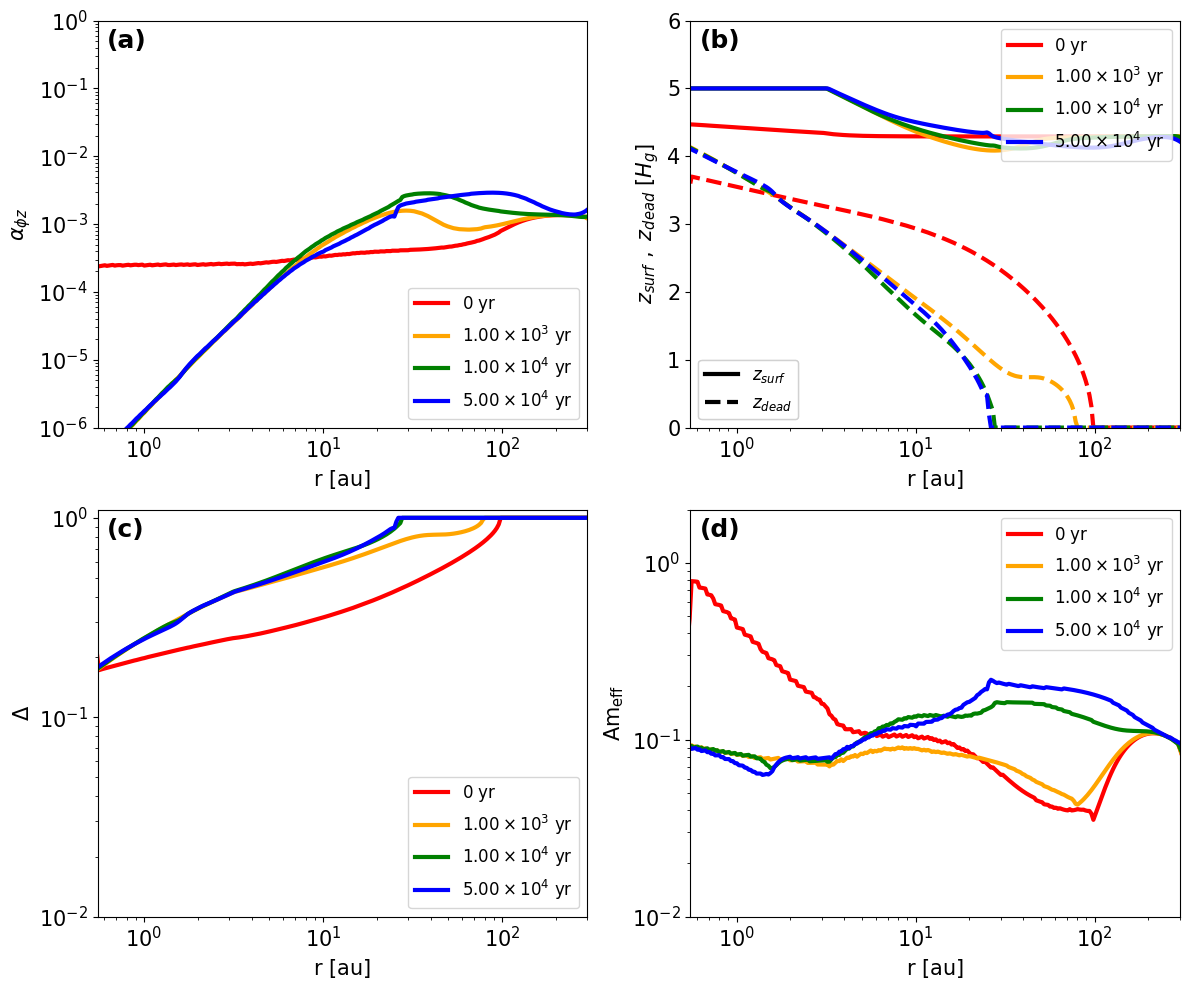

In [9]:
# [旧 cell 12]
# ======================================================
# alpha_phiz ・ z_surf/z_dead ・ Delta ・ Am_eff の2×2ミニマップ
# Enomoto et al. (2026) self-consistent alpha_DW モデルの診断量
# file_gas 列: ... 20:z_dead 21:z_surf 22:Delta 23:Am_eff 17:alpha_phiz(= 0.75 sqrt(2 pi) (H_g/r) alpha_DW)  (24:alpha_DW)
# z_dead, z_surf は [Hg]（スケールハイト単位）
# ======================================================

G = 6.6743e-8
Msolar = 1.989e33
kB = 1.380649e-16
mH = 1.6735575e-24
mu = 2.34
AU = 1.496e13

outdir = BASE_DIR
resultdir = MODEL
file0_3430 = "/out{}".format(SNAP_YEARS[0])
file2_3430 = "/out{}".format(SNAP_YEARS[1])
file3_3430 = "/out{}".format(SNAP_YEARS[2])
file5_3430 = "/out{}".format(SNAP_YEARS[3])
file0 = outdir + resultdir + file0_3430
file2 = outdir + resultdir + file2_3430
file3 = outdir + resultdir + file3_3430
file5 = outdir + resultdir + file5_3430

file_gas = "_gas"
data0_gas = np.loadtxt(file0 + file_gas, dtype=float).T
data2_gas = np.loadtxt(file2 + file_gas, dtype=float).T
data3_gas = np.loadtxt(file3 + file_gas, dtype=float).T
data5_gas = np.loadtxt(file5 + file_gas, dtype=float).T

r = data0_gas[0]
X = r / AU

year_color = {snap_label(y): c for y, c in zip(SNAP_YEARS, SNAP_COLORS)}

dict_style_zsurf = {
   r"$ z_{surf} $" : "solid",
   r"$ z_{dead} $" : "dashed",
}

datasets = [data0_gas, data2_gas, data3_gas, data5_gas]
colors = list(year_color.values())

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# ==================================
# (0,0) alpha_phiz (gas 列 17)
# ==================================
ax = axes[0, 0]
ax.set_xlabel(r"$ \rm{r} \ [au]$", fontsize=15)
ax.set_ylabel(r"$ \alpha_{\phi z} $", fontsize=15)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(r_min, r_max)
ax.set_ylim(1e-6, 1e0)
ax.tick_params(labelsize=15)

for data, color in zip(datasets, colors):
    ax.plot(X, data[17, :], color=color, lw=3)

handles_color = []
for label, color in year_color.items():
    h, = ax.plot([], [], color=color, lw=3, label=label)
    handles_color.append(h)
ax.legend(handles=handles_color, loc="lower right", fontsize=12)

# ==================================
# (0,1) z_surf & z_dead
# ==================================
ax = axes[0, 1]
ax.set_xlabel(r"$ \rm{r} \ [au]$", fontsize=15)
ax.set_ylabel(r"$ z_{surf} \ , \ z_{dead} \ [H_g]$", fontsize=15)
ax.set_xscale("log")
# ax.set_yscale("log")
ax.set_xlim(r_min, r_max)
# ax.set_ylim(1e-5, 1e1)
ax.set_ylim(0.0, 6e0)
ax.tick_params(labelsize=15)

for data, color in zip(datasets, colors):
    ax.plot(X, data[21, :], color=color, lw=3, linestyle="solid")
    ax.plot(X, data[20, :], color=color, lw=3, linestyle="dashed")

handles_color = []
for label, color in year_color.items():
    h, = ax.plot([], [], color=color, lw=3, label=label)
    handles_color.append(h)
legend1 = ax.legend(handles=handles_color, loc="upper right", fontsize=12)
ax.add_artist(legend1)

handles_style = []
for label, style in dict_style_zsurf.items():
    h, = ax.plot([], [], color="black", linestyle=style, lw=3, label=label)
    handles_style.append(h)
legend2 = ax.legend(handles=handles_style, loc="lower left", fontsize=12)
ax.add_artist(legend2)

# ==================================
# (1,0) Delta (normalized active-layer thickness)
# ==================================
ax = axes[1, 0]
ax.set_xlabel(r"$ \rm{r} \ [au]$", fontsize=15)
ax.set_ylabel(r"$ \Delta $", fontsize=15)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(r_min, r_max)
ax.set_ylim(1.0e-2, 1.1e0)
ax.tick_params(labelsize=15)

for data, color in zip(datasets, colors):
    ax.plot(X, data[22, :], color=color, lw=3)

handles_color = []
for label, color in year_color.items():
    h, = ax.plot([], [], color=color, lw=3, label=label)
    handles_color.append(h)
ax.legend(handles=handles_color, loc="lower right", fontsize=12)

# ==================================
# (1,1) Am_eff
# ==================================
ax = axes[1, 1]
ax.set_xlabel(r"$ \rm{r} \ [au]$", fontsize=15)
ax.set_ylabel(r"$ \rm{Am_{eff}} $", fontsize=15)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(r_min, r_max)
ax.set_ylim(1.0e-2, 2e0)
ax.tick_params(labelsize=15)

for data, color in zip(datasets, colors):
    ax.plot(X, data[23, :], color=color, lw=3)

handles_color = []
for label, color in year_color.items():
    h, = ax.plot([], [], color=color, lw=3, label=label)
    handles_color.append(h)
ax.legend(handles=handles_color, loc="upper right", fontsize=12)

plt.tight_layout()
plt.savefig(fig_path("DW.png", root=ANALYSIS_FIG_DIR))
# plt.savefig(fig_path("windDW_diag.png", root=ANALYSIS_FIG_DIR))
plt.show()

## 速度・フラックス・ストークス数

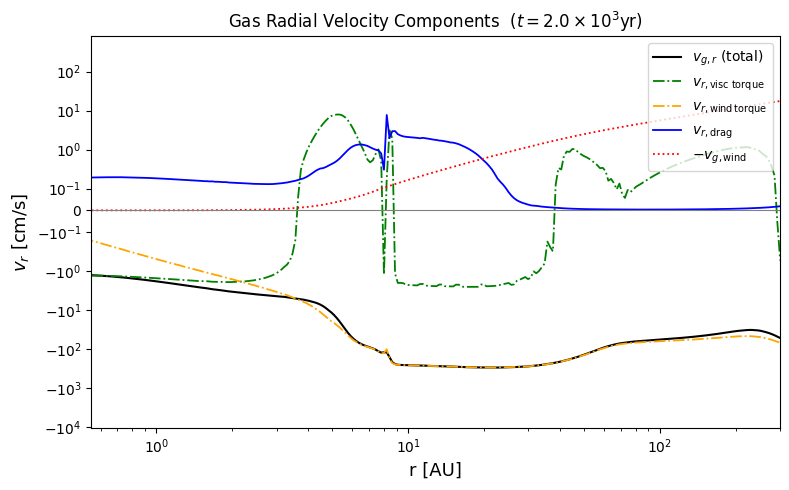

In [9]:
# [旧 cell 19]
# ============================================================
# ガス動径速度の成分分解 (トルク / ダスト反作用 / wind質量損失) と検証
#
# コード (dust_disk.cpp CalcGasVelocity_TM2018) の式:
#   vg_r = [ 2*dNdr_torque*(1+lambda2)/vK + 2*lambda1*(1+A)*vK*eta_P ] / denom - vg_wind
#          |----- (1) トルク: visc + wind-torque -----| |-- (2) ダスト反作用 (圧力勾配駆動のドリフトの反作用) --|  (3) wind質量損失
#   denom = (1+lambda2)^2 + lambda1^2*(1+A)
# 保存済みの列をそのまま使い(再導出しない)、コードと同じ式で組み立てる:
#   dNdr_torque(col15), eta_P(col19), vg_wind(col6), alpha_DW(col24)
#   wind-torque: dNdr_wind = -0.75*alpha_DW*cs^2 ,  visc: dNdr_visc = col15 - dNdr_wind
#   M_in = star_mass + 累積 pi*Sigma_g*r_vol (dust_disk.cpp:1206-1212), Omega = sqrt(G M_in / r^3)
# 注意: 動径グリッドは log (radial_grid_type = log) を仮定。
# 速度はなましをかけずにそのまま描く。
# ============================================================

AU  = 1.495979e+13  # cm

outdir     = BASE_DIR + MODEL
# outdir_B   = '../beta2_data_3e5yr' 

time_label = str(SNAP_YEAR)


def reconstruct_gas_velocity(outdir, time_label, star_mass_msun=1.0, rho_dust=1.4):
    """保存済み出力からコードと同じ式で vg_r の各成分を再構成する(生の値)。"""
    G_cgs = 6.67408e-08; kB = 1.38064852e-16; Msolar = 1.989e+33
    m_gas = 2.34 * 1.672621898e-24        # GAS_MOLECULAR_MASS = 2.34 * PROTON_MASS
    sigma_H2 = 2.0e-15

    gas = np.loadtxt(outdir + '/out' + time_label + '_gas')
    r_cm        = gas[:, 0]
    sigmag      = gas[:, 1]
    vg_r        = gas[:, 4]
    vg_wind     = gas[:, 6]
    T           = gas[:, 12]
    dNdr_torque = gas[:, 15]
    alpha_WIND  = gas[:, 24]
    eta_P       = gas[:, 19]

    dust_file = outdir + '/out' + time_label
    with open(dust_file, 'r') as f:
        f.readline(); f.readline()
        a_bins = np.array(f.readline().split(), dtype=float)
    sigmad = np.loadtxt(dust_file, skiprows=5)[:, 1:]          # (nr, nbin)

    cs2 = kB * T / m_gas
    cs  = np.sqrt(cs2)

    # 内側質量 M_in (log グリッド: r_cen = sqrt(r_bod[i] r_bod[i+1]))
    q = r_cm[1:] / r_cm[:-1]
    if not np.allclose(q, q[0], rtol=1e-6):
        print('WARNING: radial grid is not logarithmic; M_in reconstruction is approximate')
    r_lo = r_cm / np.sqrt(q[0]); r_hi = r_cm * np.sqrt(q[0])
    dM = np.pi * sigmag * (r_hi**2 - r_lo**2)
    dM[0] = np.pi * sigmag[0] * r_hi[0]**2                      # zero-gradient inner boundary
    M_in = star_mass_msun * Msolar + np.cumsum(dM)

    Omega = np.sqrt(G_cgs * M_in / r_cm**3)
    vK    = r_cm * Omega
    Hg    = cs / Omega
    A     = 2.0 * np.pi * r_cm**2 * sigmag / M_in
    C1    = 1.0 + A

    rhog_mid = sigmag / (np.sqrt(2.0*np.pi) * Hg)
    ng_mid   = rhog_mid / m_gas
    mfp      = 1.0 / (ng_mid * sigma_H2)
    a2 = a_bins[None, :]
    St = np.where(a2 < 2.25 * mfp[:, None],
                  0.5*np.pi*rho_dust*a2 / sigmag[:, None],
                  (2.0*np.pi/9.0)*rho_dust*a2**2 / (mfp[:, None]*sigmag[:, None]))
    fdg = sigmad / sigmag[:, None]
    fdg[fdg < 1.0e-20] = 0.0
    lam1 = np.sum(St*fdg / (1.0 + C1[:, None]*St**2), axis=1)
    lam2 = np.sum(fdg    / (1.0 + C1[:, None]*St**2), axis=1)
    denom = (1.0 + lam2)**2 + lam1**2 * (1.0 + A)

    dNdr_wind = -0.75 * alpha_WIND * cs2
    dNdr_visc = dNdr_torque - dNdr_wind

    v_visc       = 2.0 * dNdr_visc * (1.0 + lam2) / vK / denom
    v_windtorque = 2.0 * dNdr_wind * (1.0 + lam2) / vK / denom
    v_drag      = 2.0 * lam1 * (1.0 + A) * vK * eta_P / denom
    v_windloss   = -vg_wind

    low = sigmag <= 1.0e-4                                       # code sets vg_r = 0 there
    for v in (v_visc, v_windtorque, v_drag, v_windloss):
        v[low] = 0.0
    v_sum = v_visc + v_windtorque + v_drag + v_windloss
    return dict(r=r_cm, vg_r=vg_r, vg_wind=vg_wind, v_visc=v_visc,
                v_windtorque=v_windtorque, v_drag=v_drag,
                v_windloss=v_windloss, v_sum=v_sum)

comp = reconstruct_gas_velocity(outdir, time_label)
r = comp['r'] / AU

# # ----- 足し算の検証: 成分の和 vs 保存済み vg_r (生の値) -----
# rel = np.abs(comp['v_sum'] - comp['vg_r']) / np.maximum(np.abs(comp['vg_r']), 1.0e-30)
# for lo, hi in [(0.5, 1.0), (1.0, 10.0), (10.0, 100.0), (100.0, 300.0)]:
#     m = (r >= lo) & (r < hi)
#     if m.any():
#         print(f'{lo:6.1f} - {hi:6.1f} au : |sum - vg_r|/|vg_r|  median = {np.median(rel[m]):.2e}, max = {rel[m].max():.2e}')

# ----- Plot (速度はなましなし) -----
linthresh = 1.0e-1

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(r, comp['vg_r'], color='black', linewidth=1.5, label=r'$v_{g,r}$ (total)')
# ax.plot(r, comp['vg_r'] + comp['vg_wind'], color='purple', linewidth=1.3, linestyle='--',
#         label=r'$v_{g,r}+v_{g,\rm wind}$ (torque+drag)')
ax.plot(r, comp['v_visc'],       color='green',  linewidth=1.3, linestyle='-.', label=r'$v_{r,\rm visc\ torque}$')
ax.plot(r, comp['v_windtorque'], color='orange', linewidth=1.3, linestyle='-.', label=r'$v_{r,\rm wind\,torque}$')
ax.plot(r, comp['v_drag'],      color='blue',   linewidth=1.3, linestyle='-',  label=r'$v_{r,\rm drag}$')
ax.plot(r, comp['v_windloss'],   color='red',    linewidth=1.3, linestyle=':',  label=r'$-v_{g,\rm wind}$')
#ax.plot(r, comp['v_sum'],        color='gray',   linewidth=2.5, linestyle='--', alpha=0.6, label='sum of components')
ax.axhline(0, color='gray', linewidth=0.8, linestyle='-')

ax.set_xscale('log')
ax.set_yscale('symlog', linthresh=linthresh, linscale=0.5)
ax.set_xlabel('r [AU]', fontsize=13)
ax.set_ylabel(r'$v_r$ [cm/s]', fontsize=13)
ax.set_xlim(r_min,r_max)
ax.set_title(r'Gas Radial Velocity Components  ($ t = 2.0 \times 10^3 \mathrm{yr}$)', fontsize=12)
ax.legend(fontsize=10,loc="upper right")
plt.tight_layout()
# plt.savefig(fig_path('fig1_gas3e4_velocity.png', root=ANALYSIS_FIG_DIR), dpi=150, bbox_inches='tight')
plt.show()

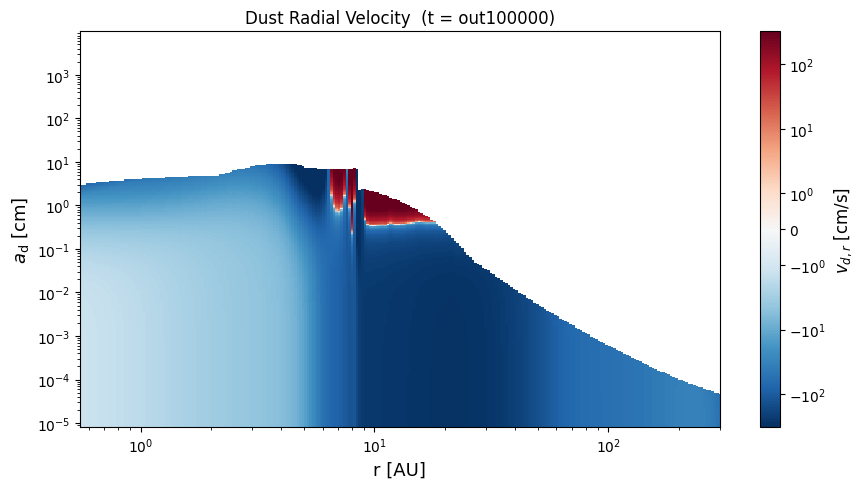

In [10]:
# [旧 cell 20]
# ============================================================
# ?2: ????????????????????
#   x?: r [AU],  y?: a_d [cm],  ??????: ?? [cm/s]
# Stokes number:
#   a < 2.25 * lambda_mfp  -> Epstein: St = pi/2 * a * rho_d / Sigma_g
#   a >= 2.25 * lambda_mfp -> Stokes:  St = 2pi/9 * a^2 * rho_d / (lambda_mfp * Sigma_g)
#   lambda_mfp = 1 / (n_g_mid * sigma_H2),  sigma_H2 = 2e-15 cm^2
#   n_g_mid = Sigma_g / (sqrt(2pi) * Hg * mu * mH)
#   Hg = cs / OmegaK,  cs = sqrt(kB*T / (mu*mH))
# sigmad_active <= 0 ??? (???????????) ????????
# ============================================================

AU       = 1.495979e+13   # cm
G        = 6.67408e-08    # cgs
Msolar   = 1.989e+33      # g
kB       = 1.38064852e-16 # erg/K
mH       = 1.67353e-24    # g
mu       = 2.34           # mean molecular weight
sigma_H2 = 2.0e-15        # cm^2  (H2 collision cross-section)
rho_dust = 1.4            # g/cm^3  (material density)

outdir     = BASE_DIR + MODEL
time_label = str(SNAP_YEAR)
gas_file   = outdir + '/out' + time_label + '_gas'
dust_file  = outdir + '/out' + time_label

# ----- Load gas data -----
data_gas  = np.loadtxt(gas_file)
r         = data_gas[:, 0]        # [cm]
sigmag    = data_gas[:, 1]        # [g/cm^2]
vg_r      = data_gas[:, 4]        # [cm/s]
vg_phi    = data_gas[:, 5]        # [cm/s]
vg_wind   = data_gas[:, 6]        # [cm/s]
T         = data_gas[:, 12]       # [K]

vK        = np.sqrt(G * Msolar / r)
dvg_phi   = vg_phi - vK
OmegaK    = vK / r                               # [rad/s]
cs        = np.sqrt(kB * T / (mu * mH))          # sound speed [cm/s]
Hg        = cs / OmegaK                          # gas scale height [cm]
rhog_mid  = sigmag / (np.sqrt(2.0*np.pi) * Hg)  # midplane density [g/cm^3]
ng_mid    = rhog_mid / (mu * mH)                 # midplane number density [1/cm^3]
lambda_mfp = 1.0 / (ng_mid * sigma_H2)           # mean free path [cm]

# ----- Load dust size bins (header line 3) and sigmad_active -----
with open(dust_file, 'r') as f:
    f.readline()
    f.readline()
    a_bins = np.array(f.readline().split(), dtype=float)  # dust sizes [cm]

data_dust = np.loadtxt(dust_file, skiprows=5)   # shape: (nr, 1+nbin)
sigmad    = data_dust[:, 1:]                     # shape: (nr, nbin)

# ----- Stokes number: Epstein or Stokes regime -----
# a_bins: (nbin,)  lambda_mfp: (nr,)
A_2D   = a_bins[np.newaxis, :]                          # (1, nbin)
L_2D   = lambda_mfp[:, np.newaxis]                      # (nr, 1)
SG_2D  = sigmag[:, np.newaxis]                          # (nr, 1)

St_Ep  = (np.pi / 2.0) * A_2D * rho_dust / SG_2D               # Epstein
St_St  = (2.0*np.pi / 9.0) * A_2D**2 * rho_dust / (L_2D * SG_2D)  # Stokes
St     = np.where(A_2D < 2.25 * L_2D, St_Ep, St_St)            # (nr, nbin)

# ----- Dust radial velocity -----
vd_r   = (vg_r[:,None] + 2.0*St*dvg_phi[:,None] - St**2*vg_wind[:,None]) / (1.0 + St**2)
vd_r   = vd_r

# ----- ???: ???????????? (sigmad == 0) ??? NaN ? -----
SIGMAD_MIN = 1.0e-15  # g/cm^2 -- below this, treat bin as numerical noise near sigmad_floor_
vd_r[sigmad < SIGMAD_MIN] = np.nan

# ----- Plot -----
r_AU = r / AU
vmax = np.nanpercentile(np.abs(vd_r[np.isfinite(vd_r)]), 98)
norm = SymLogNorm(linthresh=1.0, linscale=0.5, vmin=-vmax, vmax=vmax)

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.pcolormesh(r_AU, a_bins, vd_r.T,
                   norm=norm, cmap='RdBu_r', shading='auto')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('r [AU]', fontsize=13)
ax.set_ylabel(r'$a_{\rm d}$ [cm]', fontsize=13)
ax.set_xlim(r_min,r_max)
ax.set_title('Dust Radial Velocity  (t = out' + time_label + ')', fontsize=12)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label(r'$v_{d,r}$ [cm/s]', fontsize=12)
plt.tight_layout()
plt.savefig(fig_path('dust_vr_' + time_label + '.png', root=ANALYSIS_FIG_DIR), dpi=150, bbox_inches='tight')
plt.show()

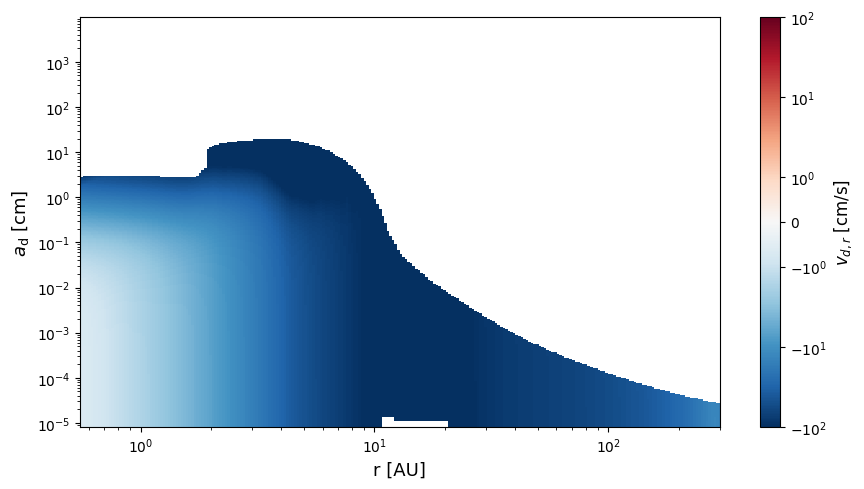

In [9]:
# [旧 cell 22]
# ============================================================
# ?2: ????????????????????
#   x?: r [AU],  y?: a_d [cm],  ??????: ?? [cm/s]
# Stokes number:
#   a < 2.25 * lambda_mfp  -> Epstein: St = pi/2 * a * rho_d / Sigma_g
#   a >= 2.25 * lambda_mfp -> Stokes:  St = 2pi/9 * a^2 * rho_d / (lambda_mfp * Sigma_g)
#   lambda_mfp = 1 / (n_g_mid * sigma_H2),  sigma_H2 = 2e-15 cm^2
#   n_g_mid = Sigma_g / (sqrt(2pi) * Hg * mu * mH)
#   Hg = cs / OmegaK,  cs = sqrt(kB*T / (mu*mH))
# sigmad_active <= 0 ??? (???????????) ????????
# ============================================================

AU       = 1.495979e+13   # cm
G        = 6.67408e-08    # cgs
Msolar   = 1.989e+33      # g
kB       = 1.38064852e-16 # erg/K
mH       = 1.67353e-24    # g
mu       = 2.34           # mean molecular weight
sigma_H2 = 2.0e-15        # cm^2  (H2 collision cross-section)
rho_dust = 1.4            # g/cm^3  (material density)

outdir     = BASE_DIR + MODEL
time_label = str(SNAP_YEAR)
gas_file   = outdir + '/out' + time_label + '_gas'
dust_file  = outdir + '/out' + time_label

# ----- Load gas data -----
data_gas  = np.loadtxt(gas_file)
r         = data_gas[:, 0]        # [cm]
sigmag    = data_gas[:, 1]        # [g/cm^2]
vg_r      = data_gas[:, 4]        # [cm/s]
vg_phi    = data_gas[:, 5]        # [cm/s]
vg_wind   = data_gas[:, 6]        # [cm/s]
T         = data_gas[:, 12]       # [K]

vK        = np.sqrt(G * Msolar / r)
dvg_phi   = vg_phi - vK
OmegaK    = vK / r                               # [rad/s]
cs        = np.sqrt(kB * T / (mu * mH))          # sound speed [cm/s]
Hg        = cs / OmegaK                          # gas scale height [cm]
rhog_mid  = sigmag / (np.sqrt(2.0*np.pi) * Hg)  # midplane density [g/cm^3]
ng_mid    = rhog_mid / (mu * mH)                 # midplane number density [1/cm^3]
lambda_mfp = 1.0 / (ng_mid * sigma_H2)           # mean free path [cm]

# ----- Load dust size bins (header line 3) and sigmad_active -----
with open(dust_file, 'r') as f:
    f.readline()
    f.readline()
    a_bins = np.array(f.readline().split(), dtype=float)  # dust sizes [cm]

data_dust = np.loadtxt(dust_file, skiprows=5)   # shape: (nr, 1+nbin)
sigmad    = data_dust[:, 1:]                     # shape: (nr, nbin)

# ----- Stokes number: Epstein or Stokes regime -----
# a_bins: (nbin,)  lambda_mfp: (nr,)
A_2D   = a_bins[np.newaxis, :]                          # (1, nbin)
L_2D   = lambda_mfp[:, np.newaxis]                      # (nr, 1)
SG_2D  = sigmag[:, np.newaxis]                          # (nr, 1)

St_Ep  = (np.pi / 2.0) * A_2D * rho_dust / SG_2D               # Epstein
St_St  = (2.0*np.pi / 9.0) * A_2D**2 * rho_dust / (L_2D * SG_2D)  # Stokes
St     = np.where(A_2D < 2.25 * L_2D, St_Ep, St_St)            # (nr, nbin)

# ----- Dust radial velocity -----
vd_r   = (vg_r[:,None] + 2.0*St*dvg_phi[:,None] - St**2*vg_wind[:,None]) / (1.0 + St**2)
vd_r   = vd_r

# ----- ???: ???????????? (sigmad == 0) ??? NaN ? -----
SIGMAD_MIN = 1.0e-15  # g/cm^2 -- below this, treat bin as numerical noise near sigmad_floor_
vd_r[sigmad < SIGMAD_MIN] = np.nan
flux_dust_r = sigmad*vd_r
# ----- Plot -----
r_AU = r / AU
#vmax = np.nanpercentile(np.abs(vd_r[np.isfinite(vd_r)]), 98)
vmax = 1.0e2
norm = SymLogNorm(linthresh=1.0, linscale=0.5, vmin=-vmax, vmax=vmax)

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.pcolormesh(r_AU, a_bins, vd_r.T,
                   norm=norm, cmap='RdBu_r', shading='auto')
# im = ax.pcolormesh(r_AU, a_bins, flux_dust_r.T,
#                    norm=norm, cmap='RdBu_r', shading='auto')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('r [AU]', fontsize=13)
ax.set_ylabel(r'$a_{\rm d}$ [cm]', fontsize=13)
ax.set_xlim(r_min,r_max)
# ax.set_title('Dust Radial Velocity  (t = out' + time_label + ')', fontsize=12)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label(r'$ v_{d,r}$ [cm/s]', fontsize=12)
#cbar.set_label(r'$ \Sigma_{d}(m) v_{d,r}$  [g cm$^{-2}$ s$^{-1}$]', fontsize=12)
plt.tight_layout()
plt.savefig(fig_path('dust_vr_fixed_' + time_label + '.png', root=ANALYSIS_FIG_DIR), dpi=150, bbox_inches='tight')
plt.show()

/tmp/ipykernel_961980/2870736915.py:23: RuntimeWarning: overflow encountered in divide
  vd_diff[active] = -Dd[active] * dfdg_dr[active] / fdg_ratio[active]
/tmp/ipykernel_961980/2870736915.py:26: RuntimeWarning: overflow encountered in square
  vd_diff *= (1.0 + R) / (1.0 + R + R**2)


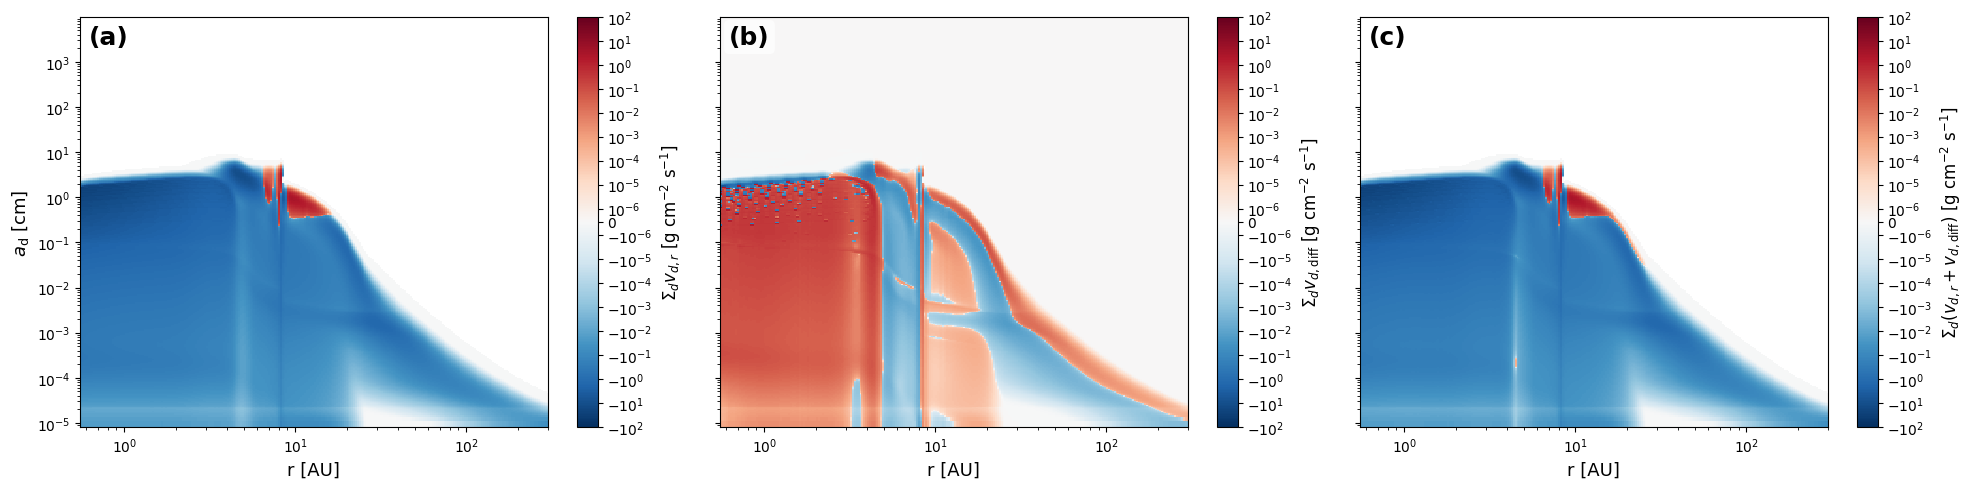

In [11]:
# [旧 cell 23]
# ============================================================
# ============================================================
# Dust diffusion and total radial MASS FLUX for all size bins
# flux = sigmad * v ; since v_diff = -D*(df/dr)/f, flux_diff = -D*sigmag*(df/dr)
# -- the 1/f division cancels, so unlike v_diff this never blows up even
# where sigmad (and f) are numerically negligible. No masking needed.
# Same definitions as DustDisk::CalcDustVelocity_TM2018 / CalcDustFlux
# ============================================================

# alpha_tot and alpha_GI are gas-file columns 18 and 16.
alpha_MRI = np.maximum(data_gas[:, 18] - data_gas[:, 16], 0.0)
nu_turb = alpha_MRI * cs * Hg
Dd = nu_turb[:, None] / (1.0 + St**2)

fdg_ratio = sigmad / sigmag[:, None]
dfdg_dr = np.gradient(fdg_ratio, r, axis=0, edge_order=2)
dfdg_dr[[0, -1], :] = 0.0  # boundary treatment in dust_disk.cpp

active = fdg_ratio > 0.0

vd_diff = np.zeros_like(vd_r)
vd_diff[active] = -Dd[active] * dfdg_dr[active] / fdg_ratio[active]
R = vd_diff / (np.sqrt(alpha_MRI) * cs)[:, None]
R[~np.isfinite(R)] = 0.0
vd_diff *= (1.0 + R) / (1.0 + R + R**2)
vd_total = vd_r + vd_diff

flux_adv  = sigmad * vd_r
flux_diff = sigmad * vd_diff
flux_total = sigmad * vd_total

r_AU = r / AU
fields = [flux_adv, flux_diff, flux_total]
# titles = [r'Dust advection flux $\Sigma_d v_{d,r}$',
#           r'Dust diffusion flux $\Sigma_d v_{d,\mathrm{diff}}$',
#           r'Dust total flux $\Sigma_d \left(v_{d,r}+v_{d,\mathrm{diff}}\right)$']
cbar_labels = [r'$\Sigma_d v_{d,r}$ [g cm$^{-2}$ s$^{-1}$]',
               r'$\Sigma_d v_{d,\mathrm{diff}}$ [g cm$^{-2}$ s$^{-1}$]',
               r'$\Sigma_d \left(v_{d,r}+v_{d,\mathrm{diff}}\right)$ [g cm$^{-2}$ s$^{-1}$]']

fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)
for ax, field, cbar_label in zip(axes, fields, cbar_labels):
    finite = np.abs(field[np.isfinite(field)])
    # vmax = np.nanpercentile(finite, 98) if finite.size else 1.0
    # vmax = max(vmax, 1.0e-12)
    vmax = 1.0e2
    norm = SymLogNorm(linthresh=1.0e-6, linscale=0.5,
                      vmin=-vmax, vmax=vmax)
    im = ax.pcolormesh(r_AU, a_bins, field.T, norm=norm,
                       cmap='RdBu_r', shading='auto')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(r_min, r_max)
    ax.set_xlabel('r [AU]', fontsize=13)
    # ax.set_title(title + ' (t = out' + time_label + ')', fontsize=12)
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(cbar_label, fontsize=12)
axes[0].set_ylabel(r'$a_{\rm d}$ [cm]', fontsize=13)
plt.tight_layout()
plt.savefig(fig_path('dustflux_total_' + time_label + '.png', root=ANALYSIS_FIG_DIR), dpi=150, bbox_inches='tight')
plt.show()

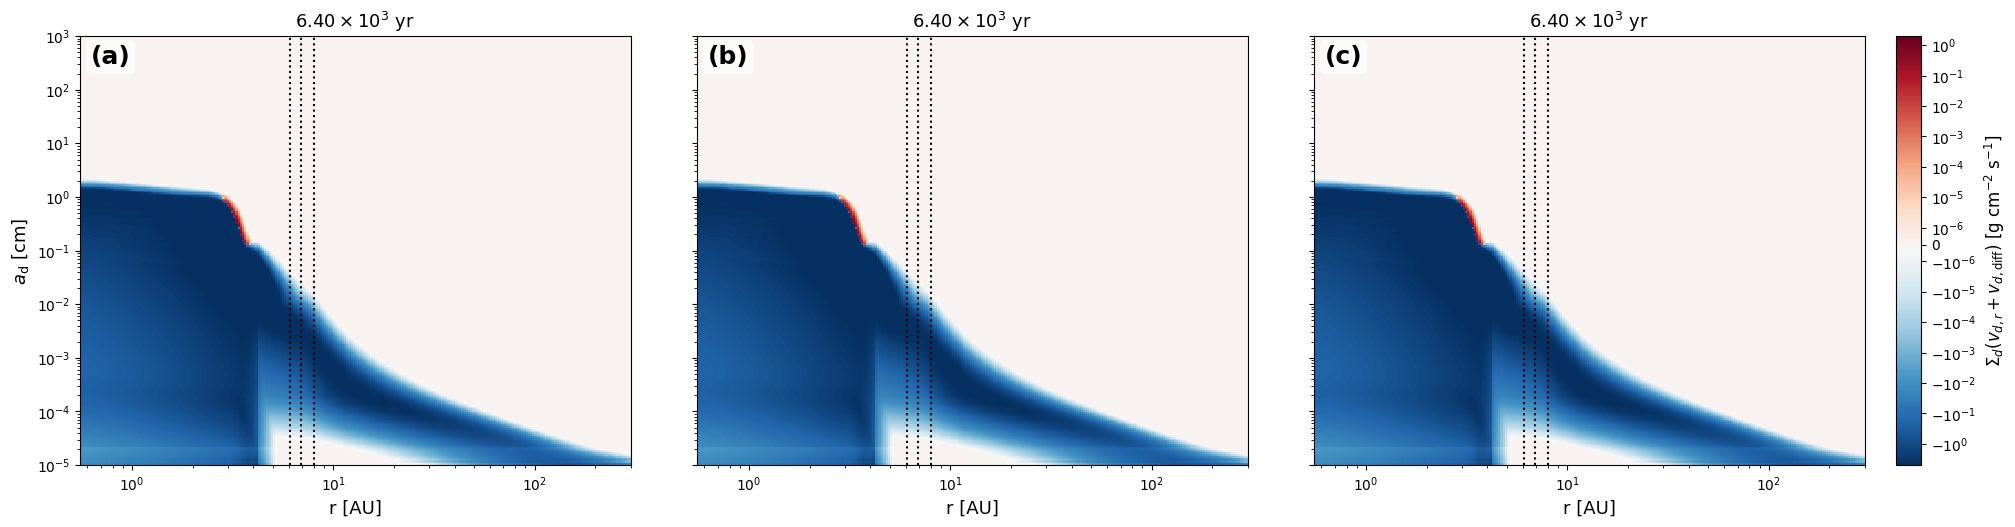

In [22]:
# ============================================================
# 3 時刻でのサイズごとのダストの動径質量フラックス (合計 Sigma_d (v_d,r + v_diff) のみ, 1x3: 1 パネル = 1 時刻)
# 上の 2 セル (1 時刻の v_d,r と フラックス) と同じ定義を各時刻で計算する:
#   St : Epstein (a < 9 lambda/4) / Stokes をコードと同じく切り替える
#   v_d,r = (v_g,r + 2 St dv_g,phi - St^2 v_wind) / (1 + St^2)  (なましなし)
#   v_diff = -D_d (df/dr)/f , D_d = alpha_MRI c_s H_g / (1 + St^2) , f = Sigma_d/Sigma_g (上のセルと同じ制限 (1+R)/(1+R+R^2))
#   フラックス = Sigma_d v (外向きが正)
# 違い: v_K はコードと同じく M_in (中心星 + 内側の円盤の質量) で計算する (上の 2 セルは M_sun. 円盤の質量の分 dv_g,phi がずれる)
# 黒の点線 : 圧力の極大 (d ln P/d ln r が + から - に変わる半径)
# file_gas 列: 0:r 1:Sigma_g 4:vg_r 5:vg_phi 6:vg_wind 12:T 13:P     file_mag 列: 1:alpha_MRI
# ============================================================

FLUX_YEARS = [30000, 50000, 100000]   # [yr] 描く時刻 (最も近い出力時刻を使う)
flux_vmax = 1.0e2                     # カラーバーの範囲 [g cm^-2 s^-1] (+-)
flux_linthresh = 1.0e-6               # SymLogNorm の線形部分

_G, _Msun, _kB, _mH, _mu = 6.67408e-08, 1.989e+33, 1.38064852e-16, 1.67353e-24, 2.34
_sigma_H2, _rho_s, _AU = 2.0e-15, 1.4, 1.495979e+13

def dust_flux_maps(year):
    gas = np.loadtxt(BASE_DIR + MODEL + "/out{}_gas".format(year))
    r, sigmag, vg_r, vg_phi, vg_wind, T, P = gas[:, 0], gas[:, 1], gas[:, 4], gas[:, 5], gas[:, 6], gas[:, 12], gas[:, 13]
    alpha_MRI = np.loadtxt(BASE_DIR + MODEL + "_B/out{}_B".format(year), usecols=(1,))
    dust_file = BASE_DIR + MODEL + "/out{}".format(year)
    with open(dust_file) as f:
        f.readline(); f.readline()
        a_bins = np.array(f.readline().split(), dtype=float)
    sigmad = np.loadtxt(dust_file, skiprows=5)[:, 1:]

    # M_in (dust_disk.cpp と同じ: log 格子のセル体積で Sigma_g を内側から積算)
    q = r[1] / r[0]
    dM = np.pi * sigmag * ((r * np.sqrt(q))**2 - (r / np.sqrt(q))**2)
    dM[0] = np.pi * sigmag[0] * (r[0] * np.sqrt(q))**2
    vK = np.sqrt(_G * (_Msun + np.cumsum(dM)) / r)
    Omega = vK / r
    cs = np.sqrt(_kB * T / (_mu * _mH))
    Hg = cs / Omega
    lam = 1.0 / (sigmag / (np.sqrt(2.0 * np.pi) * Hg) / (_mu * _mH) * _sigma_H2)

    A = a_bins[None, :]
    St = np.where(A < 2.25 * lam[:, None], 0.5 * np.pi * _rho_s * A / sigmag[:, None],
                  2.0 * np.pi / 9.0 * _rho_s * A**2 / (lam[:, None] * sigmag[:, None]))
    dvphi = (vg_phi - vK)[:, None]
    vd_r = (vg_r[:, None] + 2.0 * St * dvphi - St**2 * vg_wind[:, None]) / (1.0 + St**2)
    vd_r = vd_r

    Dd = (alpha_MRI * cs * Hg)[:, None] / (1.0 + St**2)
    fdg = sigmad / sigmag[:, None]
    dfdr = np.gradient(fdg, r, axis=0, edge_order=2)
    dfdr[[0, -1], :] = 0.0
    vd_diff = np.zeros_like(vd_r)
    act = fdg > 0.0
    vd_diff[act] = -Dd[act] * dfdr[act] / fdg[act]
    R = vd_diff / (np.sqrt(alpha_MRI) * cs)[:, None]
    R[~np.isfinite(R)] = 0.0
    vd_diff *= (1.0 + R) / (1.0 + R + R**2)

    dlnP = np.gradient(np.log(P), np.log(r))
    r_pmax = [r[i] / _AU for i in range(1, len(r) - 1) if dlnP[i - 1] > 0.0 and dlnP[i] <= 0.0]
    return r / _AU, a_bins, [sigmad * vd_r, sigmad * vd_diff, sigmad * (vd_r + vd_diff)], r_pmax

years_all = list_years(BASE_DIR + MODEL)
norm = SymLogNorm(linthresh=flux_linthresh, linscale=0.5, vmin=-5.0, vmax=2.0)

fig, axes = plt.subplots(1, len(FLUX_YEARS), figsize=(7 * len(FLUX_YEARS), 5.5), sharex=True, sharey=True, squeeze=False)
axes = axes[0]
for ax, ts in zip(axes, FLUX_YEARS):
    year = min(years_all, key=lambda y: abs(y - ts))
    r_AU, a_bins, fields, r_pmax = dust_flux_maps(year)
    im = ax.pcolormesh(r_AU, a_bins, fields[2].T, norm=norm, cmap="RdBu_r", shading="auto", rasterized=True)
    for rp in r_pmax:
        ax.axvline(rp, color="black", lw=1.5, ls=":")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(r_min, r_max)
    ax.set_ylim(1.0e-5,1.0e3)
    ax.set_xlabel("r [AU]", fontsize=13)
    ax.set_title(snap_label(year), fontsize=13)
axes[0].set_ylabel(r"$a_{\rm d}$ [cm]", fontsize=13)
fig.subplots_adjust(left=0.05, right=0.90, bottom=0.12, top=0.90, wspace=0.12)
cbar = fig.colorbar(im, cax=fig.add_axes([0.915, 0.12, 0.012, 0.78]), orientation="vertical")
cbar.set_label(r'$\Sigma_d \left(v_{d,r}+v_{d,\mathrm{diff}}\right)$ [g cm$^{-2}$ s$^{-1}$]', fontsize=12)
plt.savefig(fig_path('dustflux_3times.png', root=ANALYSIS_FIG_DIR), dpi=150, bbox_inches='tight')
plt.show()


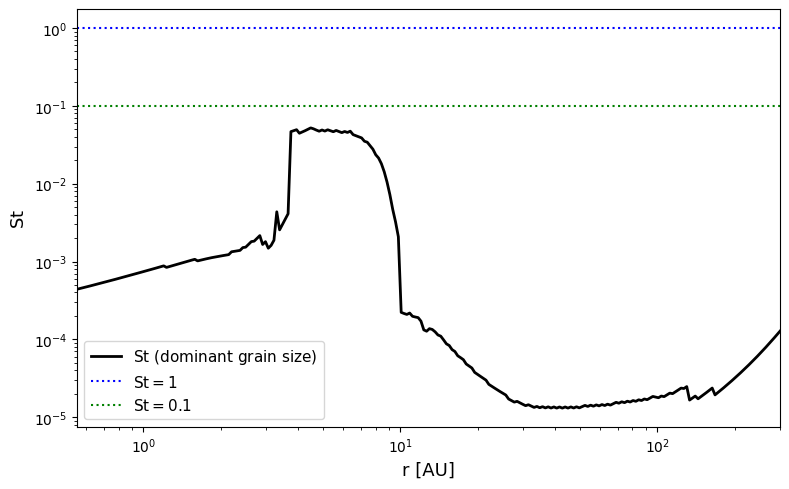

In [11]:
# [旧 cell 24]
# ============================================================
# Stokes number of the dominant (most massive) grain size vs r,
# with St=1 and St=0.1 reference lines -- shows how far the
# dust actually present in the gap/bump region is from the
# trapping-efficient regime (St ~ 0.1-1).
# Reuses r, r_AU, a_bins, sigmad, St, time_label from the flux
# cell above -- run that cell first.
# ============================================================
St_dominant = np.full(len(r), np.nan)
a_dominant  = np.full(len(r), np.nan)
for i in range(len(r)):
    j = np.argmax(sigmad[i, :])
    St_dominant[i] = St[i, j]
    a_dominant[i]  = a_bins[j]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(r_AU, St_dominant, color='black', lw=2, label=r'$\mathrm{St}$ (dominant grain size)')
ax.axhline(1.0, color='blue',  lw=1.5, linestyle=':', label=r'$\mathrm{St}=1$')
ax.axhline(0.1, color='green', lw=1.5, linestyle=':', label=r'$\mathrm{St}=0.1$')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(r_min, r_max)
ax.set_xlabel('r [AU]', fontsize=13)
ax.set_ylabel(r'$\mathrm{St}$', fontsize=13)
# ax.set_title('Stokes number of dominant grain size  (t = out' + time_label + ')', fontsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(fig_path('St_dominant_' + time_label + '.png', root=ANALYSIS_FIG_DIR), dpi=150, bbox_inches='tight')
plt.show()

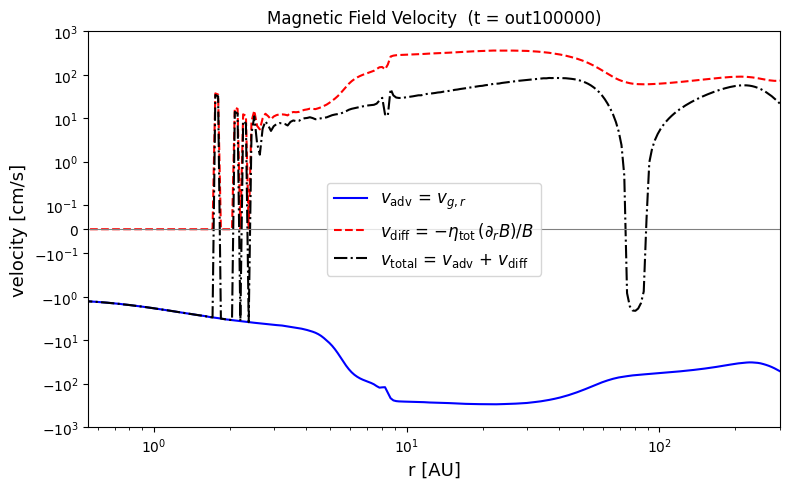

In [13]:
# [旧 cell 26]
# # ============================================================
# # ?3: ??????? (advection) ????? (diffusion) ???????
# #   ???? v_adv = vg_r  (????????)
# #   ???? v_diff = -eta_total * (dB/dr) / B
# #   ???? v_total = v_adv + v_diff
# # B file columns:
# #   col0: r[cm], col1: alpha_MRI, col2: B[G], col3: etaO[cm^2/s], col4: etaA[cm^2/s]
# # ============================================================

# AU = 1.495979e+13  # cm

outdir   = BASE_DIR + MODEL
outdir_B = BASE_DIR + MODEL + "_B"
# outdir_B = '/mnt/hdd/shimokawa/beta3_new_B'

time_label = str(SNAP_YEAR)
B_file   = outdir_B + '/out' + time_label + '_B'
gas_file = outdir   + '/out' + time_label + '_gas'

# ----- Load magnetic field data -----
data_B    = np.loadtxt(B_file)
r         = data_B[:, 0]      # [cm]
B         = data_B[:, 2]      # magnetic field strength [G]
etaO      = data_B[:, 3]      # Ohmic diffusivity [cm^2/s]
etaA      = data_B[:, 4]      # Ambipolar diffusivity [cm^2/s]
eta_total = etaO + etaA       # total magnetic diffusivity [cm^2/s]

# ----- Load gas data for advection velocity -----
data_gas = np.loadtxt(gas_file)
vg_r     = data_gas[:, 4]  # gas radial velocity [cm/s]

# ----- Magnetic diffusion velocity: v_diff = -eta * dB/dr / B -----
dBdr    = np.gradient(B, r)                   # numerical dB/dr [G/cm]
v_diff  = -eta_total * dBdr / np.abs(B)       # [cm/s]
v_diff  = v_diff

# ----- Total magnetic field velocity -----
v_total = vg_r + v_diff

r_AU = r / AU

# ----- Plot (symlog y-axis: ??????????????) -----
linthresh = 1.0e-1

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(r_AU, vg_r,    color='blue',  linewidth=1.5, label=r'$v_{\rm adv}$ = $v_{g,r}$')
ax.plot(r_AU, v_diff,  color='red',   linewidth=1.5, linestyle='--',
        label=r'$v_{\rm diff}$ = $-\eta_{\rm tot}\,(\partial_r B)/B$')
ax.plot(r_AU, v_total, color='black', linewidth=1.5, linestyle='-.',
        label=r'$v_{\rm total}$ = $v_{\rm adv}$ + $v_{\rm diff}$')
ax.axhline(0, color='gray', linewidth=0.8, linestyle='-')

ax.set_xscale('log')
ax.set_yscale('symlog', linthresh=linthresh, linscale=0.5)
ax.set_xlim(r_min,r_max)
ax.set_ylim(-1.0e3, 1.0e3)
ax.set_xlabel('r [AU]', fontsize=13)
ax.set_ylabel('velocity [cm/s]', fontsize=13)
ax.set_title('Magnetic Field Velocity  (t = out' + time_label + ')', fontsize=12)
ax.legend(fontsize=12)
plt.tight_layout()
# plt.savefig(fig_path('fig2_mag3e4_velocity.png', root=ANALYSIS_FIG_DIR), dpi=150, bbox_inches='tight')
plt.show()

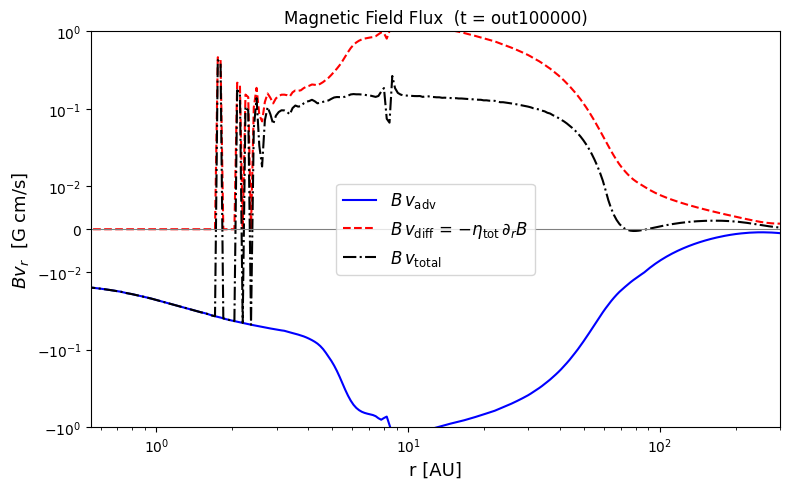

In [14]:
# [旧 cell 27]
# ============================================================
# Magnetic flux (flux units, no division by B -- matches
# magnetic_field1D.cpp: B_adv=-vgr*B, B_diff=eta*dB/dr directly).
# Reuses B, vg_r, eta_total, dBdr, v_diff, v_total, r_AU, r_min, r_max,
# time_label from the velocity cell above -- run that cell first.
# ============================================================
flux_adv   = vg_r * B
flux_diff  = v_diff * B
flux_total = v_total * B

finite = np.abs(flux_total[np.isfinite(flux_total)])
vmax = np.nanpercentile(finite, 98) if finite.size else 1.0
linthresh_flux = max(vmax * 1.0e-3, 1.0e-12)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(r_AU, flux_adv,   color='blue',  linewidth=1.5, label=r'$B\,v_{\rm adv}$')
ax.plot(r_AU, flux_diff,  color='red',   linewidth=1.5, linestyle='--',
        label=r'$B\,v_{\rm diff}$ = $-\eta_{\rm tot}\,\partial_r B$')
ax.plot(r_AU, flux_total, color='black', linewidth=1.5, linestyle='-.',
        label=r'$B\,v_{\rm total}$')
ax.axhline(0, color='gray', linewidth=0.8, linestyle='-')

ax.set_xscale('log')
ax.set_yscale('symlog', linthresh=1.0e-2, linscale=0.5)
ax.set_xlim(r_min,r_max)
ax.set_xlabel('r [AU]', fontsize=13)
ax.set_ylabel(r'$B v_r$  [G cm/s]', fontsize=13)
ax.set_ylim(-1.0e0, 1.0e0)
ax.set_yticks([-1.0e0, -1.0e-1, -1.0e-2, 0.0, 1.0e-2, 1.0e-1, 1.0e0])
ax.set_title('Magnetic Field Flux  (t = out' + time_label + ')', fontsize=12)
ax.legend(fontsize=12)
plt.tight_layout()
# plt.savefig(fig_path('fig2_mag3e4_flux.png', root=ANALYSIS_FIG_DIR), dpi=150, bbox_inches='tight')
plt.show()

## ガス面密度の変化率とタイムスケール

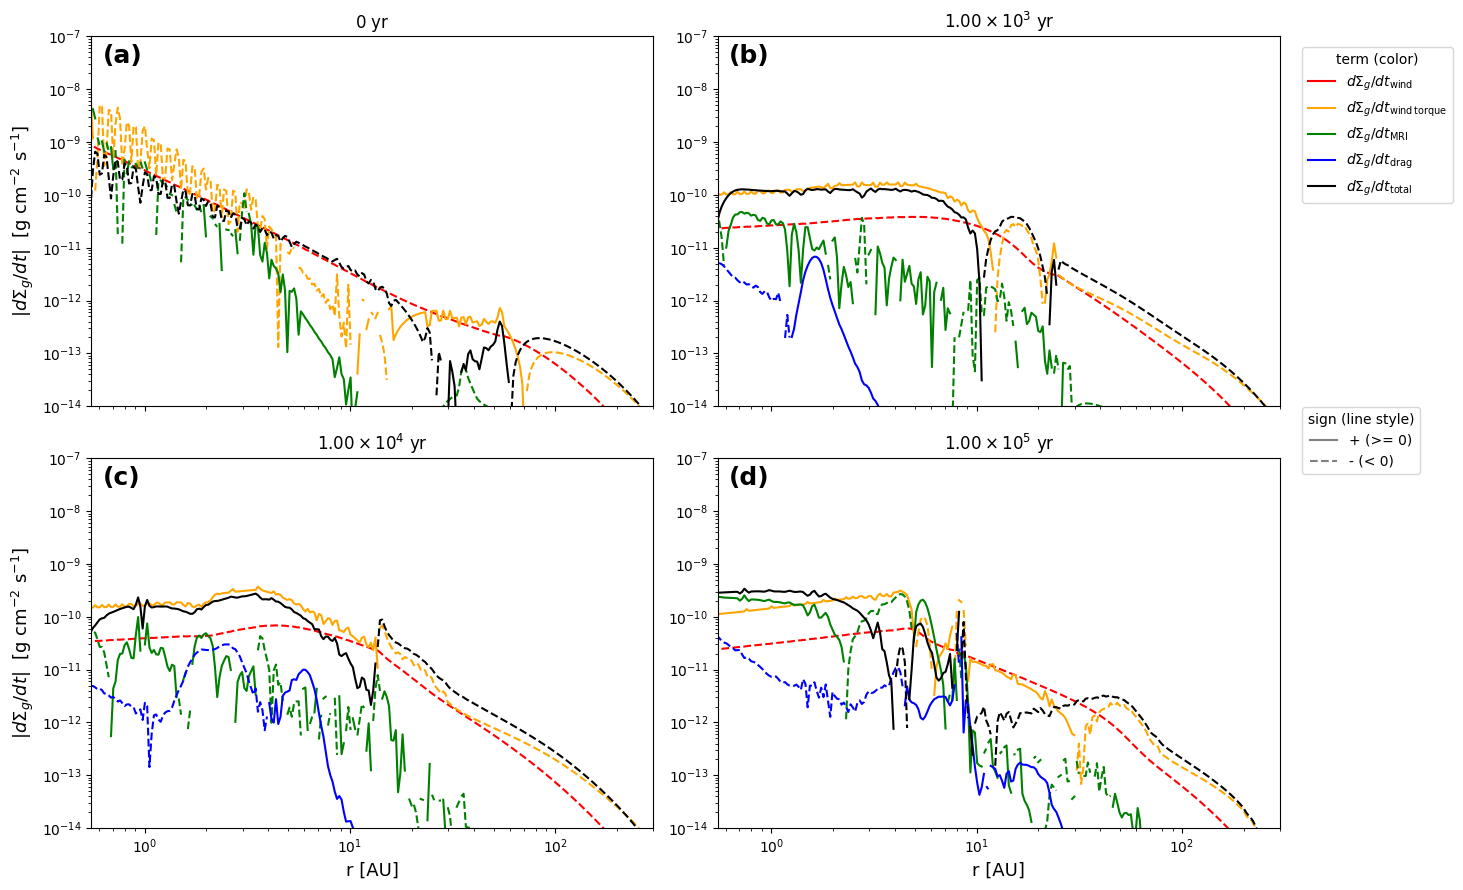

In [15]:
# [旧 cell 28]
# ============================================================
# dSigma_g/dt decomposition: wind mass-loss / wind-torque / MRI(+GI) viscous
# torque / total, plotted vs r for 4 chosen times (beta3).
#
# Continuity equation actually solved in the code
# (dust_disk.cpp SetDiskGasModel, e.g. line ~2578/3014/3338):
#   sigmag[i] -= 2*dt*(r_bod[i+1]*fluxg[i+1]-r_bod[i]*fluxg[i])*vol_inv + dsigmagdt_w[i]*dt
# => dSigma_g/dt_total = -(1/r) d/dr(r*Sigma_g*vg_r) - dsigmagdt_w
#    (vg_r = saved gas-file col4, already wind-subtracted; dsigmagdt_w = col11)
#
# The torque velocity feeding vg_r (dust_disk.cpp:1416,1601-1603) is built from
# dNdr_torque = viscous(alpha_MRI+alpha_GI) part + wind-torque(-0.75*alpha_DW*cs^2)
# part. Splitting that sum recovers the individual MRI and wind-torque velocities
# -- same reconstruction as cell 63 (v_visc_only / v_windtorque_only), including
# the dust-drag back-reaction (lambda1, lambda2, A_coef) from the saved dust size
# distribution. Validated there (and rechecked here) to within a few % of the
# independently-computed total for r >~ 5-6 au; noticeably worse closer in
# (unresolved boundary behaviour near the hot inner disk), same caveat as cell 63.
#
#   dSigma_g/dt_MRI        = -(1/r) d/dr(r*Sigma_g*v_visc_only)
#   dSigma_g/dt_windtorque = -(1/r) d/dr(r*Sigma_g*v_windtorque_only)
#   dSigma_g/dt_drag       = -(1/r) d/dr(r*Sigma_g*v_drag_only)        (dust-drag back-reaction on the gas
#                                                                       (reaction to the pressure-gradient-driven
#                                                                       dust drift; =0 without dust), v_drag
#                                                                       from reconstruct_gas_velocity/cell 61)
#   dSigma_g/dt_wind       = -dsigmagdt_w                              (direct, col 11)
#   dSigma_g/dt_total      = -(1/r) d/dr(r*Sigma_g*vg_r) - dsigmagdt_w  (independent of the split)
#   => dsdt_MRI + dsdt_windtorque + dsdt_drag + dsdt_wind ~= dsdt_total (now includes all four terms)
#
# gas file columns actually written (dust_disk.cpp:3207, 25 cols):
#   0 r_cen  1 sigmag  4 vg_r  6 vg_wind  11 dsigmagdt_w  12 T  15 dNdr_torque
#   17 alpha_phiz  18 alpha_tot
# ============================================================

AU       = 1.495979e+13   # cm
G_cgs    = 6.67408e-08    # cgs
Msolar   = 1.989e+33      # g
kB       = 1.38064852e-16 # erg/K
mH       = 1.67353e-24    # g
mu       = 2.34
sigma_H2 = 2.0e-15        # cm^2
rho_dust = 1.4            # g/cm^3

outdir      = BASE_DIR + MODEL
# outdir_B   = '../beta2_data_3e5yr' 

time_labels = [str(y) for y in SNAP_YEARS]

                     # derivative INPUTS (N_torque, velocities), not the
                     # noisy dSigma_g/dt outputs themselves -- this tames the
                     # grid-scale noise that the two nested radial derivatives
                     # (torque -> velocity -> flux divergence) would otherwise
                     # amplify, without imposing any particular curve shape.

def deriv3(f, rr):
    """Non-uniform 3-point derivative (same scheme used elsewhere in this notebook)."""
    d = np.zeros_like(f)
    s = rr[1:-1] - rr[:-2]
    t = rr[2:] - rr[1:-1]
    d[1:-1] = (s**2*f[2:] + (t**2 - s**2)*f[1:-1] - t**2*f[:-2]) / (s*t*(s+t))
    d[0] = d[1]
    d[-1] = d[-2]
    return d


def flux_div(r, sigmag, v):
    """-(1/r) d/dr(r*sigmag*v) -- radial continuity-equation flux divergence."""
    return -deriv3(r*sigmag*v, r) / r

def compute_dsigmagdt_terms(outdir, time_label):
    gas_file  = f'{outdir}/out{time_label}_gas'
    dust_file = f'{outdir}/out{time_label}'

    data        = np.loadtxt(gas_file)
    r_cm        = data[:, 0]
    sigmag      = data[:, 1]
    vg_r        = data[:, 4]
    dsigmagdt_w = data[:, 11]

    # コードと同じ式の再構成 (cell 61 の reconstruct_gas_velocity; 先に cell 61 を実行しておくこと)
    comp = reconstruct_gas_velocity(outdir, time_label)
    v_visc_only       = comp['v_visc']
    v_windtorque_only = comp['v_windtorque']
    v_drag_only       = comp['v_drag']
    vg_r_s            = vg_r
    dsigmagdt_w_s     = dsigmagdt_w

    dsdt_MRI        = flux_div(r_cm, sigmag, v_visc_only)
    dsdt_windtorque = flux_div(r_cm, sigmag, v_windtorque_only)
    dsdt_drag       = flux_div(r_cm, sigmag, v_drag_only)
    dsdt_wind       = -dsigmagdt_w_s
    dsdt_total      = flux_div(r_cm, sigmag, vg_r_s) - dsigmagdt_w_s

    return r_cm/AU, dsdt_wind, dsdt_windtorque, dsdt_drag, dsdt_MRI, dsdt_total

# 色 = 物理量(項)、線種 = 符号(正/負) -- 項どうしは色だけで区別し、線種はどの項でも
# 「正なら実線、負なら破線」に固定する。1本の曲線が r に沿って符号反転する箇所が
# あるので、正の区間・負の区間をそれぞれ別配列(他方はNaN)にして2回plotする。
term_colors = [
    (r'$d\Sigma_g/dt_{\rm wind}$',        'dsdt_wind',       'red'),
    (r'$d\Sigma_g/dt_{\rm wind\,torque}$','dsdt_windtorque', 'orange'),
    (r'$d\Sigma_g/dt_{\rm MRI}$',         'dsdt_MRI',        'green'),
    (r'$d\Sigma_g/dt_{\rm drag}$',        'dsdt_drag',       'blue'),
    (r'$d\Sigma_g/dt_{\rm total}$',       'dsdt_total',      'black'),
]
SIGN_STYLE = {'+': '-', '-': '--'}  # 正=実線, 負=破線 (どの項でも共通)

def plot_signed(ax, r_AU, v, color, linewidth=1.5):
    # 負の区間は絶対値にして描く(線種で符号を示すので、大きさは常に正の値で比較できる)
    pos = np.where(v >= 0, v, np.nan)
    neg = np.where(v < 0, -v, np.nan)
    ax.plot(r_AU, pos, color=color, linewidth=linewidth, linestyle=SIGN_STYLE['+'])
    ax.plot(r_AU, neg, color=color, linewidth=linewidth, linestyle=SIGN_STYLE['-'])

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)

for ax, tl in zip(axes.flat, time_labels):
    terms = dict(zip(
        ('dsdt_wind', 'dsdt_windtorque', 'dsdt_drag', 'dsdt_MRI', 'dsdt_total'),
        compute_dsigmagdt_terms(outdir, tl)[1:]))
    r_AU = compute_dsigmagdt_terms(outdir, tl)[0]

    for _, key, color in term_colors:
        plot_signed(ax, r_AU, terms[key], color)
    ax.axhline(0, color='gray', linewidth=0.8)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(r_min, r_max)
    ax.set_ylim(1.0e-14, 1.0e-7)
    ax.set_title(f'{snap_label(int(tl))}', fontsize=12)

for ax in axes[-1, :]:
    ax.set_xlabel('r [AU]', fontsize=13)
for ax in axes[:, 0]:
    ax.set_ylabel(r'$|d\Sigma_g/dt|$  [g cm$^{-2}$ s$^{-1}$]', fontsize=13)

# 凡例を2つに分ける: 色 -> 物理量, 線種 -> 符号
color_handles = [Line2D([0], [0], color=c, linewidth=1.5, label=lbl) for lbl, _, c in term_colors]
sign_handles = [Line2D([0], [0], color='gray', linewidth=1.5, linestyle=ls, label=f'{sign} (>= 0)' if sign == '+' else f'{sign} (< 0)')
                for sign, ls in SIGN_STYLE.items()]
fig.legend(handles=color_handles, loc='upper left', bbox_to_anchor=(1.0, 0.95), fontsize=10, title='term (color)')
fig.legend(handles=sign_handles, loc='upper left', bbox_to_anchor=(1.0, 0.55), fontsize=10, title='sign (line style)')

# fig.suptitle('Gas Surface Density Evolution Terms', fontsize=14)
plt.tight_layout()
plt.savefig(fig_path("dsdt.png", root=ANALYSIS_FIG_DIR))
# plt.savefig(fig_path('beta3_dsigmagdt.png', root=ANALYSIS_FIG_DIR), dpi=150, bbox_inches='tight')
plt.show()

/tmp/ipykernel_870850/571623999.py:25: RuntimeWarning: invalid value encountered in divide
  R = -dsdt_wind / resupply
/tmp/ipykernel_870850/571623999.py:25: RuntimeWarning: divide by zero encountered in divide
  R = -dsdt_wind / resupply


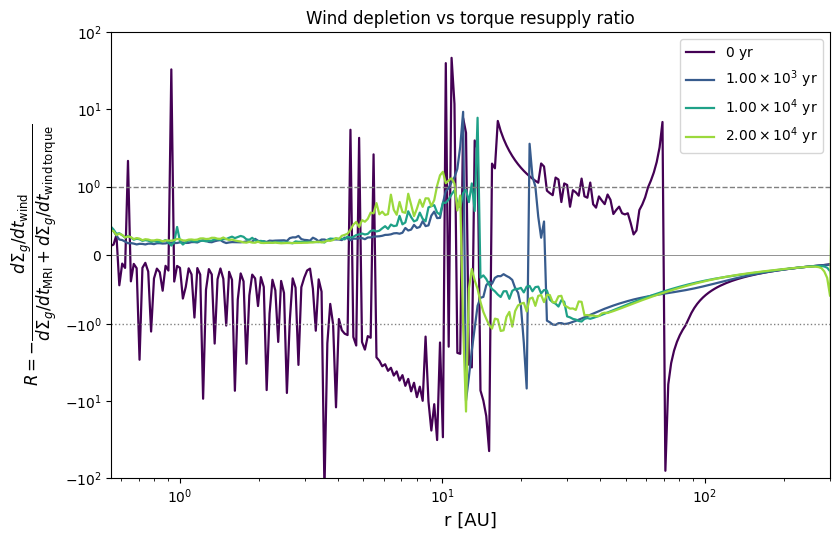

In [15]:
# [旧 cell 29]
# ============================================================
# Wind depletion vs torque resupply ratio:
#   R(r) = -(dSigma_g/dt_wind) / (dSigma_g/dt_MRI + dSigma_g/dt_windtorque + dSigma_g/dt_drag)
# Dimensionless: rate of gas removal by the vertical wind divided by the rate
# at which the radial torque-driven flow (viscous MRI+GI plus wind-torque)
# resupplies/depletes that same annulus.
#   R > 1  -> wind removes gas faster than the torque flow can resupply it
#             locally -> favors local depletion / gap opening.
#   R < 1  -> torque-driven resupply keeps up.
#   R < 0  -> the "resupply" term is itself net-depleting there too (both
#             terms draining that annulus); sign flips near denominator
#             zero-crossings produce the large spikes visible in the plot --
#             those are real features of the ratio, not numerical bugs.
# Reuses compute_dsigmagdt_terms() from the previous cell (same Gaussian-
# filtered derivative pipeline).
# ============================================================

fig, ax = plt.subplots(figsize=(8.5, 5.5))
colors = cm.viridis(np.linspace(0, 0.85, len(time_labels)))

for tl, color in zip(time_labels, colors):
    r_AU, dsdt_wind, dsdt_windtorque, dsdt_drag, dsdt_MRI, dsdt_total = compute_dsigmagdt_terms(outdir, tl)
    resupply = dsdt_MRI + dsdt_windtorque + dsdt_drag
    R = -dsdt_wind / resupply
    ax.plot(r_AU, R, color=color, linewidth=1.6, label=snap_label(int(tl)))

ax.axhline(1.0,  color='gray', linewidth=1.0, linestyle='--')
ax.axhline(-1.0, color='gray', linewidth=1.0, linestyle=':')
ax.axhline(0.0,  color='gray', linewidth=0.6)

ax.set_xscale('log')
ax.set_yscale('symlog', linthresh=1.0, linscale=0.8)
ax.set_xlim(r_min, r_max)
ax.set_ylim(-1.0e2, 1.0e2)
ax.set_xlabel('r [AU]', fontsize=13)
ax.set_ylabel(r'$R = -\dfrac{d\Sigma_g/dt_{\rm wind}}{d\Sigma_g/dt_{\rm MRI}+d\Sigma_g/dt_{\rm wind\,torque}}$', fontsize=12)
ax.set_title('Wind depletion vs torque resupply ratio', fontsize=12)
ax.legend(fontsize=10, loc='best')
plt.tight_layout()
# plt.savefig('./fig/beta3_wind_vs_resupply_ratio.png', dpi=150, bbox_inches='tight')
plt.show()

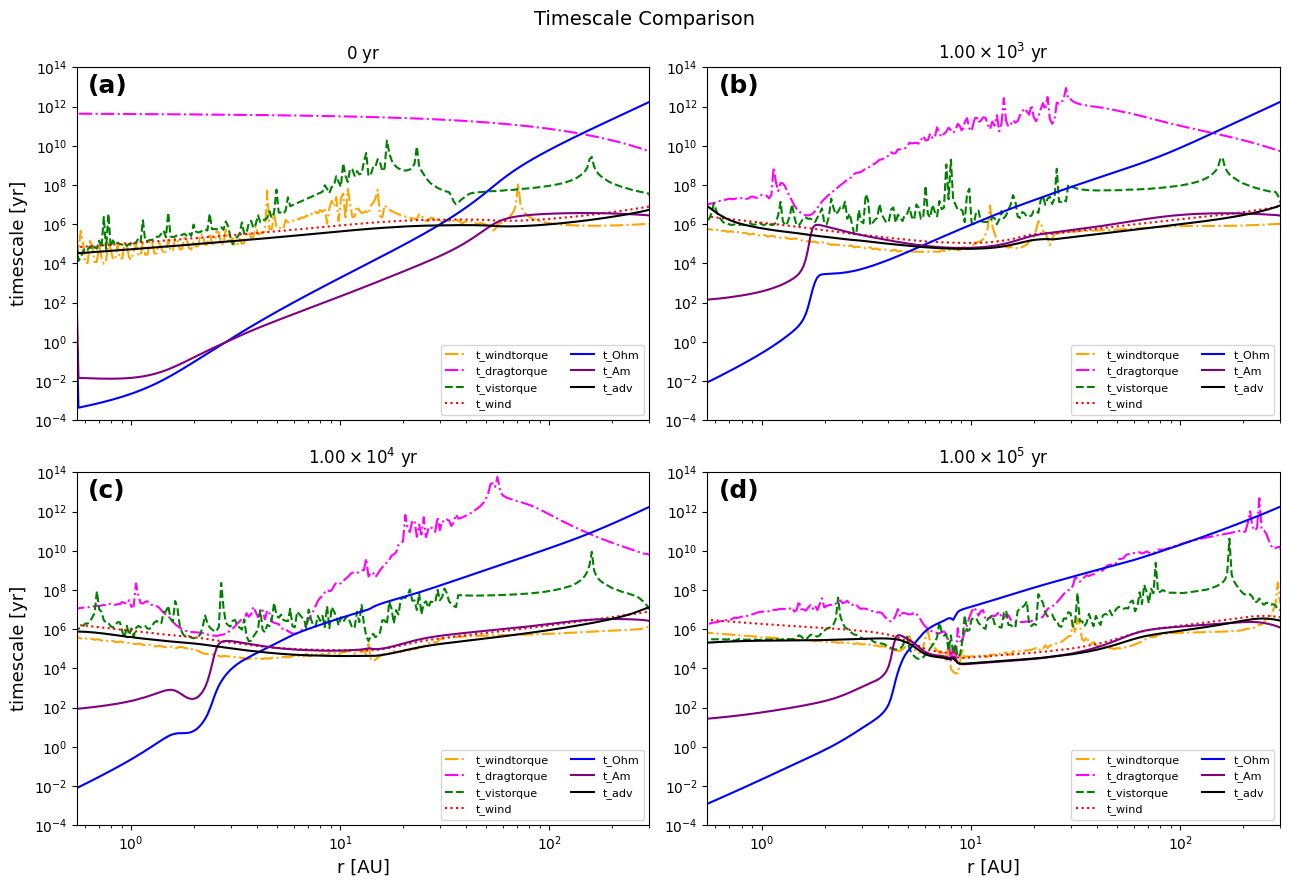

In [16]:
# [旧 cell 30]
# ============================================================
# Timescale comparison: t_windtorque, t_vistorque, t_wind, t_Ohm, t_Am, t_adv
# vs r, one 2x2 mini-map panel per time (beta3).
#
# Definitions (all converted to years):
#   t_wind        = Sigma_g / |dSigma_g/dt_wind|        (wind depletion time)
#   t_windtorque  = Sigma_g / |dSigma_g/dt_windtorque|  (wind-torque transport time)
#   t_dragtorque  = Sigma_g / |dSigma_g/dt_drag|        (dust-drag back-reaction transport time)
#   t_vistorque   = Sigma_g / |dSigma_g/dt_MRI|         (viscous MRI+GI torque transport time)
#   t_adv         = r / |vg_r|                          (total gas radial advection time,
#                                                          the natural baseline for t_Ohm/t_Am)
#   t_Ohm         = r^2 / etaO                          (Ohmic diffusion time)
#   t_Am          = r^2 / etaA                          (ambipolar diffusion time)
# dSigma_g/dt_* reuse compute_dsigmagdt_terms() (Gaussian-filtered pipeline) from
# the earlier cell. etaO, etaA come from the B file (cell 70's convention):
#   col0: r[cm], col1: alpha_MRI, col2: B, col3: etaO, col4: etaA, col5: beta
# Sign changes in the underlying rates make some of these timescales blow up
# (division by ~0) at isolated radii -- those points are masked out (NaN)
# rather than plotted as spikes.
# ============================================================

yr = 3.155760e+07  # s

def compute_timescales(outdir, time_label):
    gas_file = f'{outdir}/out{time_label}_gas'
    B_file   = f'{outdir}_B/out{time_label}_B'

    data   = np.loadtxt(gas_file)
    r_cm   = data[:, 0]
    sigmag = data[:, 1]
    vg_r   = data[:, 4]   # 速度 (なましなし)

    data_B = np.loadtxt(B_file)
    etaO   = data_B[:, 3]
    etaA   = data_B[:, 4]

    _, dsdt_wind, dsdt_windtorque, dsdt_drag, dsdt_MRI, _ = compute_dsigmagdt_terms(outdir, time_label)

    with np.errstate(divide='ignore', invalid='ignore'):
        t_wind        = sigmag / np.abs(dsdt_wind)        / yr
        t_windtorque  = sigmag / np.abs(dsdt_windtorque)  / yr
        t_dragtorque  = sigmag / np.abs(dsdt_drag)        / yr
        t_vistorque   = sigmag / np.abs(dsdt_MRI)         / yr
        t_adv         = r_cm   / np.abs(vg_r)             / yr
        t_Ohm         = r_cm**2 / etaO                    / yr
        t_Am          = r_cm**2 / etaA                    / yr

    for arr in (t_wind, t_windtorque, t_dragtorque, t_vistorque, t_adv, t_Ohm, t_Am):
        arr[~np.isfinite(arr)] = np.nan

    return r_cm/AU, t_windtorque, t_dragtorque, t_vistorque, t_wind, t_Ohm, t_Am, t_adv

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)

series_style = [
    ('t_windtorque',  'orange',  '-.'),
    ('t_dragtorque',  'magenta', '-.'),
    ('t_vistorque',   'green',   '--'),
    ('t_wind',        'red',     ':'),
    ('t_Ohm',         'blue',    '-'),
    ('t_Am',          'purple',  '-'),
    ('t_adv',         'black',   '-'),
]

for ax, tl in zip(axes.flat, time_labels):
    r_AU, t_windtorque, t_dragtorque, t_vistorque, t_wind, t_Ohm, t_Am, t_adv = compute_timescales(outdir, tl)
    values = dict(t_windtorque=t_windtorque, t_dragtorque=t_dragtorque, t_vistorque=t_vistorque,
                  t_wind=t_wind, t_Ohm=t_Ohm, t_Am=t_Am, t_adv=t_adv)
    for name, color, ls in series_style:
        ax.plot(r_AU, values[name], color=color, linewidth=1.5, linestyle=ls, label=name)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(r_min, r_max)
    ax.set_ylim(1.0e-4, 1.0e14)
    ax.set_title(f'{snap_label(int(tl))}', fontsize=12)
    ax.legend(fontsize=8, loc='best', ncol=2)

for ax in axes[-1, :]:
    ax.set_xlabel('r [AU]', fontsize=13)
for ax in axes[:, 0]:
    ax.set_ylabel('timescale [yr]', fontsize=13)

fig.suptitle('Timescale Comparison', fontsize=14)
plt.tight_layout()
plt.savefig(fig_path("timescale.png", root=ANALYSIS_FIG_DIR))
# plt.savefig(fig_path('beta3_timescale.png', root=ANALYSIS_FIG_DIR), dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# [旧 cell 31]
# ============================================================
# R = Sigma_g / (dSigma_g/dt_total)  [yr]
# Characteristic timescale of the TOTAL gas surface density evolution
# (sign included: R>0 where Sigma_g is currently growing, R<0 where it is
# depleting). Diverges near radii where dSigma_g/dt_total crosses zero --
# masked to NaN rather than plotted as a spike.
# Reuses compute_dsigmagdt_terms() (Gaussian-filtered pipeline).
# ============================================================

yr = 3.155760e+07  # s

# log スケールなので絶対値で描き、符号は線種で示す(色=時刻は維持):
# 正(Sigma_g が今増えている) = 実線, 負(減っている) = 破線 -- house style
# (thesis.ipynb cell 70 / compare_beta_ini.ipynb と同じ)。
def plot_signed_by_time(ax, r_AU, v, color, linewidth=1.6, label=None):
    pos = np.where(v >= 0, v, np.nan)
    neg = np.where(v < 0, -v, np.nan)
    ax.plot(r_AU, pos, color=color, linewidth=linewidth, linestyle='-',  label=label)
    ax.plot(r_AU, neg, color=color, linewidth=linewidth, linestyle='--')

fig, ax = plt.subplots(figsize=(8.5, 5.5))
colors = cm.viridis(np.linspace(0, 0.85, len(time_labels)))

for tl, color in zip(time_labels, colors):
    data   = np.loadtxt(f'{outdir}/out{tl}_gas')
    sigmag = data[:, 1]
    r_AU, dsdt_wind, dsdt_windtorque, dsdt_drag, dsdt_MRI, dsdt_total = compute_dsigmagdt_terms(outdir, tl)
    with np.errstate(divide='ignore', invalid='ignore'):
        R = sigmag / dsdt_total / yr
    R[~np.isfinite(R)] = np.nan
    plot_signed_by_time(ax, r_AU, R, color, label=snap_label(int(tl)))

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(r_min, r_max)
ax.set_ylim(1.0e4,1.0e8)
ax.set_xlabel('r [AU]', fontsize=13)
ax.set_ylabel(r'$|R|$,  $R = \Sigma_g / (d\Sigma_g/dt_{\rm total})$  [yr]', fontsize=12)
ax.set_title('Total gas evolution timescale (solid: growing, dashed: depleting)', fontsize=12)
ax.legend(fontsize=10, loc='upper right', ncol=1)
plt.tight_layout()
# plt.savefig(fig_path('beta3_R_total_timescale5e5yr.png', root=ANALYSIS_FIG_DIR), dpi=150, bbox_inches='tight')
plt.show()

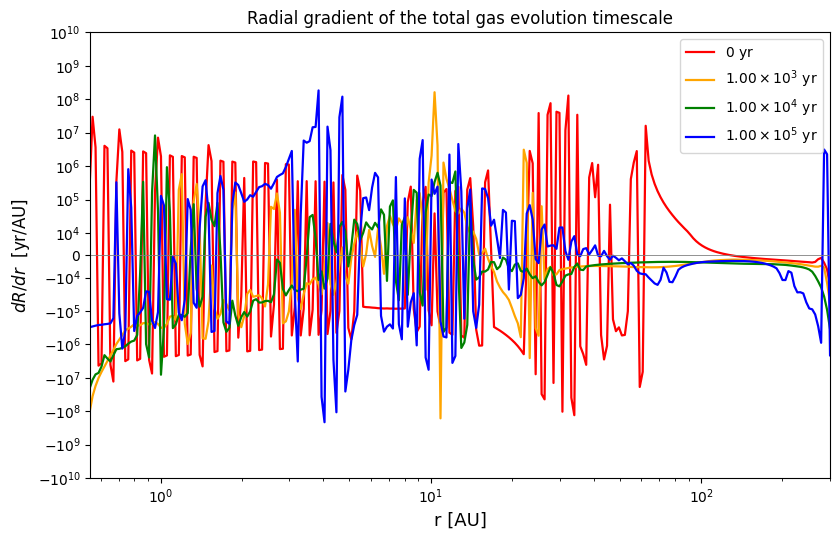

In [17]:
# [旧 cell 32]
# ============================================================
# dR/dr, where R = Sigma_g / (dSigma_g/dt_total)  [yr]  (previous cell).
# Radial gradient of the total-evolution timescale, same non-uniform-grid
# derivative (deriv3) used throughout this notebook. Units: yr/AU.
# ============================================================
fig, ax = plt.subplots(figsize=(8.5, 5.5))

for tl, color in zip(time_labels, colors):
    data   = np.loadtxt(f'{outdir}/out{tl}_gas')
    sigmag = data[:, 1]
    r_AU, dsdt_wind, dsdt_windtorque, dsdt_drag, dsdt_MRI, dsdt_total = compute_dsigmagdt_terms(outdir, tl)
    with np.errstate(divide='ignore', invalid='ignore'):
        R = sigmag / dsdt_total / yr
    R[~np.isfinite(R)] = np.nan
    dRdr = deriv3(R, r_AU)
    ax.plot(r_AU, dRdr, color=color, linewidth=1.6, label=snap_label(int(tl)))

ax.axhline(0.0, color='gray', linewidth=0.6)
ax.set_xscale('log')
ax.set_yscale('symlog', linthresh=1.0e4, linscale=0.6)
ax.set_xlim(r_min, r_max)
ax.set_ylim(-1.0e10, 1.0e10)
ax.set_xlabel('r [AU]', fontsize=13)
ax.set_ylabel(r'$dR/dr$  [yr/AU]', fontsize=12)
ax.set_title('Radial gradient of the total gas evolution timescale', fontsize=12)
ax.legend(fontsize=10, loc='best')
plt.tight_layout()
# plt.savefig('./fig/beta3_dRdr_total_timescale.png', dpi=150, bbox_inches='tight')
plt.show()

## 磁束・プラズマベータ

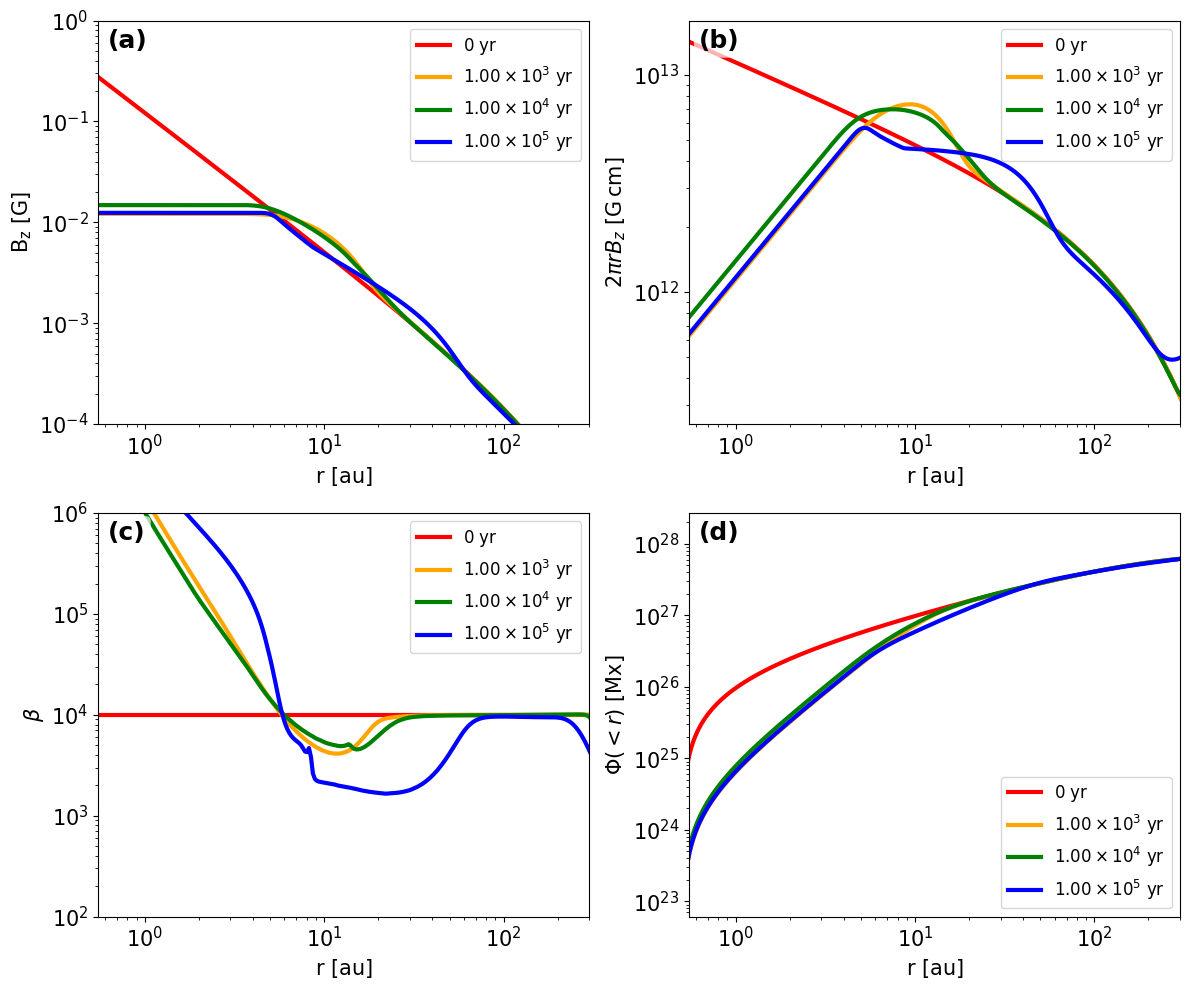

In [18]:
# [旧 cell 67]
# ======================================================
# 4 時刻でのスナップショット (2x2 ミニマップ)
#   (左上) 鉛直磁場 B_z            (右上) 円環での磁束 2 pi r B_z (= dPhi/dr)
#   (左下) 中心面プラズマ beta     (右下) 累積磁束 Phi(<r) = int_{r_in}^{r} 2 pi r' B_z dr'
# Phi(<r) はコードの有限体積と同じく Phi(<r_bod[i+1]) = sum_k pi (r_bod[k+1]^2 - r_bod[k]^2) B_k (r_in = r_bod[0] より内側は含まない)
# 上のセルの years, path_gas, path_mag, FIG_DIR, r_min, r_max を使う (先に上のセルを実行する)
# t_snap に最も近い出力時刻を使い, 凡例にはその出力時刻を表示する
# t = 0 の beta は出力値ではなく初期条件の beta_ini で固定して描く
# file_gas 列: 0:r_cen     file_mag 列: 2:B_z 5:beta_disk
# ======================================================
outdir = BASE_DIR
resultdir = MODEL
t_start = 0

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)

t_snap = SNAP_YEARS
colors = SNAP_COLORS
beta_ini = 1.0e4                           # 初期のプラズマ beta (t = 0 で固定)


fig, axes = plt.subplots(2, 2, figsize=(12, 10))
panels = [(axes[0, 0], r"$ \rm{B_z} \ \rm{[G]}$"),
          (axes[0, 1], r"$ 2\pi r B_z \ \rm{[G\,cm]}$"),
          (axes[1, 0], r"$ \beta $"),
          (axes[1, 1], r"$ \Phi(<r) \ \rm{[Mx]}$")]
for ax, ylabel in panels:
    ax.set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
    ax.set_ylabel(ylabel, fontsize=15)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(r_min, r_max)
    ax.tick_params(labelsize=15)
axes[0, 0].set_ylim(1.0e-4, 1.0e0)
axes[1, 0].set_ylim(1.0e2, 1.0e6)

for ts, color in zip(t_snap, colors):
    year = min(years, key=lambda y: abs(y - ts))
    r = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0,))
    mag = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(2, 5))
    B, beta = mag[:, 0], mag[:, 1]
    if year == 0:
        beta = np.full_like(r, beta_ini)

    # log grid: r_cen = sqrt(r_bod[i]*r_bod[i+1])
    q = r[1] / r[0]
    r_bod = np.append(r / np.sqrt(q), r[-1] * np.sqrt(q))
    Phi = np.cumsum(np.pi * (r_bod[1:]**2 - r_bod[:-1]**2) * B)    # Phi(<r_bod[1:])

    label = snap_label(year)
    axes[0, 0].plot(r / AU, B, color=color, linestyle="solid", lw=3, label=label)
    axes[0, 1].plot(r / AU, 2.0 * np.pi * r * B, color=color, linestyle="solid", lw=3, label=label)
    axes[1, 0].plot(r / AU, beta, color=color, linestyle="solid", lw=3, label=label)
    axes[1, 1].plot(r_bod[1:] / AU, Phi, color=color, linestyle="solid", lw=3, label=label)

for ax in axes.flat:
    ax.legend(fontsize=12, loc="best")
plt.tight_layout()
plt.savefig(fig_path("flux_snap.png", root=ANALYSIS_FIG_DIR))
plt.show()

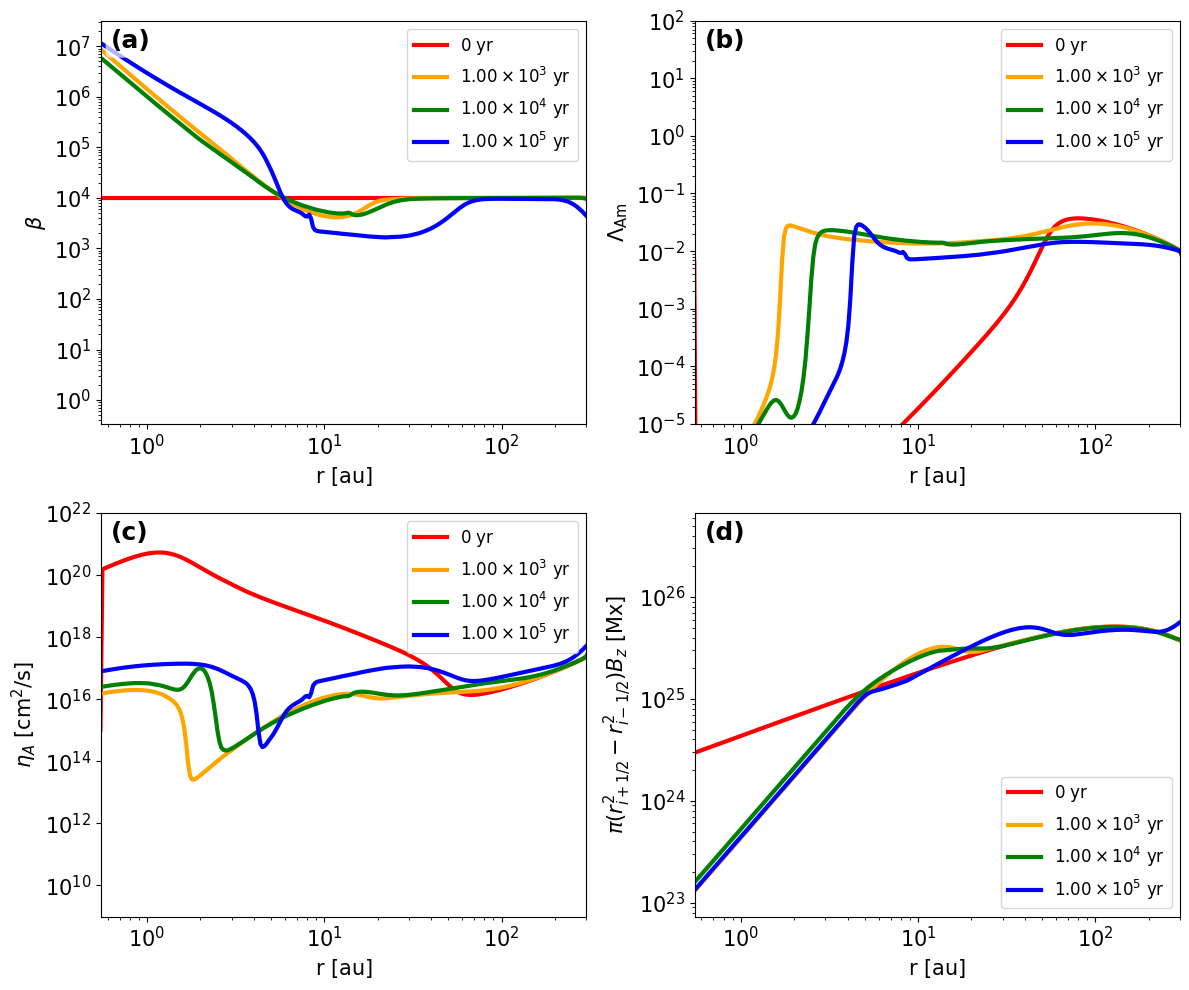

In [19]:
# [旧 cell 68]
# ======================================================
# 4 時刻でのスナップショット (2x2 ミニマップ)
#   (左上) 中心面プラズマ beta                (右上) 両極性拡散の Elsasser 数 Lambda_Am = V_A^2 / (eta_A Omega)
#   (左下) 両極性拡散係数 eta_A               (右下) 各セルの円環での磁束 pi (r_bod[i+1]^2 - r_bod[i]^2) B_z
# Lambda_Am は cell 6 と同じ定義: V_A^2 = B_z^2 / (4 pi rho_mid), rho_mid = Sigma_g / (sqrt(2 pi) H_g), H_g = c_s / Omega
#   c_s = sqrt(k_B T / (mu m_H)), Omega = sqrt(G M_sun / r^3)
# eta_A は出力の etaA_R (eta_max の上限なし)
# t = 0 の beta は出力値ではなく初期条件の beta_ini で固定して描く
# cell 63 の years, path_gas, path_mag, FIG_DIR, r_min, r_max を使う (先に cell 63 を実行する)
# t_snap に最も近い出力時刻を使い, 凡例にはその出力時刻を表示する
# file_gas 列: 0:r_cen 1:sigmag 12:T     file_mag 列: 2:B_z 4:etaA_R 5:beta_disk
# ======================================================
Msolar = 1.989000e+33
G = 6.67408e-08
kB = 1.38064852e-16
mH = 1.67353e-24
mu = 2.34

t_snap = SNAP_YEARS
colors = SNAP_COLORS
beta_ini = 1.0e4                           # 初期のプラズマ beta (t = 0 で固定)


fig, axes = plt.subplots(2, 2, figsize=(12, 10))
panels = [(axes[0, 0], r"$ \beta $"),
          (axes[0, 1], r"$ \mathrm{\Lambda_{Am}} $"),
          (axes[1, 0], r"$ \eta_A \ \rm{[cm^2/s]}$"),
          (axes[1, 1], r"$ \pi (r_{i+1/2}^2 - r_{i-1/2}^2) B_z \ \rm{[Mx]}$")]
for ax, ylabel in panels:
    ax.set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
    ax.set_ylabel(ylabel, fontsize=15)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(r_min, r_max)
    ax.tick_params(labelsize=15)
axes[0, 1].set_ylim(1.0e-5, 1.0e2)
axes[1, 0].set_ylim(1.0e9, 1.0e22)

for ts, color in zip(t_snap, colors):
    year = min(years, key=lambda y: abs(y - ts))
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 1, 12))
    r, sig, T = gas[:, 0], gas[:, 1], gas[:, 2]
    mag = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(2, 4, 5))
    B, etaA, beta = mag[:, 0], mag[:, 1], mag[:, 2]
    if year == 0:
        beta = np.full_like(r, beta_ini)

    omega = np.sqrt(G * Msolar / r**3)
    cs = np.sqrt(kB * T / (mu * mH))
    Hg = cs / omega
    rho_mid = sig / (np.sqrt(2.0 * np.pi) * Hg)
    VA_2 = B**2 / (4.0 * np.pi * rho_mid)
    Lambda_Am = VA_2 / (etaA * omega)

    # log grid: r_cen = sqrt(r_bod[i]*r_bod[i+1])
    q = r[1] / r[0]
    r_bod = np.append(r / np.sqrt(q), r[-1] * np.sqrt(q))
    flux_cell = np.pi * (r_bod[1:]**2 - r_bod[:-1]**2) * B

    label = snap_label(year)
    axes[0, 0].plot(r / AU, beta, color=color, linestyle="solid", lw=3, label=label)
    axes[0, 1].plot(r / AU, Lambda_Am, color=color, linestyle="solid", lw=3, label=label)
    axes[1, 0].plot(r / AU, etaA, color=color, linestyle="solid", lw=3, label=label)
    axes[1, 1].plot(r / AU, flux_cell, color=color, linestyle="solid", lw=3, label=label)

for ax in axes.flat:
    ax.legend(fontsize=12, loc="best")
plt.tight_layout()
# plt.savefig(fig_path("beta_LambdaAm_etaA_flux_snap.png", root=ANALYSIS_FIG_DIR))
plt.show()

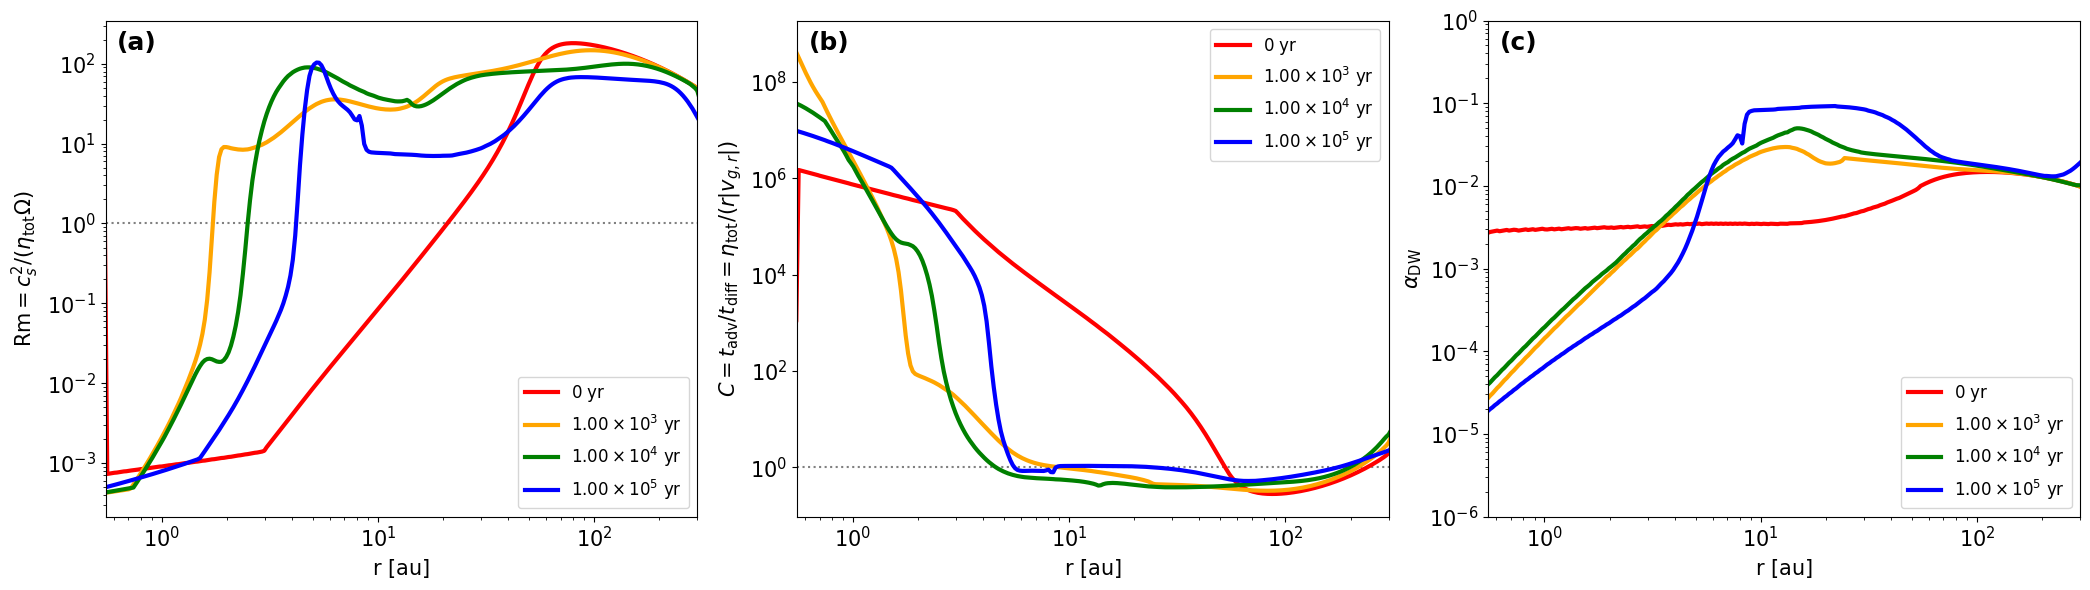

In [20]:
# [旧 cell 69]
# ======================================================
# 4 時刻でのスナップショット (1x3 ミニマップ)
#   (左) 磁気レイノルズ数 Rm = c_s H_g / eta_tot = c_s^2 / (eta_tot Omega)
#   (中) C = t_adv / t_diff = eta_tot / (r |v_g,r|)   (cell 60 と同じ定義: t_adv = r/|v_g,r| , t_diff = r^2/eta_tot)
#   (右) alpha_DW (Enomoto et al. 2026. コードの alpha_DW_. alpha_phiz = 0.75 sqrt(2 pi) (H_g/r) alpha_DW ではない)
# eta_tot = min(etaO_R + etaA_R, eta_max)   (use_eta_cap = True: コードと同じ. eta_max は input から読む)
# v_g,r はなましをかけない (cell 60 と同じ)
# c_s = sqrt(k_B T / (mu m_H)), Omega = sqrt(G M_star / r^3)  (M_star は input から読む)
# Rm, C のパネルに Rm = 1, C = 1 の線 (灰色点線) を描く
# alpha_DW = 0 (活性層なし) のセルは描かない
# cell 66 の years, path_gas, path_mag, FIG_DIR, r_min, r_max を使う (先に cell 66 を実行する)
# t_snap に最も近い出力時刻を使い, 凡例にはその出力時刻を表示する
# file_gas 列: 0:r_cen 4:vg_r 12:T 24:alpha_DW     file_mag 列: 3:etaO_R 4:etaA_R
# ======================================================

Msolar = 1.989000e+33
G = 6.67408e-08
kB = 1.38064852e-16
mH = 1.67353e-24
mu = 2.34

t_snap = SNAP_YEARS
colors = SNAP_COLORS
use_eta_cap = True   # True: eta_tot を eta_max (input) で上限 (コードと同じ), False: 上限なし

# eta_max, M_star は計算時の input から読む
eta_max = 1.0e20
M_star = Msolar
with open(path_gas + "/input") as f:
    for line in f:
        key = line.split("//")[0].split("=")[0].strip()
        if key == "eta_max":
            eta_max = float(line.split("//")[0].split("=")[1])
        elif key == "star_mass":
            M_star = float(line.split("//")[0].split("=")[1]) * Msolar


fig, axes = plt.subplots(1, 3, figsize=(21, 6))
panels = [(axes[0], r"$ \mathrm{Rm} = c_s^2 / (\eta_{\rm tot} \Omega) $"),
          (axes[1], r"$ C = t_{\rm adv} / t_{\rm diff} = \eta_{\rm tot} / (r |v_{g,r}|) $"),
          (axes[2], r"$ \alpha_{\rm DW} $")]
for ax, ylabel in panels:
    ax.set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
    ax.set_ylabel(ylabel, fontsize=15)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(r_min, r_max)
    ax.tick_params(labelsize=15)
for ax in axes[:2]:
    ax.axhline(1.0, color="gray", lw=1.5, ls="dotted")
# axes[1].set_ylim(1.0e-1, 1.0e0)
# axes[1].set_yscale("linear")
axes[2].set_ylim(1.0e-6, 1.0e0)

for ts, color in zip(t_snap, colors):
    year = min(years, key=lambda y: abs(y - ts))
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 4, 12, 24))
    r, vgr, T, alpha_DW = gas[:, 0], gas[:, 1], gas[:, 2], gas[:, 3]
    mag = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(3, 4))
    etaO, etaA = mag[:, 0], mag[:, 1]
    eta = np.minimum(etaO + etaA, eta_max) if use_eta_cap else etaO + etaA

    omega = np.sqrt(G * M_star / r**3)
    cs = np.sqrt(kB * T / (mu * mH))
    Rm = cs**2 / (eta * omega)
    vgr = vgr
    with np.errstate(divide="ignore", invalid="ignore"):
        C = eta / (r * np.abs(vgr))

    label = snap_label(year)
    axes[0].plot(r / AU, Rm, color=color, linestyle="solid", lw=3, label=label)
    axes[1].plot(r / AU, C, color=color, linestyle="solid", lw=3, label=label)
    axes[2].plot(r / AU, np.where(alpha_DW > 0.0, alpha_DW, np.nan), color=color, linestyle="solid", lw=3, label=label)

for ax in axes.flat:
    ax.legend(fontsize=12, loc="best")
plt.tight_layout()
plt.savefig(fig_path("Rm_C_snap.png", root=ANALYSIS_FIG_DIR))
plt.show()